In [24]:
import pandas as pd 
import numpy as np
#importo le librerie per scaricarmi il primo file
import requests
import urllib3
from io import StringIO
#importo le librerie per eventuali grafici
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
#importo libreria x clustering
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans



In [25]:
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
url = 'https://esploradati.istat.it/SDMXWS/rest/data/41_983'
headers = {'Accept': 'application/vnd.sdmx.data+csv;version=1.0.0'}

In [26]:
# eseguo richiesta HTTP
r = requests.get(url, headers=headers ,verify=False)

In [27]:
r.status_code

200

In [28]:
#apro il csv
df1 = pd.read_csv(StringIO(r.text))
df1

,DATAFLOW,FREQ,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,1001,KILLINJ,F,2001,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,1001,KILLINJ,F,2002,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,1001,KILLINJ,F,2003,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,1001,KILLINJ,F,2004,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,1001,KILLINJ,F,2005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
592630,IT1:41_983(1.0),A,111107,ROADACC,9,2021,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592631,IT1:41_983(1.0),A,111107,ROADACC,9,2022,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592632,IT1:41_983(1.0),A,111107,ROADACC,9,2023,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592633,IT1:41_983(1.0),A,111107,ROADACC,9,2024,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#mi salvo le statistiche sugli incidenti per non dover ogni volta fare la richiesta. QUANDO HO SALVATO IL FILE NON ERANO 592.635 RIGHE, bensì 573.552, ora che l'ho rilanciato prima di consegnare sono aumentate. Tengo il file che mi ero scaricato 2 settimane fa!!
#df1.to_csv('Statistiche_incidenti_stradali.csv', index =False)

In [31]:
#apro il file statistiche incidenti che mi sono salvato dopo aver richiamato l'API
df1 = pd.read_csv('Statistiche_incidenti_stradali.csv')
df1


,DATAFLOW,FREQ,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,1001,KILLINJ,F,2001,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,1001,KILLINJ,F,2002,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,1001,KILLINJ,F,2003,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,1001,KILLINJ,F,2004,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,1001,KILLINJ,F,2005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573547,IT1:41_983(1.0),A,111107,ROADACC,9,2020,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573548,IT1:41_983(1.0),A,111107,ROADACC,9,2021,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573549,IT1:41_983(1.0),A,111107,ROADACC,9,2022,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573550,IT1:41_983(1.0),A,111107,ROADACC,9,2023,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
#rinomino le colonne
df1 = df1.rename(columns={'REF_AREA':'Comune','DATA_TYPE': 'Tipo_incidente', 'RESULT' : 'Tipo_infortunio', 'TIME_PERIOD':'Anno', 'OBS_VALUE':'N_osservazioni' })
df1


,DATAFLOW,FREQ,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,1001,KILLINJ,F,2001,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,1001,KILLINJ,F,2002,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,1001,KILLINJ,F,2003,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,1001,KILLINJ,F,2004,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,1001,KILLINJ,F,2005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573547,IT1:41_983(1.0),A,111107,ROADACC,9,2020,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573548,IT1:41_983(1.0),A,111107,ROADACC,9,2021,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573549,IT1:41_983(1.0),A,111107,ROADACC,9,2022,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573550,IT1:41_983(1.0),A,111107,ROADACC,9,2023,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
df1 = df1[['Comune', 'Tipo_incidente','Tipo_infortunio', 'Anno', 'N_osservazioni']].copy()
df1


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni
0,1001,KILLINJ,F,2001,10
1,1001,KILLINJ,F,2002,10
2,1001,KILLINJ,F,2003,7
3,1001,KILLINJ,F,2004,13
4,1001,KILLINJ,F,2005,2
...,...,...,...,...,...
573547,111107,ROADACC,9,2020,2
573548,111107,ROADACC,9,2021,5
573549,111107,ROADACC,9,2022,1
573550,111107,ROADACC,9,2023,4


In [34]:
df1['Tipo_incidente'].unique()


array(['KILLINJ', 'ROADACC'], dtype=object)

In [35]:
#rinomino il contenuto di Tipo_incidente
df1['Tipo_incidente'] = df1['Tipo_incidente'].replace({'KILLINJ':'Morti e Feriti', 'ROADACC':'Incidenti stradali con lesioni'})
df1


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni
0,1001,Morti e Feriti,F,2001,10
1,1001,Morti e Feriti,F,2002,10
2,1001,Morti e Feriti,F,2003,7
3,1001,Morti e Feriti,F,2004,13
4,1001,Morti e Feriti,F,2005,2
...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,9,2020,2
573548,111107,Incidenti stradali con lesioni,9,2021,5
573549,111107,Incidenti stradali con lesioni,9,2022,1
573550,111107,Incidenti stradali con lesioni,9,2023,4


In [36]:
df1['Tipo_infortunio'].unique()


array(['F', 'M', '9'], dtype=object)

In [37]:
#rinomino il contenuto di Tipo_infortunio
df1['Tipo_infortunio'] = df1['Tipo_infortunio'].replace({'F':'Feriti', 'M':'Morti', '9': 'Totale'})
df1


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni
0,1001,Morti e Feriti,Feriti,2001,10
1,1001,Morti e Feriti,Feriti,2002,10
2,1001,Morti e Feriti,Feriti,2003,7
3,1001,Morti e Feriti,Feriti,2004,13
4,1001,Morti e Feriti,Feriti,2005,2
...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2
573548,111107,Incidenti stradali con lesioni,Totale,2021,5
573549,111107,Incidenti stradali con lesioni,Totale,2022,1
573550,111107,Incidenti stradali con lesioni,Totale,2023,4


In [38]:
#APRO il file con le statistiche comunali
#creo il ciclo per aprire tutti i file e creo una colonna con anno di riferimento
df2_lista = []

for anno in range(2001,2026):
    df2_da_lista = pd.read_csv(f'Statistiche/Comuni - Dimensione Data Indagine 01-01-{anno}.csv', sep = ';')
    df2_da_lista['Anno_csv'] = anno
    df2_lista.append(df2_da_lista)
df2 = pd.concat(df2_lista, ignore_index = True)


In [39]:
#lo salvo
#df2.to_excel('Statistiche_comuni.xlsx', index = False)


In [40]:
df2 = pd.read_excel('Statistiche_comuni.xlsx')
df2


,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico)
0,1,1,1,1001,1001,Agliè,NaN,TO,0,0,2623.0,1991,2001,NaN,NaN,NaN,NaN,NaN
1,1,1,1,1002,1002,Airasca,NaN,TO,0,0,3252.0,1991,2001,NaN,NaN,NaN,NaN,NaN
2,1,1,1,1003,1003,Ala di Stura,NaN,TO,0,0,503.0,1991,2001,NaN,NaN,NaN,NaN,NaN
3,1,1,1,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1701.0,1991,2001,NaN,NaN,NaN,NaN,NaN
4,1,1,1,1005,1005,Alice Superiore,NaN,TO,0,0,601.0,1991,2001,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200672,5,20,111,111103,111103,Villaputzu,NaN,SU,0,0,4509.0,2021,2025,181.3947,2025.0,4368.0,2024.0,111.0
200673,5,20,111,111104,111104,Villasalto,NaN,SU,0,0,989.0,2021,2025,130.3596,2025.0,903.0,2024.0,111.0
200674,5,20,111,111105,111105,Villasimius,NaN,SU,0,0,3705.0,2021,2025,58.1781,2025.0,3735.0,2024.0,111.0
200675,5,20,111,111106,111106,Villasor,NaN,SU,0,0,6599.0,2021,2025,86.8137,2025.0,6534.0,2024.0,111.0


In [41]:
#inserisco le colonne che mi interessano, per ora SOLO il nome del comune
diz_codice = df2.set_index('Codice Comune (numerico)')['Comune'].to_dict()
df1['Nome_Comune'] = df1['Comune'].map(diz_codice)
df1


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune
0,1001,Morti e Feriti,Feriti,2001,10,Agliè
1,1001,Morti e Feriti,Feriti,2002,10,Agliè
2,1001,Morti e Feriti,Feriti,2003,7,Agliè
3,1001,Morti e Feriti,Feriti,2004,13,Agliè
4,1001,Morti e Feriti,Feriti,2005,2,Agliè
...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa


In [42]:
#ci sono nomi comuni vuoit?
df1[df1['Nome_Comune'].isna()]

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune
11838,1168,Morti e Feriti,Feriti,2001,23,NaN
11839,1168,Morti e Feriti,Feriti,2002,46,NaN
11840,1168,Morti e Feriti,Feriti,2003,25,NaN
11841,1168,Morti e Feriti,Feriti,2004,29,NaN
11842,1168,Morti e Feriti,Feriti,2005,20,NaN
...,...,...,...,...,...,...
11905,1168,Incidenti stradali con lesioni,Totale,2020,8,NaN
11906,1168,Incidenti stradali con lesioni,Totale,2021,9,NaN
11907,1168,Incidenti stradali con lesioni,Totale,2022,7,NaN
11908,1168,Incidenti stradali con lesioni,Totale,2023,7,NaN


In [43]:
#inserisco il nome a mano (comune=None, provincia=Torino)
df1.loc[df1['Nome_Comune'].isna(), 'Nome_Comune'] = 'None'
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune
0,1001,Morti e Feriti,Feriti,2001,10,Agliè
1,1001,Morti e Feriti,Feriti,2002,10,Agliè
2,1001,Morti e Feriti,Feriti,2003,7,Agliè
3,1001,Morti e Feriti,Feriti,2004,13,Agliè
4,1001,Morti e Feriti,Feriti,2005,2,Agliè
...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa


In [44]:
#controllo
df1[df1['Nome_Comune'].isna()]

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune


In [45]:
#PICCOLA ANALISI STATISTICA SU df1-2
df1.shape

(573552, 6)

In [46]:
df1.describe()

,Comune,Anno,N_osservazioni
count,573552.000000,573552.000000,573552.000000
mean,44528.628771,2012.340541,20.207603
std,32093.886203,6.859876,245.813966
min,1001.000000,2001.000000,0.000000
25%,16137.000000,2006.000000,0.000000
50%,38012.500000,2012.000000,1.000000
75%,71052.000000,2018.000000,8.000000
max,111107.000000,2024.000000,30254.000000


In [47]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 573552 entries, 0 to 573551
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Comune           573552 non-null  int64 
 1   Tipo_incidente   573552 non-null  object
 2   Tipo_infortunio  573552 non-null  object
 3   Anno             573552 non-null  int64 
 4   N_osservazioni   573552 non-null  int64 
 5   Nome_Comune      573552 non-null  object
dtypes: int64(3), object(3)
memory usage: 26.3+ MB


In [48]:
#guardo la moda per le osservazioni
df1['N_osservazioni'].mode(0)
#non mi sconvolge che il numero di osservazioni sia 0, poichè è probabile che in certi comuni non ci siano stati incidenti

0    0
Name: N_osservazioni, dtype: int64

In [49]:
df1['N_osservazioni'].median()

1.0

In [50]:
#calcolo l'intervallo interquartile, non soggetto a outlier, per farmi un' idea della distribuzione delle osservazioni
q1 = df1['N_osservazioni'].quantile(0.25)
q3 = df1['N_osservazioni'].quantile(0.75)
intervallo = q3-q1
intervallo

8.0

<Axes: xlabel='N_osservazioni', ylabel='Tipo_incidente'>

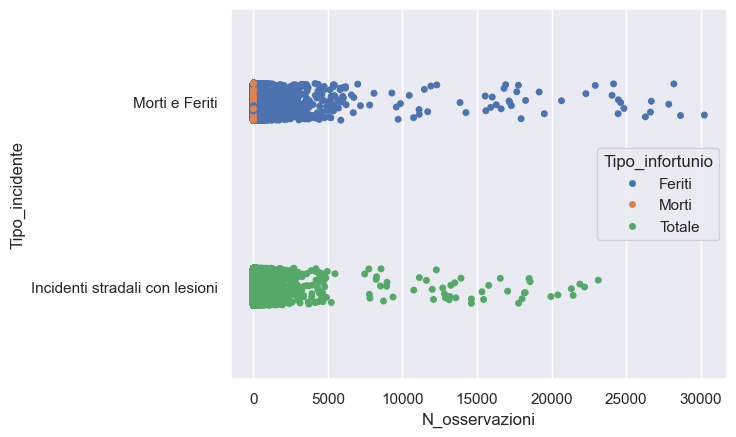

In [51]:
#analizzo gli outlier con un boxplot
sns.stripplot(x = 'N_osservazioni', y = 'Tipo_incidente', hue='Tipo_infortunio', data = df1)

/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


<Axes: xlabel='N_osservazioni', ylabel='Tipo_incidente'>

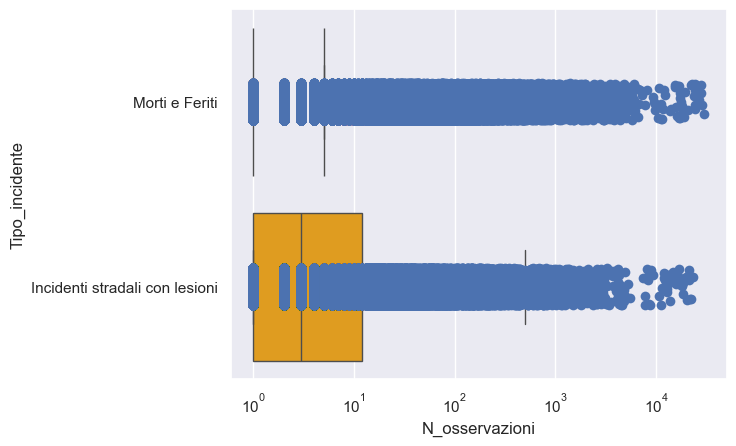

In [52]:
sns.boxplot(data=df1, x='N_osservazioni', y='Tipo_incidente',
            fliersize=0, color='orange', log_scale=True)
sns.stripplot(data=df1, x='N_osservazioni', y='Tipo_incidente', size=7)

In [53]:
#guardo se gli outlier sono corretti
df1.sort_values(by = 'N_osservazioni', ascending = False).head(30)
#guardando i valori, fanno riferimento tutti ad incidenti avvenuti effettivamente in qualche città (di grandi dimensioni), perciò posso considerarli validi.
#inoltre, c'è da sottolineare come nel dataframe in oggetto, la colonna 'Tipo_incidente' unisce due tipi di dati differenti: morti e feriti con Incidenti stradali con lesioni.
#in questo caso, quando mi appresterò a fare l'analisi, suddividerò le due nuove categorie.

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune
348588,58091,Morti e Feriti,Feriti,2004,30254,Roma
348589,58091,Morti e Feriti,Feriti,2005,28653,Roma
348590,58091,Morti e Feriti,Feriti,2006,28209,Roma
348585,58091,Morti e Feriti,Feriti,2001,27865,Roma
348586,58091,Morti e Feriti,Feriti,2002,26696,Roma
348587,58091,Morti e Feriti,Feriti,2003,26638,Roma
348591,58091,Morti e Feriti,Feriti,2007,26299,Roma
128817,15146,Morti e Feriti,Feriti,2001,24858,Milano
348593,58091,Morti e Feriti,Feriti,2009,24638,Roma
128818,15146,Morti e Feriti,Feriti,2002,24487,Milano


In [54]:
gruppo_tipo_inc =df1.pivot_table(index = 'Anno', columns = 'Tipo_incidente', values = 'N_osservazioni', aggfunc = 'sum').reset_index()
gruppo_tipo_inc

Tipo_incidente,Anno,Incidenti stradali con lesioni,Morti e Feriti
0,2001,263100,380382
1,2002,265402,385471
2,2003,252271,363038
3,2004,243490,349301
4,2005,240011,340676
5,2006,238124,338624
6,2007,230871,330981
7,2008,218963,315470
8,2009,215405,311495
9,2010,212997,308834


Text(0.5, 1.0, 'Distribuzione x anno incidenti con lesioni')

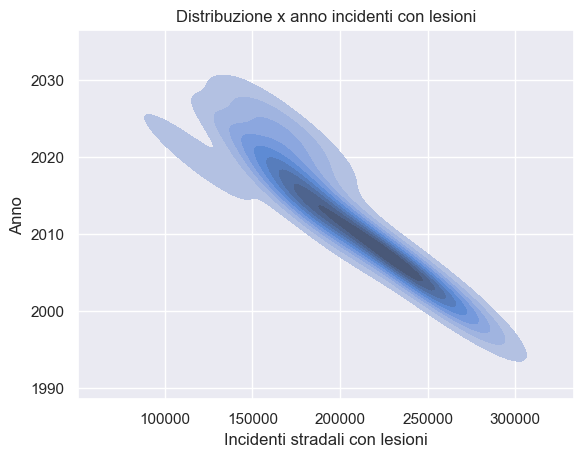

In [55]:
#guardo x incidenti stradali con lesioni:
sns.kdeplot(x = 'Incidenti stradali con lesioni', y = 'Anno', data = gruppo_tipo_inc, fill=True,).set_title("Distribuzione x anno incidenti con lesioni")

Text(0.5, 1.0, 'Distribuzione x anno incidenti con lesioni')

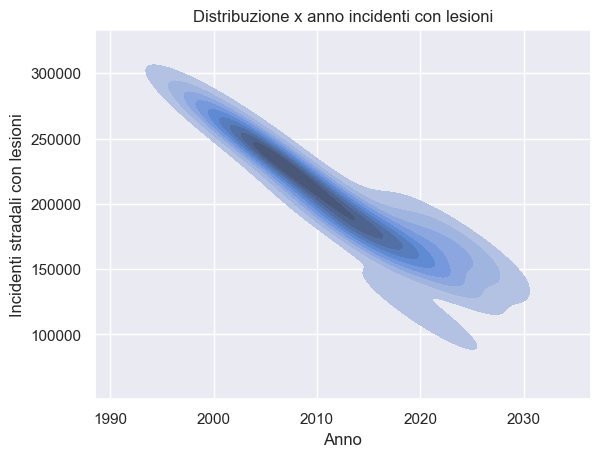

In [56]:
sns.kdeplot(x = 'Anno', y = 'Incidenti stradali con lesioni', data = gruppo_tipo_inc, fill=True,).set_title("Distribuzione x anno incidenti con lesioni")

<Axes: xlabel='Anno', ylabel='Incidenti stradali con lesioni'>

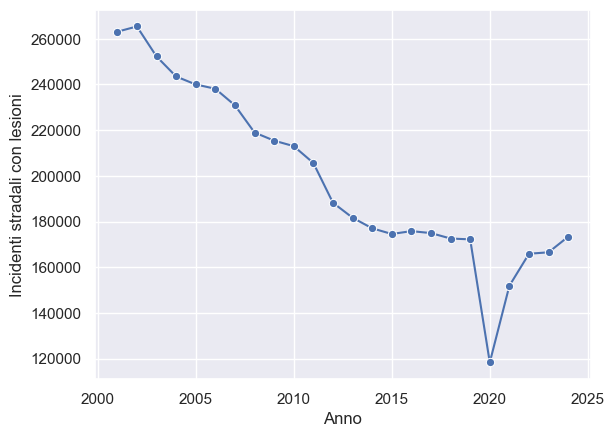

In [57]:
sns.lineplot(x='Anno', y='Incidenti stradali con lesioni', data=gruppo_tipo_inc,  marker='o')
#notiamo che nel corso degli anni, gli incidenti sono DIMINUITI, Inoltre nel 2020 c'è una brusca diminuzione, non tanto dovuta ad errori di rilevazioni, bensì
#all'evento del COVID, dove per quasi tutto l'anno ci sono state limitazioni nei movimenti in macchina.

Text(0.5, 1.0, 'Distribuzione x anno morti e feriti')

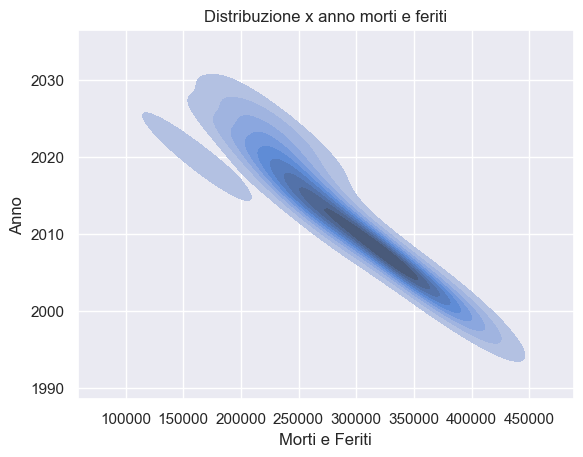

In [58]:
#guardo x MORTI e FERITI
sns.kdeplot(x = 'Morti e Feriti', y = 'Anno', data = gruppo_tipo_inc, fill=True,).set_title("Distribuzione x anno morti e feriti")

Text(0.5, 1.0, 'Distribuzione x anno morti e feriti')

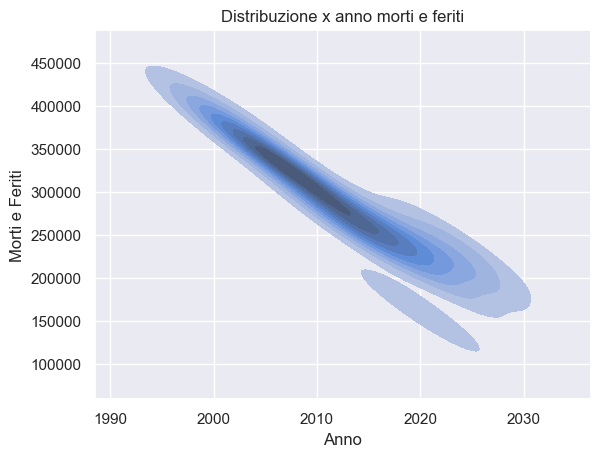

In [59]:
sns.kdeplot(x = 'Anno', y = 'Morti e Feriti', data = gruppo_tipo_inc, fill=True,).set_title("Distribuzione x anno morti e feriti")

<Axes: xlabel='Anno', ylabel='Morti e Feriti'>

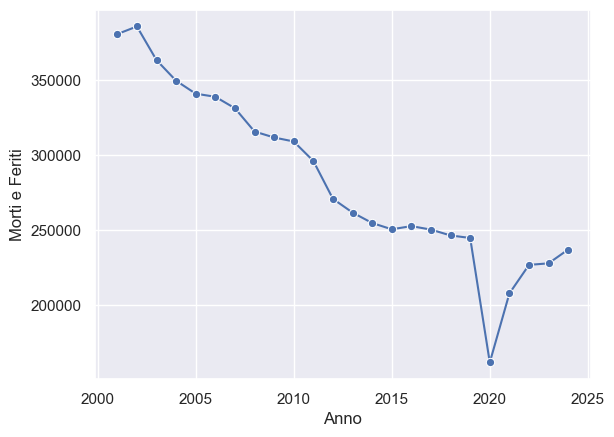

In [60]:
sns.lineplot(data=gruppo_tipo_inc, x='Anno', y='Morti e Feriti', marker='o')

In [61]:
#mi piacerebbe avere su df1, la REGIONE e la PROVINCIA:
#1)
from selenium import webdriver
import os

In [62]:
driver = webdriver.Chrome()


In [63]:
driver.get("https://www.gardainformatica.it/database-comuni-italiani#scarica")


In [64]:
from selenium.webdriver.common.by import By


In [65]:
driver.find_element(By.LINK_TEXT, "Scarica il database dei comuni italiani").click()


In [66]:
#apro il file che ho scaricato
df_comuni = pd.read_excel('gi_comuni_cap.xlsx')
df_comuni


,Database Comuni Cap by gardainformatica.it,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,codice_istat,denominazione_ita_altra,denominazione_ita,denominazione_altra,cap,sigla_provincia,denominazione_provincia,tipologia_provincia,codice_regione,denominazione_regione,tipologia_regione,ripartizione_geografica,flag_capoluogo,codice_belfiore,lat,lon,superficie_kmq
1,028001,Abano Terme,Abano Terme,NaN,35031,PD,Padova,provincia,05,Veneto,statuto ordinario,Nord-est,NO,A001,45.359374,11.788694,21.3082
2,098001,Abbadia Cerreto,Abbadia Cerreto,NaN,26834,LO,Lodi,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A004,45.312306,9.592549,6.3958
3,097001,Abbadia Lariana,Abbadia Lariana,NaN,23821,LC,Lecco,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A005,45.899204,9.332069,16.4678
4,052001,Abbadia San Salvatore,Abbadia San Salvatore,NaN,53021,SI,Siena,provincia,09,Toscana,statuto ordinario,Centro,NO,A006,42.88096,11.677251,58.8852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8454,030136,Zuglio,Zuglio,NaN,33020,UD,Udine,unita non amministrativa,06,Friuli-Venezia Giulia,statuto speciale,Nord-est,NO,M200,46.460918,13.02614,18.3158
8455,096083,Zumaglia,Zumaglia,NaN,13848,BI,Biella,provincia,01,Piemonte,statuto ordinario,Nord-ovest,NO,M201,45.59475,8.088672,2.802
8456,078155,Zumpano,Zumpano,NaN,87040,CS,Cosenza,provincia,18,Calabria,statuto ordinario,Sud,NO,M202,39.310845,16.291248,8.201
8457,064120,Zungoli,Zungoli,NaN,83030,AV,Avellino,provincia,15,Campania,statuto ordinario,Sud,NO,M203,41.128913,15.202135,19.273


In [67]:
#chiamo le colonne come la riga in index=0
df_comuni.columns = df_comuni.iloc[0]
df_comuni


,codice_istat,denominazione_ita_altra,denominazione_ita,denominazione_altra,cap,sigla_provincia,denominazione_provincia,tipologia_provincia,codice_regione,denominazione_regione,tipologia_regione,ripartizione_geografica,flag_capoluogo,codice_belfiore,lat,lon,superficie_kmq
0,codice_istat,denominazione_ita_altra,denominazione_ita,denominazione_altra,cap,sigla_provincia,denominazione_provincia,tipologia_provincia,codice_regione,denominazione_regione,tipologia_regione,ripartizione_geografica,flag_capoluogo,codice_belfiore,lat,lon,superficie_kmq
1,028001,Abano Terme,Abano Terme,NaN,35031,PD,Padova,provincia,05,Veneto,statuto ordinario,Nord-est,NO,A001,45.359374,11.788694,21.3082
2,098001,Abbadia Cerreto,Abbadia Cerreto,NaN,26834,LO,Lodi,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A004,45.312306,9.592549,6.3958
3,097001,Abbadia Lariana,Abbadia Lariana,NaN,23821,LC,Lecco,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A005,45.899204,9.332069,16.4678
4,052001,Abbadia San Salvatore,Abbadia San Salvatore,NaN,53021,SI,Siena,provincia,09,Toscana,statuto ordinario,Centro,NO,A006,42.88096,11.677251,58.8852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8454,030136,Zuglio,Zuglio,NaN,33020,UD,Udine,unita non amministrativa,06,Friuli-Venezia Giulia,statuto speciale,Nord-est,NO,M200,46.460918,13.02614,18.3158
8455,096083,Zumaglia,Zumaglia,NaN,13848,BI,Biella,provincia,01,Piemonte,statuto ordinario,Nord-ovest,NO,M201,45.59475,8.088672,2.802
8456,078155,Zumpano,Zumpano,NaN,87040,CS,Cosenza,provincia,18,Calabria,statuto ordinario,Sud,NO,M202,39.310845,16.291248,8.201
8457,064120,Zungoli,Zungoli,NaN,83030,AV,Avellino,provincia,15,Campania,statuto ordinario,Sud,NO,M203,41.128913,15.202135,19.273


In [68]:
#faccio reset index e rimuovo la 'doppia riga'
df_comuni = df_comuni.iloc[1:].reset_index(drop=True)
df_comuni


,codice_istat,denominazione_ita_altra,denominazione_ita,denominazione_altra,cap,sigla_provincia,denominazione_provincia,tipologia_provincia,codice_regione,denominazione_regione,tipologia_regione,ripartizione_geografica,flag_capoluogo,codice_belfiore,lat,lon,superficie_kmq
0,028001,Abano Terme,Abano Terme,NaN,35031,PD,Padova,provincia,05,Veneto,statuto ordinario,Nord-est,NO,A001,45.359374,11.788694,21.3082
1,098001,Abbadia Cerreto,Abbadia Cerreto,NaN,26834,LO,Lodi,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A004,45.312306,9.592549,6.3958
2,097001,Abbadia Lariana,Abbadia Lariana,NaN,23821,LC,Lecco,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A005,45.899204,9.332069,16.4678
3,052001,Abbadia San Salvatore,Abbadia San Salvatore,NaN,53021,SI,Siena,provincia,09,Toscana,statuto ordinario,Centro,NO,A006,42.88096,11.677251,58.8852
4,115001,Abbasanta,Abbasanta,NaN,09071,OR,Oristano,provincia,20,Sardegna,statuto speciale,Isole,NO,A007,40.123843,8.821049,39.8155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8453,030136,Zuglio,Zuglio,NaN,33020,UD,Udine,unita non amministrativa,06,Friuli-Venezia Giulia,statuto speciale,Nord-est,NO,M200,46.460918,13.02614,18.3158
8454,096083,Zumaglia,Zumaglia,NaN,13848,BI,Biella,provincia,01,Piemonte,statuto ordinario,Nord-ovest,NO,M201,45.59475,8.088672,2.802
8455,078155,Zumpano,Zumpano,NaN,87040,CS,Cosenza,provincia,18,Calabria,statuto ordinario,Sud,NO,M202,39.310845,16.291248,8.201
8456,064120,Zungoli,Zungoli,NaN,83030,AV,Avellino,provincia,15,Campania,statuto ordinario,Sud,NO,M203,41.128913,15.202135,19.273


In [69]:
df_comuni.columns.name = None  
df_comuni 


,codice_istat,denominazione_ita_altra,denominazione_ita,denominazione_altra,cap,sigla_provincia,denominazione_provincia,tipologia_provincia,codice_regione,denominazione_regione,tipologia_regione,ripartizione_geografica,flag_capoluogo,codice_belfiore,lat,lon,superficie_kmq
0,028001,Abano Terme,Abano Terme,NaN,35031,PD,Padova,provincia,05,Veneto,statuto ordinario,Nord-est,NO,A001,45.359374,11.788694,21.3082
1,098001,Abbadia Cerreto,Abbadia Cerreto,NaN,26834,LO,Lodi,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A004,45.312306,9.592549,6.3958
2,097001,Abbadia Lariana,Abbadia Lariana,NaN,23821,LC,Lecco,provincia,03,Lombardia,statuto ordinario,Nord-ovest,NO,A005,45.899204,9.332069,16.4678
3,052001,Abbadia San Salvatore,Abbadia San Salvatore,NaN,53021,SI,Siena,provincia,09,Toscana,statuto ordinario,Centro,NO,A006,42.88096,11.677251,58.8852
4,115001,Abbasanta,Abbasanta,NaN,09071,OR,Oristano,provincia,20,Sardegna,statuto speciale,Isole,NO,A007,40.123843,8.821049,39.8155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8453,030136,Zuglio,Zuglio,NaN,33020,UD,Udine,unita non amministrativa,06,Friuli-Venezia Giulia,statuto speciale,Nord-est,NO,M200,46.460918,13.02614,18.3158
8454,096083,Zumaglia,Zumaglia,NaN,13848,BI,Biella,provincia,01,Piemonte,statuto ordinario,Nord-ovest,NO,M201,45.59475,8.088672,2.802
8455,078155,Zumpano,Zumpano,NaN,87040,CS,Cosenza,provincia,18,Calabria,statuto ordinario,Sud,NO,M202,39.310845,16.291248,8.201
8456,064120,Zungoli,Zungoli,NaN,83030,AV,Avellino,provincia,15,Campania,statuto ordinario,Sud,NO,M203,41.128913,15.202135,19.273


In [70]:
diz_provincia = df_comuni.set_index('denominazione_ita')['denominazione_provincia'].to_dict()
df1['Provincia'] = df1['Nome_Comune'].map(diz_provincia)
df1 


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Provincia
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Torino
1,1001,Morti e Feriti,Feriti,2002,10,Agliè,Torino
2,1001,Morti e Feriti,Feriti,2003,7,Agliè,Torino
3,1001,Morti e Feriti,Feriti,2004,13,Agliè,Torino
4,1001,Morti e Feriti,Feriti,2005,2,Agliè,Torino
...,...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa,Cagliari
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa,Cagliari
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa,Cagliari
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa,Cagliari


In [71]:
df1['Provincia'].isna().sum()


24594

In [72]:
df1[df1['Provincia'].isna()]
#purtoppo vedo che non mi trova alcune province, quindi il file non va bene. elimino la colonna e importo un altro csv.


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Provincia
288,1005,Morti e Feriti,Feriti,2001,3,Alice Superiore,NaN
289,1005,Morti e Feriti,Feriti,2002,1,Alice Superiore,NaN
290,1005,Morti e Feriti,Feriti,2003,1,Alice Superiore,NaN
291,1005,Morti e Feriti,Feriti,2004,2,Alice Superiore,NaN
292,1005,Morti e Feriti,Feriti,2005,0,Alice Superiore,NaN
...,...,...,...,...,...,...,...
562708,103073,Incidenti stradali con lesioni,Totale,2011,0,Viganella,NaN
562709,103073,Incidenti stradali con lesioni,Totale,2012,0,Viganella,NaN
562710,103073,Incidenti stradali con lesioni,Totale,2013,0,Viganella,NaN
562711,103073,Incidenti stradali con lesioni,Totale,2014,0,Viganella,NaN


In [73]:
df1 = df1.drop(columns='Provincia')
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune
0,1001,Morti e Feriti,Feriti,2001,10,Agliè
1,1001,Morti e Feriti,Feriti,2002,10,Agliè
2,1001,Morti e Feriti,Feriti,2003,7,Agliè
3,1001,Morti e Feriti,Feriti,2004,13,Agliè
4,1001,Morti e Feriti,Feriti,2005,2,Agliè
...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa


In [74]:
#2)
#vado su un altro sito:

In [75]:
driver = webdriver.Chrome()

In [76]:
driver.get('https://www.anagrafenazionale.interno.it/area-tecnica/archivio-storico-dei-comuni/')

In [77]:
LINK = driver.find_element(By.PARTIAL_LINK_TEXT, "Scarica")

In [79]:
LINK.click()

In [80]:
#apro il file2 che ho scaricato
df_comuni2 = pd.read_csv('ANPR_archivio_comuni.csv', sep = ',')
df_comuni2

,ID,DATAISTITUZIONE,DATACESSAZIONE,CODISTAT,CODCATASTALE,DENOMINAZIONE_IT,DENOMTRASLITTERATA,ALTRADENOMINAZIONE,ALTRADENOMTRASLITTERATA,ID_PROVINCIA,IDPROVINCIAISTAT,IDREGIONE,IDPREFETTURA,STATO,SIGLAPROVINCIA,FONTE,DATAULTIMOAGG,COD_DENOM
0,12560,1866-11-19,1924-11-13,28001,A001,ABANO,ABANO,NaN,NaN,28,28,05,NaN,C,PD,NaN,2016-06-17,28500.0
1,1,1924-11-14,9999-12-31,28001,A001,ABANO TERME,ABANO TERME,NaN,NaN,28,28,05,PD,A,PD,NaN,2016-06-17,NaN
2,3,1864-04-01,1928-12-05,1801,A003,ABBADIA ALPINA,ABBADIA ALPINA,NaN,NaN,1,1,01,NaN,C,TO,NaN,2017-11-11,NaN
3,5,1861-03-17,1992-04-15,15001,A004,ABBADIA CERRETO,ABBADIA CERRETO,NaN,NaN,15,15,03,NaN,C,MI,NaN,2016-06-17,NaN
4,4,1992-04-16,9999-12-31,98001,A004,ABBADIA CERRETO,ABBADIA CERRETO,NaN,NaN,98,98,03,LO,A,LO,NaN,2016-06-17,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19359,11106,1861-03-17,9999-12-31,78155,M202,ZUMPANO,ZUMPANO,NaN,NaN,78,78,18,CS,A,CS,NaN,2016-06-17,NaN
19360,11107,1861-03-17,9999-12-31,64120,M203,ZUNGOLI,ZUNGOLI,NaN,NaN,64,64,15,AV,A,AV,NaN,2016-06-17,NaN
19361,11109,1861-03-17,1992-04-15,79159,M204,ZUNGRI,ZUNGRI,NaN,NaN,79,79,18,NaN,C,CZ,NaN,2016-06-17,NaN
19362,11108,1992-04-16,9999-12-31,102050,M204,ZUNGRI,ZUNGRI,NaN,NaN,102,102,18,VV,A,VV,NaN,2016-06-17,NaN


In [81]:
df_comuni.columns

Index(['codice_istat', 'denominazione_ita_altra', 'denominazione_ita',
       'denominazione_altra', 'cap', 'sigla_provincia',
       'denominazione_provincia', 'tipologia_provincia', 'codice_regione',
       'denominazione_regione', 'tipologia_regione', 'ripartizione_geografica',
       'flag_capoluogo', 'codice_belfiore', 'lat', 'lon', 'superficie_kmq'],
      dtype='object')

In [82]:
#pur non andando bene per il mio fine, il df_comuni almeno ha l'ID regione. me lo porto
diz_id_regione = df_comuni.set_index('codice_regione')['denominazione_regione'].to_dict()
df_comuni2['Regione'] = df_comuni2['IDREGIONE'].map(diz_id_regione)
df_comuni2

,ID,DATAISTITUZIONE,DATACESSAZIONE,CODISTAT,CODCATASTALE,DENOMINAZIONE_IT,DENOMTRASLITTERATA,ALTRADENOMINAZIONE,ALTRADENOMTRASLITTERATA,ID_PROVINCIA,IDPROVINCIAISTAT,IDREGIONE,IDPREFETTURA,STATO,SIGLAPROVINCIA,FONTE,DATAULTIMOAGG,COD_DENOM,Regione
0,12560,1866-11-19,1924-11-13,28001,A001,ABANO,ABANO,NaN,NaN,28,28,05,NaN,C,PD,NaN,2016-06-17,28500.0,Veneto
1,1,1924-11-14,9999-12-31,28001,A001,ABANO TERME,ABANO TERME,NaN,NaN,28,28,05,PD,A,PD,NaN,2016-06-17,NaN,Veneto
2,3,1864-04-01,1928-12-05,1801,A003,ABBADIA ALPINA,ABBADIA ALPINA,NaN,NaN,1,1,01,NaN,C,TO,NaN,2017-11-11,NaN,Piemonte
3,5,1861-03-17,1992-04-15,15001,A004,ABBADIA CERRETO,ABBADIA CERRETO,NaN,NaN,15,15,03,NaN,C,MI,NaN,2016-06-17,NaN,Lombardia
4,4,1992-04-16,9999-12-31,98001,A004,ABBADIA CERRETO,ABBADIA CERRETO,NaN,NaN,98,98,03,LO,A,LO,NaN,2016-06-17,NaN,Lombardia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19359,11106,1861-03-17,9999-12-31,78155,M202,ZUMPANO,ZUMPANO,NaN,NaN,78,78,18,CS,A,CS,NaN,2016-06-17,NaN,Calabria
19360,11107,1861-03-17,9999-12-31,64120,M203,ZUNGOLI,ZUNGOLI,NaN,NaN,64,64,15,AV,A,AV,NaN,2016-06-17,NaN,Campania
19361,11109,1861-03-17,1992-04-15,79159,M204,ZUNGRI,ZUNGRI,NaN,NaN,79,79,18,NaN,C,CZ,NaN,2016-06-17,NaN,Calabria
19362,11108,1992-04-16,9999-12-31,102050,M204,ZUNGRI,ZUNGRI,NaN,NaN,102,102,18,VV,A,VV,NaN,2016-06-17,NaN,Calabria


In [83]:
#Faccio la stessa cosa con SIGLAPROVINCIA di df_comuni2 su df_comuni ->sigla_provincia mappato su denominazione_provincia
diz_provincia = df_comuni.set_index('sigla_provincia')['denominazione_provincia'].to_dict()
df_comuni2['Provincia'] = df_comuni2['SIGLAPROVINCIA'].map(diz_provincia)
df_comuni2

,ID,DATAISTITUZIONE,DATACESSAZIONE,CODISTAT,CODCATASTALE,DENOMINAZIONE_IT,DENOMTRASLITTERATA,ALTRADENOMINAZIONE,ALTRADENOMTRASLITTERATA,ID_PROVINCIA,IDPROVINCIAISTAT,IDREGIONE,IDPREFETTURA,STATO,SIGLAPROVINCIA,FONTE,DATAULTIMOAGG,COD_DENOM,Regione,Provincia
0,12560,1866-11-19,1924-11-13,28001,A001,ABANO,ABANO,NaN,NaN,28,28,05,NaN,C,PD,NaN,2016-06-17,28500.0,Veneto,Padova
1,1,1924-11-14,9999-12-31,28001,A001,ABANO TERME,ABANO TERME,NaN,NaN,28,28,05,PD,A,PD,NaN,2016-06-17,NaN,Veneto,Padova
2,3,1864-04-01,1928-12-05,1801,A003,ABBADIA ALPINA,ABBADIA ALPINA,NaN,NaN,1,1,01,NaN,C,TO,NaN,2017-11-11,NaN,Piemonte,Torino
3,5,1861-03-17,1992-04-15,15001,A004,ABBADIA CERRETO,ABBADIA CERRETO,NaN,NaN,15,15,03,NaN,C,MI,NaN,2016-06-17,NaN,Lombardia,Milano
4,4,1992-04-16,9999-12-31,98001,A004,ABBADIA CERRETO,ABBADIA CERRETO,NaN,NaN,98,98,03,LO,A,LO,NaN,2016-06-17,NaN,Lombardia,Lodi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19359,11106,1861-03-17,9999-12-31,78155,M202,ZUMPANO,ZUMPANO,NaN,NaN,78,78,18,CS,A,CS,NaN,2016-06-17,NaN,Calabria,Cosenza
19360,11107,1861-03-17,9999-12-31,64120,M203,ZUNGOLI,ZUNGOLI,NaN,NaN,64,64,15,AV,A,AV,NaN,2016-06-17,NaN,Campania,Avellino
19361,11109,1861-03-17,1992-04-15,79159,M204,ZUNGRI,ZUNGRI,NaN,NaN,79,79,18,NaN,C,CZ,NaN,2016-06-17,NaN,Calabria,Catanzaro
19362,11108,1992-04-16,9999-12-31,102050,M204,ZUNGRI,ZUNGRI,NaN,NaN,102,102,18,VV,A,VV,NaN,2016-06-17,NaN,Calabria,Vibo Valentia


In [84]:
#controllo se provincia è vuota
df_comuni2[df_comuni2['Provincia'].isna()]

,ID,DATAISTITUZIONE,DATACESSAZIONE,CODISTAT,CODCATASTALE,DENOMINAZIONE_IT,DENOMTRASLITTERATA,ALTRADENOMINAZIONE,ALTRADENOMTRASLITTERATA,ID_PROVINCIA,IDPROVINCIAISTAT,IDREGIONE,IDPREFETTURA,STATO,SIGLAPROVINCIA,FONTE,DATAULTIMOAGG,COD_DENOM,Regione,Provincia
17,13,1931-12-22,1947-09-15,701701,A009,ABBAZIA,ABBAZIA,NaN,NaN,701,701,EX,NaN,C,FU,NaN,2017-07-14,NaN,NaN,NaN
55,39,1861-03-17,1998-09-03,41001,A035,ACQUALAGNA,ACQUALAGNA,NaN,NaN,601,41,11,NaN,C,PS,NaN,2016-06-17,NaN,Marche,NaN
301,184,1921-01-05,1923-02-07,801005,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
302,17782,1923-02-08,1937-11-05,702701,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
303,17783,1937-11-06,1939-09-18,702701,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19198,19675,1921-01-05,1923-02-07,801253,M117,VOLOSCA-ABBAZIA,VOLOSCA-ABBAZIA,NaN,NaN,701,701,EX,NaN,C,FU,NaN,2016-06-17,NaN,NaN,NaN
19199,19676,1923-02-08,1924-03-08,702822,M117,VOLOSCA-ABBAZIA,VOLOSCA-ABBAZIA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
19200,11014,1924-03-09,1931-12-21,701811,M117,VOLOSCA-ABBAZIA,VOLOSCA-ABBAZIA,NaN,NaN,701,701,EX,NaN,C,FU,NaN,2017-11-11,NaN,NaN,NaN
19256,19904,1921-01-05,1923-02-07,801256,M149,ZARA,ZARA,NaN,NaN,703,703,EX,NaN,C,ZA,NaN,2018-01-18,NaN,NaN,NaN


In [85]:
#controllo se regione è vuota
df_comuni2[df_comuni2['Regione'].isna()]

,ID,DATAISTITUZIONE,DATACESSAZIONE,CODISTAT,CODCATASTALE,DENOMINAZIONE_IT,DENOMTRASLITTERATA,ALTRADENOMINAZIONE,ALTRADENOMTRASLITTERATA,ID_PROVINCIA,IDPROVINCIAISTAT,IDREGIONE,IDPREFETTURA,STATO,SIGLAPROVINCIA,FONTE,DATAULTIMOAGG,COD_DENOM,Regione,Provincia
17,13,1931-12-22,1947-09-15,701701,A009,ABBAZIA,ABBAZIA,NaN,NaN,701,701,EX,NaN,C,FU,NaN,2017-07-14,NaN,NaN,NaN
301,184,1921-01-05,1923-02-07,801005,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
302,17782,1923-02-08,1937-11-05,702701,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
303,17783,1937-11-06,1939-09-18,702701,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
304,17784,1939-09-19,1947-09-15,702701,A170,ALBONA,ALBONA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2017-07-14,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19198,19675,1921-01-05,1923-02-07,801253,M117,VOLOSCA-ABBAZIA,VOLOSCA-ABBAZIA,NaN,NaN,701,701,EX,NaN,C,FU,NaN,2016-06-17,NaN,NaN,NaN
19199,19676,1923-02-08,1924-03-08,702822,M117,VOLOSCA-ABBAZIA,VOLOSCA-ABBAZIA,NaN,NaN,702,702,EX,NaN,C,PL,NaN,2016-06-17,NaN,NaN,NaN
19200,11014,1924-03-09,1931-12-21,701811,M117,VOLOSCA-ABBAZIA,VOLOSCA-ABBAZIA,NaN,NaN,701,701,EX,NaN,C,FU,NaN,2017-11-11,NaN,NaN,NaN
19256,19904,1921-01-05,1923-02-07,801256,M149,ZARA,ZARA,NaN,NaN,703,703,EX,NaN,C,ZA,NaN,2018-01-18,NaN,NaN,NaN


In [86]:
#pure qua mancano delle colonne. però provo una cosa
df_comuni2.loc[df_comuni2['Provincia'].isna(), 'DATACESSAZIONE'].unique()

array(['1947-09-15', '1998-09-03', '1923-02-07', '1937-11-05',
       '1939-09-18', '1924-03-08', '1931-12-21', '1992-04-15',
       '1924-10-30', '1923-04-26', '1929-05-21', '1927-12-15',
       '1922-02-01', '2016-04-27', '1977-04-03', '1929-04-10',
       '1928-09-15', '1923-11-14', '1928-09-24', '1947-01-18',
       '1927-11-03', '1928-12-13', '1928-11-21', '1925-10-31',
       '1962-05-25', '1924-02-06', '1926-02-20', '1926-08-05',
       '1927-03-15', '1929-06-17', '1933-07-26', '1928-02-20',
       '1928-11-30', '1936-09-02', '1922-12-14', '1925-11-01',
       '1927-10-21', '1939-12-04', '1928-11-09', '1958-03-28',
       '1946-02-05', '1949-09-08', '1907-09-29', '1920-03-14',
       '1932-10-19', '1928-08-14', '1947-09-23', '1928-08-16',
       '1925-09-25', '1929-06-14', '1951-07-16', '1947-11-24',
       '1928-08-15', '1941-10-23', '1938-08-17', '1926-03-03',
       '1929-05-13', '1917-01-18', '1940-08-14', '1924-01-13',
       '1929-05-20', '1941-09-11', '1946-04-16', '1947-

In [87]:
df_comuni2.loc[df_comuni2['Regione'].isna(), 'DATACESSAZIONE'].unique()
#pur non avendoli metchati, non è un problema, le date di cessazione sono < rispetto ai dati che ho sugli incidenti, quindi non ci 
#sarà nessuno di qeusti comuni. ora posso portarmi tranquillamente ciò che mi interessa su df1:

array(['1947-09-15', '1923-02-07', '1937-11-05', '1939-09-18',
       '1924-03-08', '1931-12-21', '1878-06-21', '1924-10-30',
       '1923-04-26', '1929-05-21', '1927-12-15', '1922-02-01',
       '1977-04-03', '1928-09-15', '1923-11-14', '1868-06-13',
       '1873-10-17', '1927-11-03', '1928-11-21', '1924-02-06',
       '1928-11-30', '1936-09-02', '1922-12-14', '1927-10-21',
       '1869-02-11', '1925-09-25', '1929-05-20', '1941-09-11',
       '1923-02-08', '1927-02-13', '1934-01-25', '1927-01-12',
       '1929-05-06', '1922-11-29', '1924-12-12'], dtype=object)

In [88]:
# porto la REGIONE:
#su df1
diz_id_regione = df_comuni2.set_index('CODISTAT')['Regione'].to_dict()
df1['Regione'] = df1['Comune'].map(diz_id_regione)
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte
1,1001,Morti e Feriti,Feriti,2002,10,Agliè,Piemonte
2,1001,Morti e Feriti,Feriti,2003,7,Agliè,Piemonte
3,1001,Morti e Feriti,Feriti,2004,13,Agliè,Piemonte
4,1001,Morti e Feriti,Feriti,2005,2,Agliè,Piemonte
...,...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa,Sardegna
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa,Sardegna
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa,Sardegna
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa,Sardegna


In [89]:
#controllo
df1[df1['Regione'].isna()]

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione


In [90]:
#su df2
df2

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico)
0,1,1,1,1001,1001,Agliè,NaN,TO,0,0,2623.0,1991,2001,NaN,NaN,NaN,NaN,NaN
1,1,1,1,1002,1002,Airasca,NaN,TO,0,0,3252.0,1991,2001,NaN,NaN,NaN,NaN,NaN
2,1,1,1,1003,1003,Ala di Stura,NaN,TO,0,0,503.0,1991,2001,NaN,NaN,NaN,NaN,NaN
3,1,1,1,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1701.0,1991,2001,NaN,NaN,NaN,NaN,NaN
4,1,1,1,1005,1005,Alice Superiore,NaN,TO,0,0,601.0,1991,2001,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200672,5,20,111,111103,111103,Villaputzu,NaN,SU,0,0,4509.0,2021,2025,181.3947,2025.0,4368.0,2024.0,111.0
200673,5,20,111,111104,111104,Villasalto,NaN,SU,0,0,989.0,2021,2025,130.3596,2025.0,903.0,2024.0,111.0
200674,5,20,111,111105,111105,Villasimius,NaN,SU,0,0,3705.0,2021,2025,58.1781,2025.0,3735.0,2024.0,111.0
200675,5,20,111,111106,111106,Villasor,NaN,SU,0,0,6599.0,2021,2025,86.8137,2025.0,6534.0,2024.0,111.0


In [91]:
df2['Regione'] = df2['Codice Comune (numerico)'].map(diz_id_regione)
df2

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico),Regione
0,1,1,1,1001,1001,Agliè,NaN,TO,0,0,2623.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
1,1,1,1,1002,1002,Airasca,NaN,TO,0,0,3252.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
2,1,1,1,1003,1003,Ala di Stura,NaN,TO,0,0,503.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
3,1,1,1,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1701.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
4,1,1,1,1005,1005,Alice Superiore,NaN,TO,0,0,601.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200672,5,20,111,111103,111103,Villaputzu,NaN,SU,0,0,4509.0,2021,2025,181.3947,2025.0,4368.0,2024.0,111.0,Sardegna
200673,5,20,111,111104,111104,Villasalto,NaN,SU,0,0,989.0,2021,2025,130.3596,2025.0,903.0,2024.0,111.0,Sardegna
200674,5,20,111,111105,111105,Villasimius,NaN,SU,0,0,3705.0,2021,2025,58.1781,2025.0,3735.0,2024.0,111.0,Sardegna
200675,5,20,111,111106,111106,Villasor,NaN,SU,0,0,6599.0,2021,2025,86.8137,2025.0,6534.0,2024.0,111.0,Sardegna


In [92]:
#controllo su df2
df2[df2['Regione'].isna()]

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico),Regione


In [93]:
#la regione ora non è vuota ne su df1 ne su df2

In [94]:
#PROVINCIA:
#Faccio la stessa cosa con SIGLAPROVINCIA di df_comuni2 su df_comuni ->sigla_provincia mappato su denominazione_provincia
diz_provincia = df_comuni2.set_index('CODISTAT')['Provincia'].to_dict()
df1['Provincia'] = df1['Comune'].map(diz_provincia)
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino
1,1001,Morti e Feriti,Feriti,2002,10,Agliè,Piemonte,Torino
2,1001,Morti e Feriti,Feriti,2003,7,Agliè,Piemonte,Torino
3,1001,Morti e Feriti,Feriti,2004,13,Agliè,Piemonte,Torino
4,1001,Morti e Feriti,Feriti,2005,2,Agliè,Piemonte,Torino
...,...,...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa,Sardegna,Sulcis Iglesiente
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa,Sardegna,Sulcis Iglesiente
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa,Sardegna,Sulcis Iglesiente
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa,Sardegna,Sulcis Iglesiente


In [95]:
#controllo le vuote
df1[df1['Provincia'].isna()]

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia
289206,40005,Morti e Feriti,Feriti,2001,27,Castrocaro Terme e Terra del Sole,Emilia-Romagna,NaN
289207,40005,Morti e Feriti,Feriti,2002,41,Castrocaro Terme e Terra del Sole,Emilia-Romagna,NaN
289208,40005,Morti e Feriti,Feriti,2003,33,Castrocaro Terme e Terra del Sole,Emilia-Romagna,NaN
289209,40005,Morti e Feriti,Feriti,2004,46,Castrocaro Terme e Terra del Sole,Emilia-Romagna,NaN
289210,40005,Morti e Feriti,Feriti,2005,17,Castrocaro Terme e Terra del Sole,Emilia-Romagna,NaN
...,...,...,...,...,...,...,...,...
566335,107023,Incidenti stradali con lesioni,Totale,2012,2,Villaperuccio,Sardegna,NaN
566336,107023,Incidenti stradali con lesioni,Totale,2013,2,Villaperuccio,Sardegna,NaN
566337,107023,Incidenti stradali con lesioni,Totale,2014,1,Villaperuccio,Sardegna,NaN
566338,107023,Incidenti stradali con lesioni,Totale,2015,4,Villaperuccio,Sardegna,NaN


In [96]:
df1.loc[df1['Provincia'].isna(), 'Nome_Comune'].unique()

array(['Castrocaro Terme e Terra del Sole', 'Predappio',
       'Mercatino Conca', 'Tavullia', 'Buggerru', 'Calasetta', 'Carbonia',
       'Carloforte', 'Domusnovas', 'Fluminimaggiore', 'Giba', 'Gonnesa',
       'Iglesias', 'Masainas', 'Musei', 'Narcao', 'Nuxis', 'Perdaxius',
       'Piscinas', 'Portoscuso', 'San Giovanni Suergiu', 'Santadi',
       "Sant'Anna Arresi", "Sant'Antioco", 'Tratalias', 'Villamassargia',
       'Villaperuccio'], dtype=object)

In [97]:
#non c'è altra storia, creo un dizionario a mano:
diz_provincia2 = {'Castrocaro Terme e Terra del Sole': 'Forlì-Cesena',
    'Predappio': 'Forlì-Cesena',
    'Mercatino Conca': 'Pesaro e Urbino',
    'Tavullia': 'Pesaro e Urbino',
    'Buggerru': 'Sulcis Iglesiente',
    'Calasetta': 'Sulcis Iglesiente',
    'Carbonia': 'Sulcis Iglesiente',
    'Carloforte': 'Sulcis Iglesiente',
    'Domusnovas': 'Sulcis Iglesiente',
    'Fluminimaggiore': 'Sulcis Iglesiente',
    'Giba': 'Sulcis Iglesiente',
    'Gonnesa': 'Sulcis Iglesiente',
    'Iglesias': 'Sulcis Iglesiente',
    'Masainas': 'Sulcis Iglesiente',
    'Musei': 'Sulcis Iglesiente',
    'Narcao': 'Sulcis Iglesiente',
    'Nuxis': 'Sulcis Iglesiente',
    'Perdaxius': 'Sulcis Iglesiente',
    'Piscinas': 'Sulcis Iglesiente',
    'Portoscuso': 'Sulcis Iglesiente',
    'San Giovanni Suergiu': 'Sulcis Iglesiente',
    'Santadi': 'Sulcis Iglesiente',
    "Sant'Anna Arresi": 'Sulcis Iglesiente',
    "Sant'Antioco": 'Sulcis Iglesiente',
    'Tratalias': 'Sulcis Iglesiente',
    'Villamassargia': 'Sulcis Iglesiente',
    'Villaperuccio': 'Sulcis Iglesiente',}
df1['Provincia'] = df1['Provincia'].fillna(df1['Nome_Comune'].map(diz_provincia2))
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino
1,1001,Morti e Feriti,Feriti,2002,10,Agliè,Piemonte,Torino
2,1001,Morti e Feriti,Feriti,2003,7,Agliè,Piemonte,Torino
3,1001,Morti e Feriti,Feriti,2004,13,Agliè,Piemonte,Torino
4,1001,Morti e Feriti,Feriti,2005,2,Agliè,Piemonte,Torino
...,...,...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa,Sardegna,Sulcis Iglesiente
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa,Sardegna,Sulcis Iglesiente
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa,Sardegna,Sulcis Iglesiente
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa,Sardegna,Sulcis Iglesiente


In [98]:
#controllo
df1[df1['Provincia'].isna()]

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia


In [99]:
df1[df1['Regione'].isna()]
#finalmente ce l'ho fatta

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia


In [100]:
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino
1,1001,Morti e Feriti,Feriti,2002,10,Agliè,Piemonte,Torino
2,1001,Morti e Feriti,Feriti,2003,7,Agliè,Piemonte,Torino
3,1001,Morti e Feriti,Feriti,2004,13,Agliè,Piemonte,Torino
4,1001,Morti e Feriti,Feriti,2005,2,Agliè,Piemonte,Torino
...,...,...,...,...,...,...,...,...
573547,111107,Incidenti stradali con lesioni,Totale,2020,2,Villaspeciosa,Sardegna,Sulcis Iglesiente
573548,111107,Incidenti stradali con lesioni,Totale,2021,5,Villaspeciosa,Sardegna,Sulcis Iglesiente
573549,111107,Incidenti stradali con lesioni,Totale,2022,1,Villaspeciosa,Sardegna,Sulcis Iglesiente
573550,111107,Incidenti stradali con lesioni,Totale,2023,4,Villaspeciosa,Sardegna,Sulcis Iglesiente


In [101]:
#è l'ora di portarsi da df2 (statistiche sui comuni) la superficie espressa in km^2 e e la popolazione residente. Suddivido x portarmi:
#-1> popolazione e superficie dei COMUNI con incidenti
#-2> popolazione e superficie delle PROVINCE
#-3> popolazione e superficie delle REGIONI

In [102]:
df2

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico),Regione
0,1,1,1,1001,1001,Agliè,NaN,TO,0,0,2623.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
1,1,1,1,1002,1002,Airasca,NaN,TO,0,0,3252.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
2,1,1,1,1003,1003,Ala di Stura,NaN,TO,0,0,503.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
3,1,1,1,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1701.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
4,1,1,1,1005,1005,Alice Superiore,NaN,TO,0,0,601.0,1991,2001,NaN,NaN,NaN,NaN,NaN,Piemonte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200672,5,20,111,111103,111103,Villaputzu,NaN,SU,0,0,4509.0,2021,2025,181.3947,2025.0,4368.0,2024.0,111.0,Sardegna
200673,5,20,111,111104,111104,Villasalto,NaN,SU,0,0,989.0,2021,2025,130.3596,2025.0,903.0,2024.0,111.0,Sardegna
200674,5,20,111,111105,111105,Villasimius,NaN,SU,0,0,3705.0,2021,2025,58.1781,2025.0,3735.0,2024.0,111.0,Sardegna
200675,5,20,111,111106,111106,Villasor,NaN,SU,0,0,6599.0,2021,2025,86.8137,2025.0,6534.0,2024.0,111.0,Sardegna


In [103]:
df2.columns

Index(['Codice Ripartizione geografica', 'Codice Regione',
       'Codice Provincia/Uts', 'Codice Comune (alfanumerico)',
       'Codice Comune (numerico)', 'Comune', 'Comune (dizione straniera)',
       'Sigla automobilistica', 'Capoluogo di Provincia/Uts',
       'Capoluogo di Regione', 'Popolazione legale', 'Anno Censimento',
       'Anno_csv', 'Superficie (Kmq)', 'Anno (Superficie)',
       'Popolazione residente', 'Anno (Popolazione residente)',
       'Codice Provincia (Storico)', 'Regione'],
      dtype='object')

In [104]:
#1.1 Popolazione x COMUNE
#verifico i vuoti sulle colonne interessate, con focus sull'anno:
df2.loc[df2['Superficie (Kmq)'].isna(), 'Anno_csv'].unique()
#noto che solo per il 2001 non ho valori inerenti alla superficie

array([2001])

In [105]:
df2.loc[df2['Popolazione residente'].isna(), 'Anno_csv'].unique()
#noto che solo per il 2001 non ci sono valori inerenti alla pop residente.

array([2001])

In [106]:
#per non escludere l'anno 2001 dall'analisi, assegnerò alle due colonne in questione, i km^2 del 2002.
#c'è da sottolineare, che invece per la popolazione residente non c'è problema, perche trovo la pop residente nel 2001
#nel csv del 2002, e così via fino ad arrivare al 2024 che troverò la popolazione residente nel 2025
#mi porto in tanto la popolazione residente
x_popolazione_res = df2[['Anno (Popolazione residente)', 'Codice Comune (numerico)', 'Popolazione residente']].dropna(subset=['Popolazione residente'])
x_popolazione_res

,Anno (Popolazione residente),Codice Comune (numerico),Popolazione residente
8100,2001.0,1001,2557.0
8101,2001.0,1002,3543.0
8102,2001.0,1003,480.0
8103,2001.0,1004,1687.0
8104,2001.0,1005,619.0
...,...,...,...
200672,2024.0,111103,4368.0
200673,2024.0,111104,903.0
200674,2024.0,111105,3735.0
200675,2024.0,111106,6534.0


In [107]:
#ordino per anno entrambi i df
df1 = df1.sort_values('Anno')
x_popolazione_res = x_popolazione_res.sort_values('Anno (Popolazione residente)')

In [108]:
x_popolazione_res['Anno (Popolazione residente)'] = x_popolazione_res['Anno (Popolazione residente)'].astype('int64')
x_popolazione_res['Codice Comune (numerico)'] = x_popolazione_res['Codice Comune (numerico)'].astype('int64')

In [109]:
df1 = pd.merge_asof(df1, x_popolazione_res,
                    left_on='Anno', right_on='Anno (Popolazione residente)',
                    left_by='Comune', right_by='Codice Comune (numerico)',
                    direction='nearest')
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Anno (Popolazione residente),Codice Comune (numerico),Popolazione residente
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2001,1001,2557.0
1,10026,Incidenti stradali con lesioni,Totale,2001,2,Gorreto,Liguria,Genova,2001,10026,145.0
2,71030,Morti e Feriti,Morti,2001,6,Margherita di Savoia,Puglia,Foggia,2001,71030,12569.0
3,71030,Morti e Feriti,Feriti,2001,8,Margherita di Savoia,Puglia,Foggia,2001,71030,12569.0
4,10027,Morti e Feriti,Feriti,2001,9,Isola del Cantone,Liguria,Genova,2001,10027,1484.0
...,...,...,...,...,...,...,...,...,...,...,...
573547,61031,Morti e Feriti,Feriti,2024,3,Conca della Campania,Campania,Caserta,2024,61031,1144.0
573548,61031,Morti e Feriti,Morti,2024,1,Conca della Campania,Campania,Caserta,2024,61031,1144.0
573549,61031,Incidenti stradali con lesioni,Totale,2024,3,Conca della Campania,Campania,Caserta,2024,61031,1144.0
573550,61029,Incidenti stradali con lesioni,Totale,2024,6,Cesa,Campania,Caserta,2024,61029,9748.0


In [110]:
#elimino le colonne doppie del merge
df1 = df1.drop(columns=['Anno (Popolazione residente)', 'Codice Comune (numerico)'])
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0
1,10026,Incidenti stradali con lesioni,Totale,2001,2,Gorreto,Liguria,Genova,145.0
2,71030,Morti e Feriti,Morti,2001,6,Margherita di Savoia,Puglia,Foggia,12569.0
3,71030,Morti e Feriti,Feriti,2001,8,Margherita di Savoia,Puglia,Foggia,12569.0
4,10027,Morti e Feriti,Feriti,2001,9,Isola del Cantone,Liguria,Genova,1484.0
...,...,...,...,...,...,...,...,...,...
573547,61031,Morti e Feriti,Feriti,2024,3,Conca della Campania,Campania,Caserta,1144.0
573548,61031,Morti e Feriti,Morti,2024,1,Conca della Campania,Campania,Caserta,1144.0
573549,61031,Incidenti stradali con lesioni,Totale,2024,3,Conca della Campania,Campania,Caserta,1144.0
573550,61029,Incidenti stradali con lesioni,Totale,2024,6,Cesa,Campania,Caserta,9748.0


In [111]:
#1.2: superficie x COMUNE
x_sup = pd.read_excel('x_superficie.xlsx')
x_sup


,Codice Comune (numerico),Anno_csv,Superficie (Kmq),Anno (Superficie),Regione
0,1001,2001,13.1462,2001,Piemonte
1,1001,2002,13.1462,2002,Piemonte
2,1001,2003,13.1462,2003,Piemonte
3,1001,2004,13.1462,2004,Piemonte
4,1001,2005,13.1462,2005,Piemonte
...,...,...,...,...,...
200672,111107,2021,27.1937,2020,Sardegna
200673,111107,2022,27.1943,2022,Sardegna
200674,111107,2023,27.1943,2023,Sardegna
200675,111107,2024,27.1943,2024,Sardegna


In [112]:
x_sup.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200677 entries, 0 to 200676
Data columns (total 5 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Codice Comune (numerico)  200677 non-null  int64  
 1   Anno_csv                  200677 non-null  int64  
 2   Superficie (Kmq)          200677 non-null  float64
 3   Anno (Superficie)         200677 non-null  int64  
 4   Regione                   200677 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 7.7+ MB


In [113]:
#utilizzo il metodo pd.merge_asof che mi da la possibilità di prendere l'anno più vicino, in caso mancasse
#1:ordino per anno entrambi i df
df1 = df1.sort_values('Anno')
x_sup = x_sup.sort_values('Anno (Superficie)')

In [114]:
# mi porto la superificie
df1 = pd.merge_asof(df1, x_sup[['Anno (Superficie)', 'Codice Comune (numerico)', 'Superficie (Kmq)']], left_on = 'Anno', right_on = 'Anno (Superficie)' , left_by = 'Comune', right_by = 'Codice Comune (numerico)',  direction = 'nearest')
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Anno (Superficie),Codice Comune (numerico),Superficie (Kmq)
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,2001,1001,13.1462
1,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,2001,22206,14.6056
2,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,2001,30054,124.2110
3,22206,Morti e Feriti,Feriti,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,2001,22206,14.6056
4,30050,Morti e Feriti,Feriti,2001,0,Ligosullo,Friuli-Venezia Giulia,Udine,190.0,2001,30050,16.8449
...,...,...,...,...,...,...,...,...,...,...,...,...
573547,6161,Morti e Feriti,Morti,2024,0,Sezzadio,Piemonte,Alessandria,1179.0,2024,6161,34.3196
573548,6095,Morti e Feriti,Feriti,2024,1,Molare,Piemonte,Alessandria,2005.0,2024,6095,32.5044
573549,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,2024,6094,13.2358
573550,6025,Morti e Feriti,Feriti,2024,1,Cabella Ligure,Piemonte,Alessandria,451.0,2024,6025,46.6333


In [115]:
#elimino la colonna del codice comune
df1 = df1.drop(columns=['Codice Comune (numerico)', 'Anno (Superficie)'])
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie (Kmq)
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462
1,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056
2,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110
3,22206,Morti e Feriti,Feriti,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056
4,30050,Morti e Feriti,Feriti,2001,0,Ligosullo,Friuli-Venezia Giulia,Udine,190.0,16.8449
...,...,...,...,...,...,...,...,...,...,...
573547,6161,Morti e Feriti,Morti,2024,0,Sezzadio,Piemonte,Alessandria,1179.0,34.3196
573548,6095,Morti e Feriti,Feriti,2024,1,Molare,Piemonte,Alessandria,2005.0,32.5044
573549,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358
573550,6025,Morti e Feriti,Feriti,2024,1,Cabella Ligure,Piemonte,Alessandria,451.0,46.6333


In [116]:
#controllo
df1[df1['Superficie (Kmq)'].isna()]

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie (Kmq)


In [117]:
#rinomino
df1 = df1.rename(columns={'Superficie (Kmq)':'Superficie_comune',})
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462
1,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056
2,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110
3,22206,Morti e Feriti,Feriti,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056
4,30050,Morti e Feriti,Feriti,2001,0,Ligosullo,Friuli-Venezia Giulia,Udine,190.0,16.8449
...,...,...,...,...,...,...,...,...,...,...
573547,6161,Morti e Feriti,Morti,2024,0,Sezzadio,Piemonte,Alessandria,1179.0,34.3196
573548,6095,Morti e Feriti,Feriti,2024,1,Molare,Piemonte,Alessandria,2005.0,32.5044
573549,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358
573550,6025,Morti e Feriti,Feriti,2024,1,Cabella Ligure,Piemonte,Alessandria,451.0,46.6333


In [118]:
#-2> x PROVINCE

In [119]:
#porto la provincia su df2 con gli stessi dizionari usati per df1
df2['Provincia'] = df2['Codice Comune (numerico)'].map(diz_provincia)
df2['Provincia'] = df2['Provincia'].fillna(df2['Comune'].map(diz_provincia2))

In [120]:
#controllo
df2[df2['Provincia'].isna()]

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico),Regione,Provincia


In [121]:
#2.1 SUPERFICIE: tolgo i doppioni su un df di appoggio, senza toccare df2
x_sup_prov = df2.dropna(subset=['Anno (Superficie)']).drop_duplicates(['Codice Comune (numerico)', 'Anno (Superficie)'])
superfici_province = x_sup_prov.groupby(['Provincia', 'Anno (Superficie)']).agg(Superficie_provincia_anno=('Superficie (Kmq)', 'sum')).reset_index()
superfici_province['Anno (Superficie)'] = superfici_province['Anno (Superficie)'].astype('int64')
superfici_province

,Provincia,Anno (Superficie),Superficie_provincia_anno
0,Agrigento,2002,3052.5443
1,Agrigento,2003,3052.5443
2,Agrigento,2004,3052.5443
3,Agrigento,2005,3052.5443
4,Agrigento,2006,3052.5443
...,...,...,...
2351,Viterbo,2020,3615.1635
2352,Viterbo,2022,3615.9772
2353,Viterbo,2023,3615.9772
2354,Viterbo,2024,3615.9772


In [122]:
#2.2 POPOLAZIONE: stessa cosa
x_pop_prov = df2.dropna(subset=['Anno (Popolazione residente)']).drop_duplicates(['Codice Comune (numerico)', 'Anno (Popolazione residente)'])
popolazione_provinciale = x_pop_prov.groupby(['Provincia', 'Anno (Popolazione residente)']).agg(Popolazione_residente_PROVINCIA=('Popolazione residente', 'sum')).reset_index()
popolazione_provinciale['Anno (Popolazione residente)'] = popolazione_provinciale['Anno (Popolazione residente)'].astype('int64')
popolazione_provinciale

,Provincia,Anno (Popolazione residente),Popolazione_residente_PROVINCIA
0,Agrigento,2001,447719.0
1,Agrigento,2002,447896.0
2,Agrigento,2003,448937.0
3,Agrigento,2004,448738.0
4,Agrigento,2005,448752.0
...,...,...,...
2568,Viterbo,2020,308830.0
2569,Viterbo,2021,308737.0
2570,Viterbo,2022,308158.0
2571,Viterbo,2023,307686.0


In [123]:
#ordino per anno tutti i df
df1 = df1.sort_values('Anno')
superfici_province = superfici_province.sort_values('Anno (Superficie)')
popolazione_provinciale = popolazione_provinciale.sort_values('Anno (Popolazione residente)')

In [124]:
#mi porto superficie e popolazione
df1 = pd.merge_asof(df1, superfici_province, left_on='Anno', right_on='Anno (Superficie)', by='Provincia', direction='nearest')
df1 = pd.merge_asof(df1, popolazione_provinciale, left_on='Anno', right_on='Anno (Popolazione residente)', by='Provincia', direction='nearest')
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Anno (Superficie),Superficie_provincia_anno,Anno (Popolazione residente),Popolazione_residente_PROVINCIA
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462,2002,6826.8887,2001,2165695.0
1,71029,Morti e Feriti,Feriti,2001,142,Manfredonia,Puglia,Foggia,57706.0,354.5385,2002,7232.9978,2001,690679.0
2,36006,Morti e Feriti,Morti,2001,8,Castelfranco Emilia,Emilia-Romagna,Modena,25393.0,102.5111,2002,2687.9614,2001,634997.0
3,10026,Incidenti stradali con lesioni,Totale,2001,2,Gorreto,Liguria,Genova,145.0,18.8714,2002,1833.3606,2001,877419.0
4,71030,Morti e Feriti,Morti,2001,6,Margherita di Savoia,Puglia,Foggia,12569.0,35.6980,2002,7232.9978,2001,690679.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573547,61030,Morti e Feriti,Morti,2024,0,Ciorlano,Campania,Caserta,350.0,28.6509,2024,2652.5819,2024,908451.0
573548,61030,Incidenti stradali con lesioni,Totale,2024,1,Ciorlano,Campania,Caserta,350.0,28.6509,2024,2652.5819,2024,908451.0
573549,61031,Morti e Feriti,Feriti,2024,3,Conca della Campania,Campania,Caserta,1144.0,26.4670,2024,2652.5819,2024,908451.0
573550,61031,Incidenti stradali con lesioni,Totale,2024,3,Conca della Campania,Campania,Caserta,1144.0,26.4670,2024,2652.5819,2024,908451.0


In [125]:
#elimino le colonne inutili
df1 = df1.drop(columns=['Anno (Superficie)', 'Anno (Popolazione residente)'])
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462,6826.8887,2165695.0
1,71029,Morti e Feriti,Feriti,2001,142,Manfredonia,Puglia,Foggia,57706.0,354.5385,7232.9978,690679.0
2,36006,Morti e Feriti,Morti,2001,8,Castelfranco Emilia,Emilia-Romagna,Modena,25393.0,102.5111,2687.9614,634997.0
3,10026,Incidenti stradali con lesioni,Totale,2001,2,Gorreto,Liguria,Genova,145.0,18.8714,1833.3606,877419.0
4,71030,Morti e Feriti,Morti,2001,6,Margherita di Savoia,Puglia,Foggia,12569.0,35.6980,7232.9978,690679.0
...,...,...,...,...,...,...,...,...,...,...,...,...
573547,61030,Morti e Feriti,Morti,2024,0,Ciorlano,Campania,Caserta,350.0,28.6509,2652.5819,908451.0
573548,61030,Incidenti stradali con lesioni,Totale,2024,1,Ciorlano,Campania,Caserta,350.0,28.6509,2652.5819,908451.0
573549,61031,Morti e Feriti,Feriti,2024,3,Conca della Campania,Campania,Caserta,1144.0,26.4670,2652.5819,908451.0
573550,61031,Incidenti stradali con lesioni,Totale,2024,3,Conca della Campania,Campania,Caserta,1144.0,26.4670,2652.5819,908451.0


In [126]:
#controllo
df1[['Superficie_provincia_anno', 'Popolazione_residente_PROVINCIA']].isna().sum()

Superficie_provincia_anno          0
Popolazione_residente_PROVINCIA    0
dtype: int64

In [127]:
#-3> x REGIONE

In [128]:
#3.1 SUPERFICIE: tolgo i doppioni su un df di appoggio, senza toccare df2
x_sup_reg = df2.dropna(subset=['Anno (Superficie)']).drop_duplicates(['Codice Comune (numerico)', 'Anno (Superficie)'])
x_sup_reg

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico),Regione,Provincia
8100,1,1,1,1001,1001,Agliè,NaN,TO,0,0,2574.0,2001,2002,13.1462,2002.0,2557.0,2001.0,NaN,Piemonte,Torino
8101,1,1,1,1002,1002,Airasca,NaN,TO,0,0,3554.0,2001,2002,15.7393,2002.0,3543.0,2001.0,NaN,Piemonte,Torino
8102,1,1,1,1003,1003,Ala di Stura,NaN,TO,0,0,479.0,2001,2002,46.3315,2002.0,480.0,2001.0,NaN,Piemonte,Torino
8103,1,1,1,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1696.0,2001,2002,11.7314,2002.0,1687.0,2001.0,NaN,Piemonte,Torino
8104,1,1,1,1005,1005,Alice Superiore,NaN,TO,0,0,616.0,2001,2002,7.3796,2002.0,619.0,2001.0,NaN,Piemonte,Torino
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200672,5,20,111,111103,111103,Villaputzu,NaN,SU,0,0,4509.0,2021,2025,181.3947,2025.0,4368.0,2024.0,111.0,Sardegna,Sulcis Iglesiente
200673,5,20,111,111104,111104,Villasalto,NaN,SU,0,0,989.0,2021,2025,130.3596,2025.0,903.0,2024.0,111.0,Sardegna,Sulcis Iglesiente
200674,5,20,111,111105,111105,Villasimius,NaN,SU,0,0,3705.0,2021,2025,58.1781,2025.0,3735.0,2024.0,111.0,Sardegna,Sulcis Iglesiente
200675,5,20,111,111106,111106,Villasor,NaN,SU,0,0,6599.0,2021,2025,86.8137,2025.0,6534.0,2024.0,111.0,Sardegna,Sulcis Iglesiente


In [129]:
superfici_regioni = x_sup_reg.groupby(['Regione', 'Anno (Superficie)']).agg(Superficie_regione_anno=('Superficie (Kmq)', 'sum')).reset_index()
superfici_regioni['Anno (Superficie)'] = superfici_regioni['Anno (Superficie)'].astype('int64')
superfici_regioni

,Regione,Anno (Superficie),Superficie_regione_anno
0,Abruzzo,2002,10831.5370
1,Abruzzo,2003,10831.5370
2,Abruzzo,2004,10831.5370
3,Abruzzo,2005,10831.5370
4,Abruzzo,2006,10831.5370
...,...,...,...
435,Veneto,2020,18345.3694
436,Veneto,2022,18355.2293
437,Veneto,2023,18355.2293
438,Veneto,2024,18355.2293


In [130]:
#3.2 POPOLAZIONE: stessa cosa
x_pop_reg = df2.dropna(subset=['Anno (Popolazione residente)']).drop_duplicates(['Codice Comune (numerico)', 'Anno (Popolazione residente)'])
x_pop_reg

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Anno_csv,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),Codice Provincia (Storico),Regione,Provincia
8100,1,1,1,1001,1001,Agliè,NaN,TO,0,0,2574.0,2001,2002,13.1462,2002.0,2557.0,2001.0,NaN,Piemonte,Torino
8101,1,1,1,1002,1002,Airasca,NaN,TO,0,0,3554.0,2001,2002,15.7393,2002.0,3543.0,2001.0,NaN,Piemonte,Torino
8102,1,1,1,1003,1003,Ala di Stura,NaN,TO,0,0,479.0,2001,2002,46.3315,2002.0,480.0,2001.0,NaN,Piemonte,Torino
8103,1,1,1,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1696.0,2001,2002,11.7314,2002.0,1687.0,2001.0,NaN,Piemonte,Torino
8104,1,1,1,1005,1005,Alice Superiore,NaN,TO,0,0,616.0,2001,2002,7.3796,2002.0,619.0,2001.0,NaN,Piemonte,Torino
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200672,5,20,111,111103,111103,Villaputzu,NaN,SU,0,0,4509.0,2021,2025,181.3947,2025.0,4368.0,2024.0,111.0,Sardegna,Sulcis Iglesiente
200673,5,20,111,111104,111104,Villasalto,NaN,SU,0,0,989.0,2021,2025,130.3596,2025.0,903.0,2024.0,111.0,Sardegna,Sulcis Iglesiente
200674,5,20,111,111105,111105,Villasimius,NaN,SU,0,0,3705.0,2021,2025,58.1781,2025.0,3735.0,2024.0,111.0,Sardegna,Sulcis Iglesiente
200675,5,20,111,111106,111106,Villasor,NaN,SU,0,0,6599.0,2021,2025,86.8137,2025.0,6534.0,2024.0,111.0,Sardegna,Sulcis Iglesiente


In [131]:
popolazione_regionale = x_pop_reg.groupby(['Regione', 'Anno (Popolazione residente)']).agg(Popolazione_residente_REGIONE=('Popolazione residente', 'sum')).reset_index()
popolazione_regionale['Anno (Popolazione residente)'] = popolazione_regionale['Anno (Popolazione residente)'].astype('int64')
popolazione_regionale

,Regione,Anno (Popolazione residente),Popolazione_residente_REGIONE
0,Abruzzo,2001,1262187.0
1,Abruzzo,2002,1267633.0
2,Abruzzo,2003,1278658.0
3,Abruzzo,2004,1287157.0
4,Abruzzo,2005,1292999.0
...,...,...,...
475,Veneto,2020,4869830.0
476,Veneto,2021,4847745.0
477,Veneto,2022,4849553.0
478,Veneto,2023,4852216.0


In [132]:
#utilizzo il metodo pd.merge_asof che mi da la possibilità di prendere l'anno più vicino, in caso mancasse
#ordino per anno tutti i df
df1 = df1.sort_values('Anno')
superfici_regioni = superfici_regioni.sort_values('Anno (Superficie)')
popolazione_regionale = popolazione_regionale.sort_values('Anno (Popolazione residente)')

In [133]:
#mi porto la superficie
df1 = pd.merge_asof(df1, superfici_regioni[['Anno (Superficie)', 'Regione', 'Superficie_regione_anno']],
                    left_on='Anno', right_on='Anno (Superficie)', by='Regione', direction='nearest')
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Anno (Superficie),Superficie_regione_anno
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462,6826.8887,2165695.0,2002,25386.6691
1,22205,Morti e Feriti,Morti,2001,4,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,2002,13604.2932
2,63001,Morti e Feriti,Morti,2001,4,Acerra,Campania,Napoli,45912.0,54.7117,1178.8469,3059401.0,2002,13670.5546
3,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,2002,13604.2932
4,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110,4905.6308,518869.0,2002,7862.0637
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573547,6160,Incidenti stradali con lesioni,Totale,2024,41,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,2024,25386.7280
573548,6161,Morti e Feriti,Feriti,2024,1,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,2024,25386.7280
573549,6161,Morti e Feriti,Morti,2024,0,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,2024,25386.7280
573550,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358,3558.7881,407202.0,2024,25386.7280


In [134]:
#3: mi porto la popolazione
df1 = pd.merge_asof(df1, popolazione_regionale[['Anno (Popolazione residente)', 'Regione', 'Popolazione_residente_REGIONE']],
                    left_on='Anno', right_on='Anno (Popolazione residente)', by='Regione', direction='nearest')
df1

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Anno (Superficie),Superficie_regione_anno,Anno (Popolazione residente),Popolazione_residente_REGIONE
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462,6826.8887,2165695.0,2002,25386.6691,2001,4212726.0
1,22205,Morti e Feriti,Morti,2001,4,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,2002,13604.2932,2001,939634.0
2,63001,Morti e Feriti,Morti,2001,4,Acerra,Campania,Napoli,45912.0,54.7117,1178.8469,3059401.0,2002,13670.5546,2001,5699962.0
3,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,2002,13604.2932,2001,939634.0
4,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110,4905.6308,518869.0,2002,7862.0637,2001,1183362.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573547,6160,Incidenti stradali con lesioni,Totale,2024,41,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,2024,25386.7280,2024,4251868.0
573548,6161,Morti e Feriti,Feriti,2024,1,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,2024,25386.7280,2024,4251868.0
573549,6161,Morti e Feriti,Morti,2024,0,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,2024,25386.7280,2024,4251868.0
573550,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358,3558.7881,407202.0,2024,25386.7280,2024,4251868.0


In [135]:
#elimino le colonne inutili
df1 = df1.drop(columns=['Anno (Superficie)', 'Anno (Popolazione residente)'])

In [136]:
#controllo
df1[['Superficie_regione_anno', 'Popolazione_residente_REGIONE']].isna().sum()

Superficie_regione_anno          0
Popolazione_residente_REGIONE    0
dtype: int64

In [137]:
#calcolo densità abitativa
df1['Densità_abitativa[n_abit/kmq]'] = np.ceil(df1['Popolazione residente']/df1['Superficie_comune'])
df1


,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Superficie_regione_anno,Popolazione_residente_REGIONE,Densità_abitativa[n_abit/kmq]
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462,6826.8887,2165695.0,25386.6691,4212726.0,195.0
1,22205,Morti e Feriti,Morti,2001,4,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,13604.2932,939634.0,665.0
2,63001,Morti e Feriti,Morti,2001,4,Acerra,Campania,Napoli,45912.0,54.7117,1178.8469,3059401.0,13670.5546,5699962.0,840.0
3,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,13604.2932,939634.0,45.0
4,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110,4905.6308,518869.0,7862.0637,1183362.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573547,6160,Incidenti stradali con lesioni,Totale,2024,41,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,25386.7280,4251868.0,370.0
573548,6161,Morti e Feriti,Feriti,2024,1,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,25386.7280,4251868.0,35.0
573549,6161,Morti e Feriti,Morti,2024,0,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,25386.7280,4251868.0,35.0
573550,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358,3558.7881,407202.0,25386.7280,4251868.0,91.0


In [138]:
#ora ho il df pulito (df1), ho fatto delle ricerche per valutarne i dati e posso iniziare con l'analisi vera e propria.

#come prima cosa, creerò due df da df1, i quali verranno suddivisi per Tipo_incidente, perchè si può vedere come 'Morti e Feriti un sottoinsieme, per poi andare a riunirli
#o in realtà detto meglio, una speicifica di 'Incidenti stradali con lesioni'

df_m_e_f = df1[df1.Tipo_incidente == 'Morti e Feriti'].reset_index(drop=True)
df_m_e_f

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Superficie_regione_anno,Popolazione_residente_REGIONE,Densità_abitativa[n_abit/kmq]
0,1001,Morti e Feriti,Feriti,2001,10,Agliè,Piemonte,Torino,2557.0,13.1462,6826.8887,2165695.0,25386.6691,4212726.0,195.0
1,22205,Morti e Feriti,Morti,2001,4,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,13604.2932,939634.0,665.0
2,63001,Morti e Feriti,Morti,2001,4,Acerra,Campania,Napoli,45912.0,54.7117,1178.8469,3059401.0,13670.5546,5699962.0,840.0
3,22206,Morti e Feriti,Feriti,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,13604.2932,939634.0,45.0
4,30050,Morti e Feriti,Feriti,2001,0,Ligosullo,Friuli-Venezia Giulia,Udine,190.0,16.8449,4905.6308,518869.0,7862.0637,1183362.0,12.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
382363,6155,Morti e Feriti,Morti,2024,0,San Sebastiano Curone,Piemonte,Alessandria,543.0,3.8925,3558.7881,407202.0,25386.7280,4251868.0,140.0
382364,6160,Morti e Feriti,Feriti,2024,53,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,25386.7280,4251868.0,370.0
382365,6160,Morti e Feriti,Morti,2024,0,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,25386.7280,4251868.0,370.0
382366,6161,Morti e Feriti,Feriti,2024,1,Sezzadio,Piemonte,Alessandria,1179.0,34.3196,3558.7881,407202.0,25386.7280,4251868.0,35.0


In [139]:
df_incidenti = df1[df1.Tipo_incidente == 'Incidenti stradali con lesioni'].reset_index(drop=True)
df_incidenti

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Superficie_regione_anno,Popolazione_residente_REGIONE,Densità_abitativa[n_abit/kmq]
0,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,13604.2932,939634.0,45.0
1,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110,4905.6308,518869.0,7862.0637,1183362.0,9.0
2,22205,Incidenti stradali con lesioni,Totale,2001,691,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,13604.2932,939634.0,665.0
3,30055,Incidenti stradali con lesioni,Totale,2001,19,Manzano,Friuli-Venezia Giulia,Udine,6819.0,31.0425,4905.6308,518869.0,7862.0637,1183362.0,220.0
4,30053,Incidenti stradali con lesioni,Totale,2001,22,Majano,Friuli-Venezia Giulia,Udine,5902.0,28.2752,4905.6308,518869.0,7862.0637,1183362.0,209.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,6154,Incidenti stradali con lesioni,Totale,2024,10,San Salvatore Monferrato,Piemonte,Alessandria,4064.0,31.6916,3558.7881,407202.0,25386.7280,4251868.0,129.0
191180,6155,Incidenti stradali con lesioni,Totale,2024,1,San Sebastiano Curone,Piemonte,Alessandria,543.0,3.8925,3558.7881,407202.0,25386.7280,4251868.0,140.0
191181,6160,Incidenti stradali con lesioni,Totale,2024,41,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,25386.7280,4251868.0,370.0
191182,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358,3558.7881,407202.0,25386.7280,4251868.0,91.0


In [140]:
df_incidenti.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191184 entries, 0 to 191183
Data columns (total 15 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Comune                           191184 non-null  int64  
 1   Tipo_incidente                   191184 non-null  object 
 2   Tipo_infortunio                  191184 non-null  object 
 3   Anno                             191184 non-null  int64  
 4   N_osservazioni                   191184 non-null  int64  
 5   Nome_Comune                      191184 non-null  object 
 6   Regione                          191184 non-null  object 
 7   Provincia                        191184 non-null  object 
 8   Popolazione residente            191184 non-null  float64
 9   Superficie_comune                191184 non-null  float64
 10  Superficie_provincia_anno        191184 non-null  float64
 11  Popolazione_residente_PROVINCIA  191184 non-null  float64
 12  Su

In [141]:
df_m_e_f_pivot = df_m_e_f.pivot_table(index = ['Comune', 'Anno'], columns='Tipo_infortunio', values='N_osservazioni', aggfunc='sum').reset_index()
df_m_e_f_pivot

Tipo_infortunio,Comune,Anno,Feriti,Morti
0,1001,2001,10,0
1,1001,2002,10,0
2,1001,2003,7,0
3,1001,2004,13,0
4,1001,2005,2,0
...,...,...,...,...
191179,111107,2020,3,0
191180,111107,2021,7,0
191181,111107,2022,1,0
191182,111107,2023,5,0


In [142]:
#controllo
df_m_e_f['N_osservazioni'].sum(), df_m_e_f_pivot[['Morti', 'Feriti']].sum().sum()

(6810970, 6810970)

In [143]:
df_m_e_f_pivot.columns

Index(['Comune', 'Anno', 'Feriti', 'Morti'], dtype='object', name='Tipo_infortunio')

In [144]:
df_incidenti.columns

Index(['Comune', 'Tipo_incidente', 'Tipo_infortunio', 'Anno', 'N_osservazioni',
       'Nome_Comune', 'Regione', 'Provincia', 'Popolazione residente',
       'Superficie_comune', 'Superficie_provincia_anno',
       'Popolazione_residente_PROVINCIA', 'Superficie_regione_anno',
       'Popolazione_residente_REGIONE', 'Densità_abitativa[n_abit/kmq]'],
      dtype='object')

In [145]:
#riunisco i due df, in modo da avere sulle colonne, incidenti tot, e i relativi morti e feriti
df_incidenti_tot = df_incidenti.merge(df_m_e_f_pivot,on=['Comune', 'Anno'],how='left',)
df_incidenti_tot

,Comune,Tipo_incidente,Tipo_infortunio,Anno,N_osservazioni,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Superficie_regione_anno,Popolazione_residente_REGIONE,Densità_abitativa[n_abit/kmq],Feriti,Morti
0,22206,Incidenti stradali con lesioni,Totale,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,13604.2932,939634.0,45.0,0,0
1,30054,Incidenti stradali con lesioni,Totale,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110,4905.6308,518869.0,7862.0637,1183362.0,9.0,7,1
2,22205,Incidenti stradali con lesioni,Totale,2001,691,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,13604.2932,939634.0,665.0,922,4
3,30055,Incidenti stradali con lesioni,Totale,2001,19,Manzano,Friuli-Venezia Giulia,Udine,6819.0,31.0425,4905.6308,518869.0,7862.0637,1183362.0,220.0,27,0
4,30053,Incidenti stradali con lesioni,Totale,2001,22,Majano,Friuli-Venezia Giulia,Udine,5902.0,28.2752,4905.6308,518869.0,7862.0637,1183362.0,209.0,35,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,6154,Incidenti stradali con lesioni,Totale,2024,10,San Salvatore Monferrato,Piemonte,Alessandria,4064.0,31.6916,3558.7881,407202.0,25386.7280,4251868.0,129.0,12,1
191180,6155,Incidenti stradali con lesioni,Totale,2024,1,San Sebastiano Curone,Piemonte,Alessandria,543.0,3.8925,3558.7881,407202.0,25386.7280,4251868.0,140.0,1,0
191181,6160,Incidenti stradali con lesioni,Totale,2024,41,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,25386.7280,4251868.0,370.0,53,0
191182,6094,Incidenti stradali con lesioni,Totale,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358,3558.7881,407202.0,25386.7280,4251868.0,91.0,3,0


In [146]:
df_incidenti_tot = df_incidenti_tot.drop(columns=['Tipo_incidente', 'Tipo_infortunio'])
df_incidenti_tot = df_incidenti_tot.rename(columns={'N_osservazioni':'N_incidenti'})
df_incidenti_tot

,Comune,Anno,N_incidenti,Nome_Comune,Regione,Provincia,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Superficie_regione_anno,Popolazione_residente_REGIONE,Densità_abitativa[n_abit/kmq],Feriti,Morti
0,22206,2001,0,Tres,Trentino-Alto Adige/Südtirol,Trento,655.0,14.6056,6206.8126,476750.0,13604.2932,939634.0,45.0,0,0
1,30054,2001,8,Malborghetto Valbruna,Friuli-Venezia Giulia,Udine,1034.0,124.2110,4905.6308,518869.0,7862.0637,1183362.0,9.0,7,1
2,22205,2001,691,Trento,Trentino-Alto Adige/Südtirol,Trento,104932.0,157.8748,6206.8126,476750.0,13604.2932,939634.0,665.0,922,4
3,30055,2001,19,Manzano,Friuli-Venezia Giulia,Udine,6819.0,31.0425,4905.6308,518869.0,7862.0637,1183362.0,220.0,27,0
4,30053,2001,22,Majano,Friuli-Venezia Giulia,Udine,5902.0,28.2752,4905.6308,518869.0,7862.0637,1183362.0,209.0,35,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,6154,2024,10,San Salvatore Monferrato,Piemonte,Alessandria,4064.0,31.6916,3558.7881,407202.0,25386.7280,4251868.0,129.0,12,1
191180,6155,2024,1,San Sebastiano Curone,Piemonte,Alessandria,543.0,3.8925,3558.7881,407202.0,25386.7280,4251868.0,140.0,1,0
191181,6160,2024,41,Serravalle Scrivia,Piemonte,Alessandria,5899.0,15.9473,3558.7881,407202.0,25386.7280,4251868.0,370.0,53,0
191182,6094,2024,2,Mirabello Monferrato,Piemonte,Alessandria,1201.0,13.2358,3558.7881,407202.0,25386.7280,4251868.0,91.0,3,0


In [147]:
df_incidenti_tot.columns

Index(['Comune', 'Anno', 'N_incidenti', 'Nome_Comune', 'Regione', 'Provincia',
       'Popolazione residente', 'Superficie_comune',
       'Superficie_provincia_anno', 'Popolazione_residente_PROVINCIA',
       'Superficie_regione_anno', 'Popolazione_residente_REGIONE',
       'Densità_abitativa[n_abit/kmq]', 'Feriti', 'Morti'],
      dtype='object')

In [148]:
#sposto le colonne in maniera da visualizzarle meglio
df_incidenti_tot = df_incidenti_tot[['Comune', 'Nome_Comune', 'Provincia', 'Regione', 'Anno', 'N_incidenti', 'Feriti',
       'Morti', 'Popolazione residente', 'Superficie_comune', 'Superficie_provincia_anno', 'Popolazione_residente_PROVINCIA', 'Popolazione_residente_REGIONE','Superficie_regione_anno', 'Densità_abitativa[n_abit/kmq]', ]]
df_incidenti_tot = df_incidenti_tot.copy()
df_incidenti_tot

,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq]
0,22206,Tres,Trento,Trentino-Alto Adige/Südtirol,2001,0,0,0,655.0,14.6056,6206.8126,476750.0,939634.0,13604.2932,45.0
1,30054,Malborghetto Valbruna,Udine,Friuli-Venezia Giulia,2001,8,7,1,1034.0,124.2110,4905.6308,518869.0,1183362.0,7862.0637,9.0
2,22205,Trento,Trento,Trentino-Alto Adige/Südtirol,2001,691,922,4,104932.0,157.8748,6206.8126,476750.0,939634.0,13604.2932,665.0
3,30055,Manzano,Udine,Friuli-Venezia Giulia,2001,19,27,0,6819.0,31.0425,4905.6308,518869.0,1183362.0,7862.0637,220.0
4,30053,Majano,Udine,Friuli-Venezia Giulia,2001,22,35,0,5902.0,28.2752,4905.6308,518869.0,1183362.0,7862.0637,209.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,6154,San Salvatore Monferrato,Alessandria,Piemonte,2024,10,12,1,4064.0,31.6916,3558.7881,407202.0,4251868.0,25386.7280,129.0
191180,6155,San Sebastiano Curone,Alessandria,Piemonte,2024,1,1,0,543.0,3.8925,3558.7881,407202.0,4251868.0,25386.7280,140.0
191181,6160,Serravalle Scrivia,Alessandria,Piemonte,2024,41,53,0,5899.0,15.9473,3558.7881,407202.0,4251868.0,25386.7280,370.0
191182,6094,Mirabello Monferrato,Alessandria,Piemonte,2024,2,3,0,1201.0,13.2358,3558.7881,407202.0,4251868.0,25386.7280,91.0


In [149]:
#Aggiungo la zona delle regioni (Nord, centro, sud-isole), che potrà tornarmi comodo, creando un vocabolario e mappandomi x regione
zona_regioni = {'Piemonte': 'Nord', "Valle d'Aosta/Vallée d'Aoste": 'Nord', 'Lombardia': 'Nord', 'Liguria': 'Nord', 
                'Trentino-Alto Adige/Südtirol': 'Nord', 'Veneto': 'Nord', 'Friuli-Venezia Giulia': 'Nord', 'Emilia-Romagna': 'Nord',
                'Toscana': 'Centro', 'Umbria': 'Centro', 'Marche': 'Centro', 'Lazio': 'Centro',
                'Abruzzo': 'Sud e Isole', 'Molise': 'Sud e Isole', 'Campania': 'Sud e Isole', 'Puglia': 'Sud e Isole',
                'Basilicata': 'Sud e Isole', 'Calabria': 'Sud e Isole', 'Sicilia': 'Sud e Isole', 'Sardegna': 'Sud e Isole'}

df_incidenti_tot['ZONA'] = df_incidenti_tot['Regione'].map(zona_regioni)
df_incidenti_tot


#l'analisi verà così gestita: analisi per regioni, poi province e succesivamente per comuni, in modo da avere un idea chiara dell'andamento degli incidenti
#e una soluzione più puntuale per l'idea di busnnes da fornire alla mia azienda

,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA
0,22206,Tres,Trento,Trentino-Alto Adige/Südtirol,2001,0,0,0,655.0,14.6056,6206.8126,476750.0,939634.0,13604.2932,45.0,Nord
1,30054,Malborghetto Valbruna,Udine,Friuli-Venezia Giulia,2001,8,7,1,1034.0,124.2110,4905.6308,518869.0,1183362.0,7862.0637,9.0,Nord
2,22205,Trento,Trento,Trentino-Alto Adige/Südtirol,2001,691,922,4,104932.0,157.8748,6206.8126,476750.0,939634.0,13604.2932,665.0,Nord
3,30055,Manzano,Udine,Friuli-Venezia Giulia,2001,19,27,0,6819.0,31.0425,4905.6308,518869.0,1183362.0,7862.0637,220.0,Nord
4,30053,Majano,Udine,Friuli-Venezia Giulia,2001,22,35,0,5902.0,28.2752,4905.6308,518869.0,1183362.0,7862.0637,209.0,Nord
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,6154,San Salvatore Monferrato,Alessandria,Piemonte,2024,10,12,1,4064.0,31.6916,3558.7881,407202.0,4251868.0,25386.7280,129.0,Nord
191180,6155,San Sebastiano Curone,Alessandria,Piemonte,2024,1,1,0,543.0,3.8925,3558.7881,407202.0,4251868.0,25386.7280,140.0,Nord
191181,6160,Serravalle Scrivia,Alessandria,Piemonte,2024,41,53,0,5899.0,15.9473,3558.7881,407202.0,4251868.0,25386.7280,370.0,Nord
191182,6094,Mirabello Monferrato,Alessandria,Piemonte,2024,2,3,0,1201.0,13.2358,3558.7881,407202.0,4251868.0,25386.7280,91.0,Nord


In [150]:
#l'analisi vertità su incidenti stradali, per poi andare più nello specifico e valutare quanti feriti o morti in quell'anno
df_incidenti_tot = df_incidenti_tot.sort_values(['Comune', 'Anno']).reset_index(drop=True).copy()
df_incidenti_tot

,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole


In [151]:
#calcolo incidenti x abitante
df_incidenti_tot['Incidenti_pro_capite_anno'] = (df_incidenti_tot['N_incidenti']/df_incidenti_tot['Popolazione residente']).round(5)
df_incidenti_tot

,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA,Incidenti_pro_capite_anno
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153


In [152]:
#grazie a dio, gli incidenti non sono mai così comuni da essere >=1, vorrebbe dire che di media, almeno ogni abitante ha fatto un incidente, quindi per avere un dato più facilmente leggibile:
df_incidenti_tot['Incidenti_anno_1000_abitanti'] = ((df_incidenti_tot['N_incidenti']/df_incidenti_tot['Popolazione residente'])*1000).round(3)
df_incidenti_tot

,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA,Incidenti_pro_capite_anno,Incidenti_anno_1000_abitanti
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196,1.955
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197,1.970
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155,1.546
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336,3.359
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075,0.748
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078,0.785
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197,1.972
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039,0.388
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153,1.529


In [153]:
#calcolo incidenti x superficie
df_incidenti_tot['Incidenti_per_superficie_anno'] = (df_incidenti_tot['N_incidenti']/df_incidenti_tot['Superficie_comune']).round(5)
df_incidenti_tot

,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA,Incidenti_pro_capite_anno,Incidenti_anno_1000_abitanti,Incidenti_per_superficie_anno
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196,1.955,0.38034
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197,1.970,0.38034
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155,1.546,0.30427
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336,3.359,0.68461
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075,0.748,0.15214
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078,0.785,0.07355
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197,1.972,0.18387
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039,0.388,0.03677
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153,1.529,0.14709


In [154]:
#incidenti per 10km^2
df_incidenti_tot['Incidenti_per_superficie_anno_10_kmq'] = ((df_incidenti_tot['N_incidenti']/df_incidenti_tot['Superficie_comune'])*10).round(3)
df_incidenti_tot


,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA,Incidenti_pro_capite_anno,Incidenti_anno_1000_abitanti,Incidenti_per_superficie_anno,Incidenti_per_superficie_anno_10_kmq
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196,1.955,0.38034,3.803
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197,1.970,0.38034,3.803
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155,1.546,0.30427,3.043
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336,3.359,0.68461,6.846
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075,0.748,0.15214,1.521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078,0.785,0.07355,0.735
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197,1.972,0.18387,1.839
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039,0.388,0.03677,0.368
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153,1.529,0.14709,1.471


In [155]:
#Analisi tra REGIONI

In [156]:
regioni_anno = df_incidenti_tot.groupby(['Regione', 'Anno', 'ZONA']).agg(Incidenti = ('N_incidenti','sum'),Feriti = ('Feriti','sum'), Morti = ('Morti','sum') ,Superficie=('Superficie_regione_anno','first'), Popolazione = ('Popolazione_residente_REGIONE', 'first')).reset_index()
regioni_anno

,Regione,Anno,ZONA,Incidenti,Feriti,Morti,Superficie,Popolazione
0,Abruzzo,2001,Sud e Isole,5574,8342,168,10831.5370,1262187.0
1,Abruzzo,2002,Sud e Isole,5495,8496,185,10831.5370,1267633.0
2,Abruzzo,2003,Sud e Isole,5286,8066,154,10831.5370,1278658.0
3,Abruzzo,2004,Sud e Isole,4977,7544,141,10831.5370,1287157.0
4,Abruzzo,2005,Sud e Isole,4814,7225,134,10831.5370,1292999.0
...,...,...,...,...,...,...,...,...
475,Veneto,2020,Nord,9839,12919,229,18345.3694,4869830.0
476,Veneto,2021,Nord,12403,16512,285,18345.3694,4847745.0
477,Veneto,2022,Nord,13220,17286,321,18355.2293,4849553.0
478,Veneto,2023,Nord,12774,16994,309,18355.2293,4852216.0


In [157]:
incidenti_x_regioni = regioni_anno.groupby(['Regione', 'ZONA']).agg(Incidenti_tot = ('Incidenti','sum'),Incidenti_medi = ('Incidenti','mean'),Feriti_tot = ('Feriti','sum'), Feriti_medi = ('Feriti','mean'), Morti_tot = ('Morti','sum'), Morti_medi = ('Morti','mean'), Superficie=('Superficie','mean'), Popolazione = ('Popolazione', 'mean')).reset_index()
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10831.542433,1.299835e+06
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10073.154125,5.706370e+05
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15221.326846,1.939214e+06
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13671.214971,5.738135e+06
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22334.351629,4.327563e+06
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7882.382388,1.207774e+06
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17232.455579,5.558387e+06
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5415.835221,1.558385e+06
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23862.993454,9.725180e+06
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9517.604046,1.519492e+06


In [158]:
incidenti_x_regioni['Superficie'] = np.ceil(incidenti_x_regioni['Superficie'])
incidenti_x_regioni['Popolazione'] = np.ceil(incidenti_x_regioni['Popolazione'])
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0


In [159]:
#aggiungo incidenti su 100'000 abitanti regionali
incidenti_x_regioni['Incidenti_anno_100000_abitanti'] = np.ceil(((incidenti_x_regioni['Incidenti_medi']/incidenti_x_regioni['Popolazione'])*100000))
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0


In [160]:
#aggiungo incidenti ogni 1000 kmq di regione
incidenti_x_regioni['Incidenti_per_superficie_anno_1000_kmq'] = np.ceil(((incidenti_x_regioni['Incidenti_medi']/incidenti_x_regioni['Superficie'])*1000))
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0


In [161]:
#aggiungo la colonna delle % degli incidenti
incidenti_x_regioni['Incidenza incidenti'] = ((incidenti_x_regioni['Incidenti_tot']/incidenti_x_regioni['Incidenti_tot'].sum())*100).round(2)
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10


In [162]:
#calcolo % dei feriti
incidenti_x_regioni['Incidenza feriti'] = ((incidenti_x_regioni['Feriti_tot']/incidenti_x_regioni['Feriti_tot'].sum())*100).round(2)
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15


In [163]:
#calcolo % dei morti
incidenti_x_regioni['Incidenza morti'] = ((incidenti_x_regioni['Morti_tot']/incidenti_x_regioni['Morti_tot'].sum())*100).round(2)
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88


In [164]:
#aggiungo feriti su 100'000 abitanti regionali
incidenti_x_regioni['Feriti_anno_100000_abitanti'] = np.ceil(((incidenti_x_regioni['Feriti_medi']/incidenti_x_regioni['Popolazione'])*100000))
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35,439.0
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98,266.0
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86,277.0
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47,268.0
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39,626.0
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50,444.0
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47,609.0
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14,725.0
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06,525.0
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88,580.0


In [165]:
#aggiungo morti su 100'000 abitanti regionali
incidenti_x_regioni['Morti_anno_100000_abitanti'] = ((incidenti_x_regioni['Morti_medi']/incidenti_x_regioni['Popolazione'])*100000).round(2)
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti,Morti_anno_100000_abitanti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35,439.0,7.68
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98,266.0,7.31
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86,277.0,6.26
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47,268.0,4.79
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39,626.0,10.19
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50,444.0,8.80
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47,609.0,8.00
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14,725.0,5.82
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06,525.0,6.14
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88,580.0,8.05


In [166]:
#densità
incidenti_x_regioni['Densità'] = np.ceil(incidenti_x_regioni['Popolazione']/incidenti_x_regioni['Superficie'])
incidenti_x_regioni

,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti,Morti_anno_100000_abitanti,Densità
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35,439.0,7.68,120.0
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98,266.0,7.31,57.0
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86,277.0,6.26,128.0
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47,268.0,4.79,420.0
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39,626.0,10.19,194.0
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50,444.0,8.80,154.0
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47,609.0,8.00,323.0
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14,725.0,5.82,288.0
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06,525.0,6.14,408.0
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88,580.0,8.05,160.0


In [167]:
#rapporto feriti/incidenti
incidenti_x_regioni['Rapp_feriti_su_incidenti'] = (incidenti_x_regioni['Feriti_medi']/incidenti_x_regioni['Incidenti_medi']).round(3)
incidenti_x_regioni


,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti,Morti_anno_100000_abitanti,Densità,Rapp_feriti_su_incidenti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35,439.0,7.68,120.0,1.496
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98,266.0,7.31,57.0,1.641
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86,277.0,6.26,128.0,1.658
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47,268.0,4.79,420.0,1.496
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39,626.0,10.19,194.0,1.361
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50,444.0,8.80,154.0,1.328
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47,609.0,8.00,323.0,1.374
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14,725.0,5.82,288.0,1.275
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06,525.0,6.14,408.0,1.354
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88,580.0,8.05,160.0,1.428


In [168]:
#rapporto morti/incidenti
incidenti_x_regioni['Rapp_morti_su_100_incidenti'] = ((incidenti_x_regioni['Morti_medi']/incidenti_x_regioni['Incidenti_medi'])*100).round(3)
incidenti_x_regioni


,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti,Morti_anno_100000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti
0,Abruzzo,Sud e Isole,91382,3807.583333,136746,5697.750000,2395,99.791667,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35,439.0,7.68,120.0,1.496,2.621
1,Basilicata,Sud e Isole,22187,924.458333,36414,1517.250000,1001,41.708333,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98,266.0,7.31,57.0,1.641,4.512
2,Calabria,Sud e Isole,77766,3240.250000,128918,5371.583333,2913,121.375000,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86,277.0,6.26,128.0,1.658,3.746
3,Campania,Sud e Isole,246143,10255.958333,368176,15340.666667,6591,274.625000,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47,268.0,4.79,420.0,1.496,2.678
4,Emilia-Romagna,Nord,477672,19903.000000,649931,27080.458333,10587,441.125000,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39,626.0,10.19,194.0,1.361,2.216
5,Friuli-Venezia Giulia,Nord,96881,4036.708333,128681,5361.708333,2551,106.291667,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50,444.0,8.80,154.0,1.328,2.633
6,Lazio,Centro,590275,24594.791667,811262,33802.583333,10673,444.708333,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47,609.0,8.00,323.0,1.374,1.808
7,Liguria,Nord,212617,8859.041667,271053,11293.875000,2178,90.750000,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14,725.0,5.82,288.0,1.275,1.024
8,Lombardia,Nord,903572,37648.833333,1223723,50988.458333,14333,597.208333,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06,525.0,6.14,408.0,1.354,1.586
9,Marche,Centro,147992,6166.333333,211375,8807.291667,2935,122.291667,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88,580.0,8.05,160.0,1.428,1.983


In [169]:
#arrotondo
incidenti_x_regioni['Incidenti_medi'] = np.ceil(incidenti_x_regioni['Incidenti_medi'])
incidenti_x_regioni['Feriti_medi'] = np.ceil(incidenti_x_regioni['Feriti_medi'])
incidenti_x_regioni['Morti_medi'] = np.ceil(incidenti_x_regioni['Morti_medi'])

[Text(0.5, 1.0, 'Incidenti medi per regione'),
 Text(0.5, 0, 'Incidenti medi'),
 Text(0, 0.5, 'Regione')]

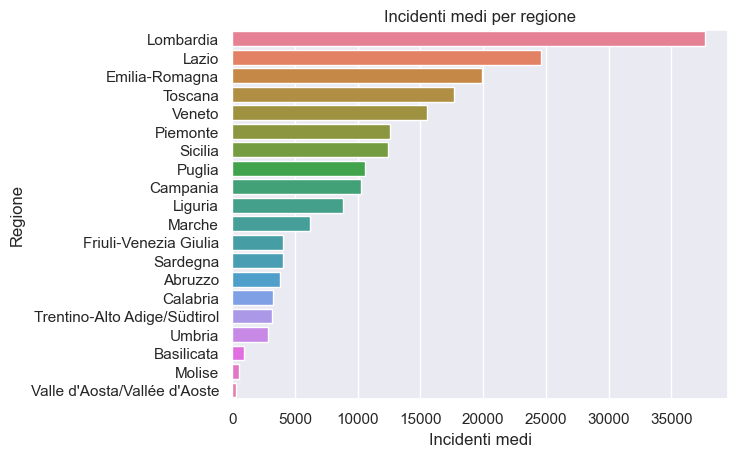

In [170]:
#GRAFICI x REGIONI
#INCIDENTI
#grafico x incidenti medio per regione
x_grafico_regione = incidenti_x_regioni.sort_values('Incidenti_medi', ascending= False)
sns.barplot(x='Incidenti_medi', y = 'Regione',hue ='Regione' , legend = False,data=x_grafico_regione).set(title='Incidenti medi per regione', xlabel='Incidenti medi', ylabel='Regione')


[Text(0.5, 1.0, 'Incidenti ogni 100.000 abitanti'),
 Text(0.5, 0, 'Incidenti'),
 Text(0, 0.5, 'Regione')]

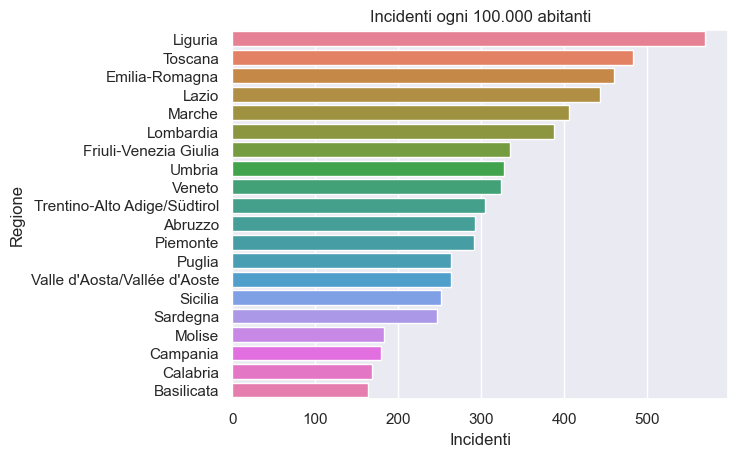

In [171]:
#grafico x incidenti ogni 100'000 abitanti per regione
x_grafico_regione2 = incidenti_x_regioni.sort_values('Incidenti_anno_100000_abitanti', ascending= False)
sns.barplot(x='Incidenti_anno_100000_abitanti', y = 'Regione',hue ='Regione' , legend = False, data=x_grafico_regione2).set(title='Incidenti ogni 100.000 abitanti', xlabel='Incidenti', ylabel='Regione')


[Text(0.5, 1.0, 'Incidenti ogni 1000 kmq'),
 Text(0.5, 0, 'Incidenti'),
 Text(0, 0.5, 'Regione')]

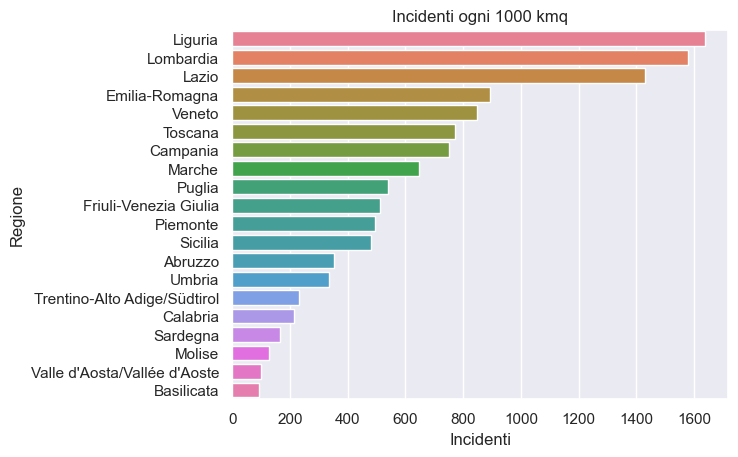

In [172]:
#grafico x incidenti ogni 1000km^2 per regione
x_grafico_regione3 = incidenti_x_regioni.sort_values('Incidenti_per_superficie_anno_1000_kmq', ascending= False)
sns.barplot(x='Incidenti_per_superficie_anno_1000_kmq', y = 'Regione',hue ='Regione' ,legend = False, data=x_grafico_regione3).set(title='Incidenti ogni 1000 kmq',xlabel='Incidenti',  ylabel='Regione')


[Text(0.5, 1.0, 'Feriti medi per regione'),
 Text(0.5, 0, 'Feriti medi'),
 Text(0, 0.5, 'Regione')]

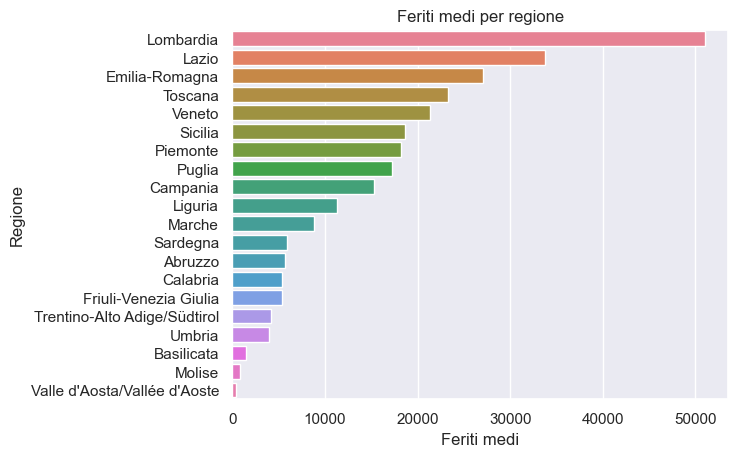

In [173]:
#FERITI
#grafico x feriti medio per regione
x_grafico_regione_f_1 = incidenti_x_regioni.sort_values('Feriti_medi', ascending= False)
sns.barplot(x='Feriti_medi', y = 'Regione',hue ='Regione' ,legend = False, data=x_grafico_regione_f_1).set(title='Feriti medi per regione', xlabel='Feriti medi', ylabel='Regione')


[Text(0.5, 1.0, 'Feriti ogni 100.000 abitanti'),
 Text(0.5, 0, 'Feriti'),
 Text(0, 0.5, 'Regione')]

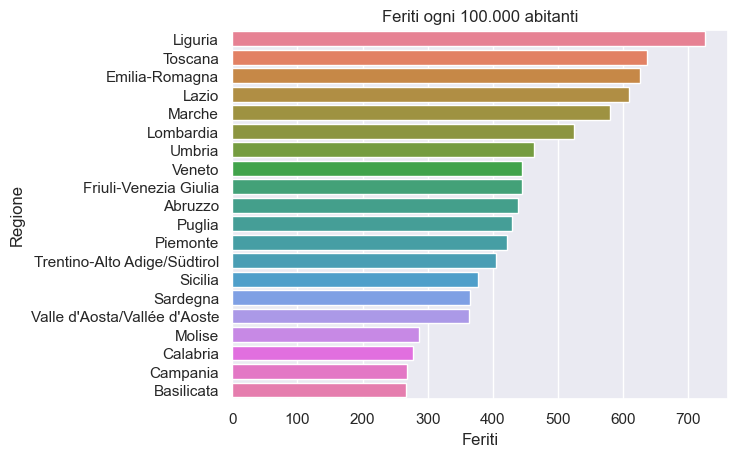

In [174]:
#grafico x feriti ogni 100'000 abitanti per regione
x_grafico_regione_f_2 = incidenti_x_regioni.sort_values('Feriti_anno_100000_abitanti', ascending= False)
sns.barplot(x='Feriti_anno_100000_abitanti', y = 'Regione',hue ='Regione' ,legend = False, data=x_grafico_regione_f_2).set(title='Feriti ogni 100.000 abitanti', xlabel='Feriti', ylabel='Regione')


[Text(0.5, 1.0, 'Incidenti e feriti medi per regione'),
 Text(0.5, 0, 'Media anno'),
 Text(0, 0.5, 'Regione')]

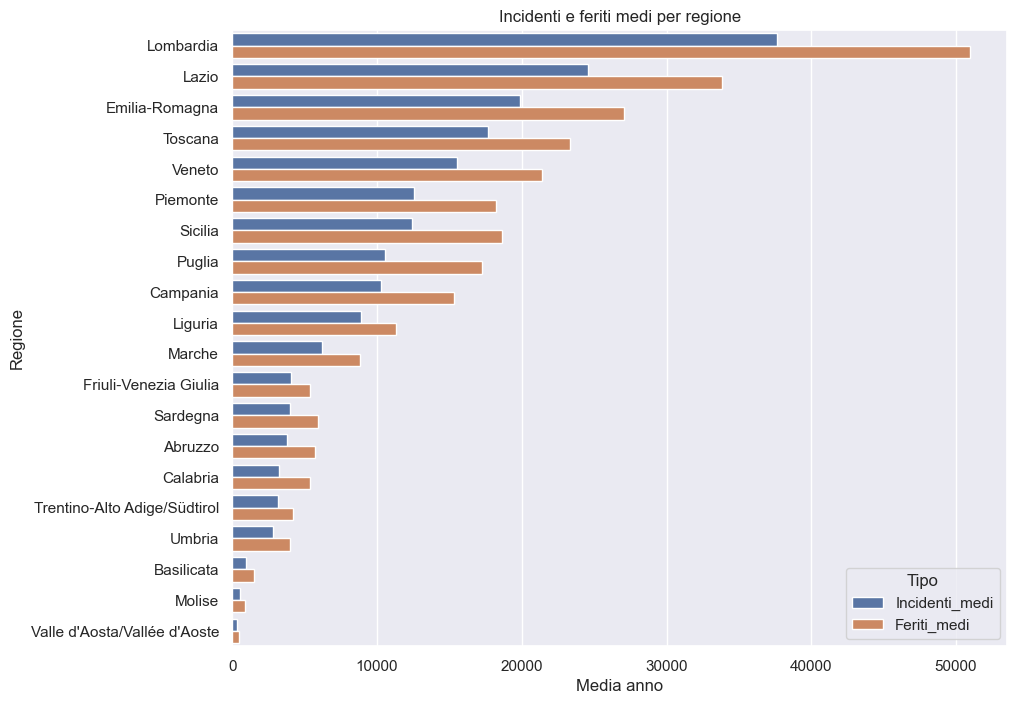

In [175]:
#incidenti medi vs feriti medi
#grafico incidenti e feriti medi per regione
x_grafico_prova = incidenti_x_regioni.sort_values('Incidenti_medi', ascending=False)
x_grafico_long = x_grafico_prova.melt(id_vars='Regione',
                                value_vars=['Incidenti_medi', 'Feriti_medi'],
                                var_name='Tipo', value_name='Valore')

plt.figure(figsize=(10, 8))

sns.barplot(x='Valore', y='Regione', hue='Tipo', data=x_grafico_long).set(
    title='Incidenti e feriti medi per regione', xlabel='Media anno', ylabel='Regione')

[Text(0.5, 1.0, 'Incidenti e feriti ogni 100.000 abitanti per regione'),
 Text(0.5, 0, 'Ogni 100.000 abitanti'),
 Text(0, 0.5, 'Regione')]

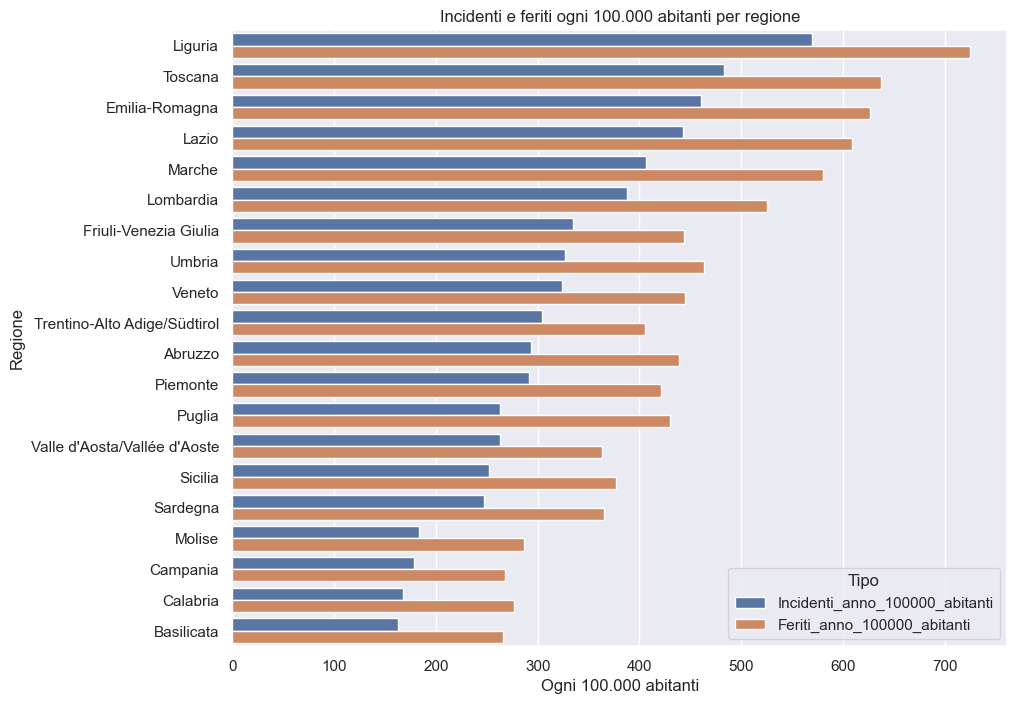

In [176]:
#incidenti vs feriti ogni 100'000 abitanti
#grafico incidenti e feriti ogni 100'000 abitanti per regione
x_grafico_prova2 = incidenti_x_regioni.sort_values('Incidenti_anno_100000_abitanti', ascending=False)

x_grafico_long2 = x_grafico_prova2.melt(id_vars='Regione',
                                value_vars=['Incidenti_anno_100000_abitanti', 'Feriti_anno_100000_abitanti'],
                                var_name='Tipo', value_name='Valore')

plt.figure(figsize=(10, 8))

sns.barplot(x='Valore', y='Regione', hue='Tipo', data=x_grafico_long2).set(
    title='Incidenti e feriti ogni 100.000 abitanti per regione', xlabel='Ogni 100.000 abitanti', ylabel='Regione')

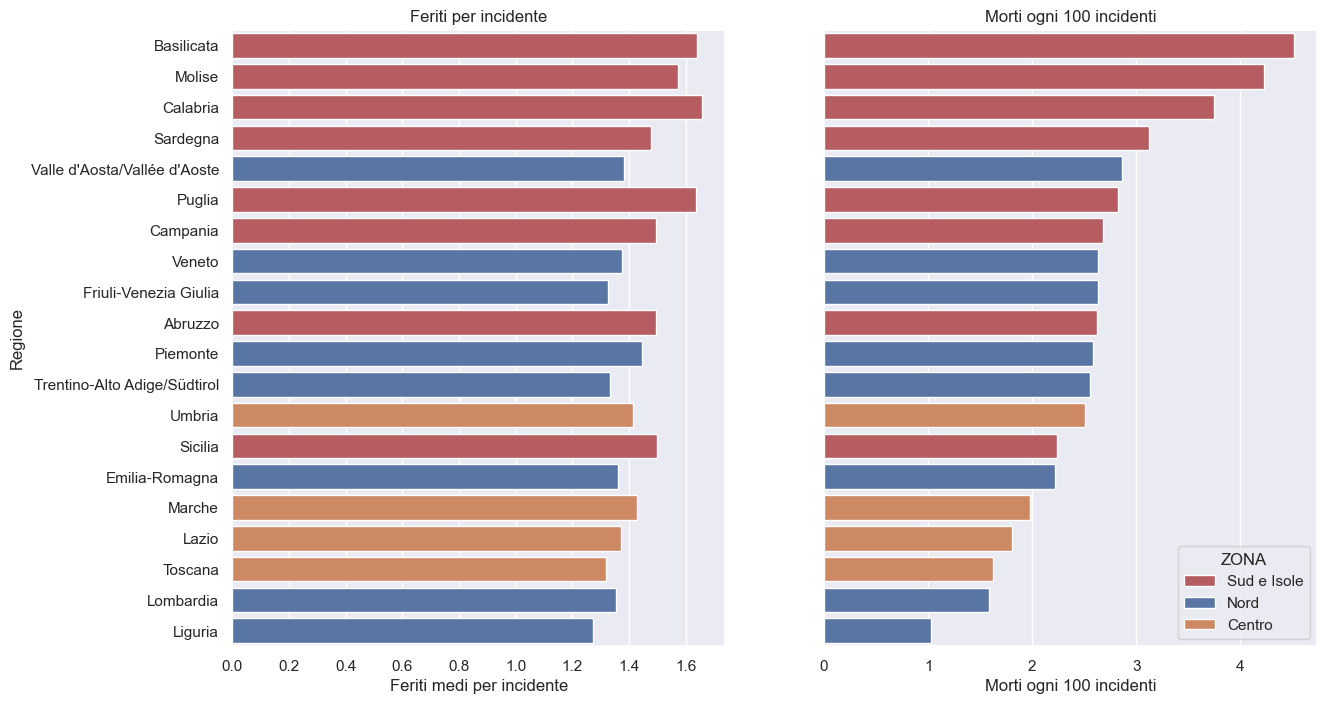

In [177]:
#MORTI
colori = {'Nord': '#4C72B0', 'Centro': '#DD8452', 'Sud e Isole': '#C44E52'}
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
x_graf_morti = incidenti_x_regioni.sort_values('Rapp_morti_su_100_incidenti', ascending=False)

sns.barplot(x='Rapp_feriti_su_incidenti', y='Regione', hue='ZONA', palette=colori,
            data=x_graf_morti, dodge=False, legend=False, ax=axes[0])
axes[0].set(title='Feriti per incidente', xlabel='Feriti medi per incidente', ylabel='Regione')

sns.barplot(x='Rapp_morti_su_100_incidenti', y='Regione', hue='ZONA', palette=colori,
            data=x_graf_morti, dodge=False, ax=axes[1])
axes[1].set(title='Morti ogni 100 incidenti', xlabel='Morti ogni 100 incidenti', ylabel='')
axes[1].legend(title='ZONA', loc='lower right')

In [178]:
#notiamo che, le regioni con più incidenti medi sono lombardia, lazio ed emilia. 
#Se però analizziamo gli incidenti ogni 100'000 abitanti, vediamo che le regioni con più incidenti in rapporto sono liguria, toscana e sempre emilia al terzo posto.
#analizzando anche gli incidenti ogni 1000 kilometri quadrati, ovvero gli incidenti per 'spazio occupato' dalle regioni, la ligura rimane sempre
#al primo posto, per poi vedere lombardia e lazio.
#per quanto riguarda le regioni con più feriti e morti per incidente, notiamo che appartengono tutte quante al sud italia 

#ciò ci inizia a poter ragionare sulla tipologia di investimento che la nostra azienda può decidere di fare.
#ci si concentra su un ampia scala dove sono presenti più incidenti, o piuttosto in relazione alla popolazione?

In [179]:
#analisi tra PROVINCE
df_incidenti_tot


,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA,Incidenti_pro_capite_anno,Incidenti_anno_1000_abitanti,Incidenti_per_superficie_anno,Incidenti_per_superficie_anno_10_kmq
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196,1.955,0.38034,3.803
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197,1.970,0.38034,3.803
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155,1.546,0.30427,3.043
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336,3.359,0.68461,6.846
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075,0.748,0.15214,1.521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078,0.785,0.07355,0.735
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197,1.972,0.18387,1.839
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039,0.388,0.03677,0.368
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153,1.529,0.14709,1.471


In [180]:
provincia_anno = df_incidenti_tot.groupby(['Provincia', 'Anno', 'Regione', 'ZONA']).agg(Incidenti = ('N_incidenti','sum'),Feriti = ('Feriti','sum'), Morti = ('Morti','sum') , Superficie=('Superficie_provincia_anno','first'),Popolazione = ('Popolazione_residente_PROVINCIA', 'first')).reset_index()
provincia_anno


,Provincia,Anno,Regione,ZONA,Incidenti,Feriti,Morti,Superficie,Popolazione
0,Agrigento,2001,Sicilia,Sud e Isole,760,1245,20,3052.5443,447719.0
1,Agrigento,2002,Sicilia,Sud e Isole,869,1360,26,3052.5443,447896.0
2,Agrigento,2003,Sicilia,Sud e Isole,749,1200,32,3052.5443,448937.0
3,Agrigento,2004,Sicilia,Sud e Isole,746,1148,31,3052.5443,448738.0
4,Agrigento,2005,Sicilia,Sud e Isole,748,1223,36,3052.5443,448752.0
...,...,...,...,...,...,...,...,...,...
2564,Viterbo,2020,Lazio,Centro,621,899,18,3615.1635,308830.0
2565,Viterbo,2021,Lazio,Centro,713,1018,12,3615.1635,308737.0
2566,Viterbo,2022,Lazio,Centro,787,1171,16,3615.9772,308158.0
2567,Viterbo,2023,Lazio,Centro,802,1143,18,3615.9772,307686.0


In [181]:
incidenti_x_provincia = provincia_anno.groupby(['Provincia', 'Regione','ZONA']).agg(Incidenti_tot = ('Incidenti','sum'),Incidenti_medi = ('Incidenti','mean'),Feriti_tot = ('Feriti','sum'), Feriti_medi = ('Feriti','mean'), Morti_tot = ('Morti','sum'), Morti_medi = ('Morti','mean'),Superficie=('Superficie','mean'), Popolazione = ('Popolazione', 'mean')).reset_index()
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3052.736333,438067.250000
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3558.779254,422740.666667
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1963.288208,467020.583333
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3232.995583,338579.041667
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1551.770492,264313.250000
...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2081.598887,173902.958333
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3096.319783,899205.875000
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1150.570233,161036.958333
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2722.464696,848704.708333


In [182]:
#arrotondo
incidenti_x_provincia['Superficie'] = np.ceil(incidenti_x_provincia['Superficie'])
incidenti_x_provincia['Popolazione'] = np.ceil(incidenti_x_provincia['Popolazione'])
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0
...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0


In [183]:
#aggiungo incidenti su 100.000 abitanti provincia
incidenti_x_provincia['Incidenti_anno_100.000_abitanti'] = (((incidenti_x_provincia['Incidenti_medi']/incidenti_x_provincia['Popolazione'])*100000)).round(2)
incidenti_x_provincia 


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68
...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60


In [184]:
#aggiungo incidenti ogni 100 kmq di provincia
incidenti_x_provincia['Incidenti_per_superficie_anno_100_kmq'] = (((incidenti_x_provincia['Incidenti_medi']/incidenti_x_provincia['Superficie'])*100)).round(2)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63
...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57


In [185]:
#aggiungo la colonna delle % degli incidenti
incidenti_x_provincia['Incidenza incidenti'] = ((incidenti_x_provincia['Incidenti_tot']/incidenti_x_provincia['Incidenti_tot'].sum())*100).round(2)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24


In [186]:
#calcolo % dei feriti
incidenti_x_provincia['Incidenza feriti'] = ((incidenti_x_provincia['Feriti_tot']/incidenti_x_provincia['Feriti_tot'].sum())*100).round(2)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31,0.36
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78,0.78
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97,1.02
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58,0.58
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61,0.61
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23,0.24
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62,1.56
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12,0.14
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24,1.19


In [187]:
#calcolo % dei morti
incidenti_x_provincia['Incidenza morti'] = ((incidenti_x_provincia['Morti_tot']/incidenti_x_provincia['Morti_tot'].sum())*100).round(2)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31,0.36,0.47
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78,0.78,0.99
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97,1.02,0.90
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58,0.58,0.70
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61,0.61,0.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23,0.24,0.49
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62,1.56,1.88
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12,0.14,0.20
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24,1.19,1.41


In [188]:
#aggiungo feriti su 100.000 abitanti provinciali
incidenti_x_provincia['Feriti_anno_100.000_abitanti'] = (((incidenti_x_provincia['Feriti_medi']/incidenti_x_provincia['Popolazione'])*100000)).round(2)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31,0.36,0.47,231.67
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78,0.78,0.99,516.01
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97,1.02,0.90,608.31
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58,0.58,0.70,476.65
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61,0.61,0.48,642.58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23,0.24,0.49,385.01
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62,1.56,1.88,485.25
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12,0.14,0.20,240.52
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24,1.19,1.41,392.42


In [189]:
#aggiungo morti su 100.000 abitanti provinciali
incidenti_x_provincia['Morti_anno_100.000_abitanti'] = (((incidenti_x_provincia['Morti_medi']/incidenti_x_provincia['Popolazione'])*100000)).round(2)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31,0.36,0.47,231.67,4.55
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78,0.78,0.99,516.01,9.96
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97,1.02,0.90,608.31,8.22
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58,0.58,0.70,476.65,8.81
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61,0.61,0.48,642.58,7.68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23,0.24,0.49,385.01,12.03
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62,1.56,1.88,485.25,8.86
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12,0.14,0.20,240.52,5.20
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24,1.19,1.41,392.42,7.08


In [190]:
#densità
incidenti_x_provincia['Densità'] = np.ceil(incidenti_x_provincia['Popolazione']/incidenti_x_provincia['Superficie'])
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31,0.36,0.47,231.67,4.55,144.0
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78,0.78,0.99,516.01,9.96,119.0
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97,1.02,0.90,608.31,8.22,238.0
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58,0.58,0.70,476.65,8.81,105.0
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61,0.61,0.48,642.58,7.68,171.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23,0.24,0.49,385.01,12.03,84.0
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62,1.56,1.88,485.25,8.86,291.0
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12,0.14,0.20,240.52,5.20,140.0
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24,1.19,1.41,392.42,7.08,312.0


In [191]:
#rapporto feriti/incidenti
incidenti_x_provincia['Rapp_feriti_su_incidenti'] = (incidenti_x_provincia['Feriti_medi']/incidenti_x_provincia['Incidenti_medi']).round(3)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,438068.0,142.05,20.38,0.31,0.36,0.47,231.67,4.55,144.0,1.631
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,422741.0,369.50,43.89,0.78,0.78,0.99,516.01,9.96,119.0,1.396
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,467021.0,415.46,98.79,0.97,1.02,0.90,608.31,8.22,238.0,1.464
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,338580.0,339.28,35.53,0.58,0.58,0.70,476.65,8.81,105.0,1.405
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,264314.0,461.68,78.63,0.61,0.61,0.48,642.58,7.68,171.0,1.392
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,173903.0,268.25,22.41,0.23,0.24,0.49,385.01,12.03,84.0,1.435
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,899206.0,359.48,104.37,1.62,1.56,1.88,485.25,8.86,291.0,1.350
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,161037.0,145.23,20.32,0.12,0.14,0.20,240.52,5.20,140.0,1.656
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,848705.0,290.60,90.57,1.24,1.19,1.41,392.42,7.08,312.0,1.350


In [192]:
#rapporto morti/incidenti
incidenti_x_provincia['Rapp_morti_su_100_incidenti'] = ((incidenti_x_provincia['Morti_medi']/incidenti_x_provincia['Incidenti_medi'])*100).round(3)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti
0,Agrigento,Sicilia,Sud e Isole,14935,622.291667,24357,1014.875000,478,19.916667,3053.0,...,142.05,20.38,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201
1,Alessandria,Piemonte,Nord,37489,1562.041667,52353,2181.375000,1011,42.125000,3559.0,...,369.50,43.89,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697
2,Ancona,Marche,Centro,46567,1940.291667,68183,2840.958333,921,38.375000,1964.0,...,415.46,98.79,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978
3,Arezzo,Toscana,Centro,27570,1148.750000,38732,1613.833333,716,29.833333,3233.0,...,339.28,35.53,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597
4,Ascoli Piceno,Marche,Centro,29287,1220.291667,40762,1698.416667,487,20.291667,1552.0,...,461.68,78.63,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,466.500000,16069,669.541667,502,20.916667,2082.0,...,268.25,22.41,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484
106,Verona,Veneto,Nord,77579,3232.458333,104722,4363.416667,1913,79.708333,3097.0,...,359.48,104.37,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466
107,Vibo Valentia,Calabria,Sud e Isole,5613,233.875000,9296,387.333333,201,8.375000,1151.0,...,145.23,20.32,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581
108,Vicenza,Veneto,Nord,59192,2466.333333,79931,3330.458333,1442,60.083333,2723.0,...,290.60,90.57,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436


In [193]:
#arrotondo
incidenti_x_provincia['Incidenti_medi'] = np.ceil(incidenti_x_provincia['Incidenti_medi'])
incidenti_x_provincia['Feriti_medi'] = np.ceil(incidenti_x_provincia['Feriti_medi'])
incidenti_x_provincia['Morti_medi'] = np.ceil(incidenti_x_provincia['Morti_medi'])

In [194]:
#GRAFICI x PROVINCIA
#INCIDENTI

[Text(0.5, 1.0, 'Incidenti medi - TOP 20 province'),
 Text(0.5, 0, 'Incidenti medi'),
 Text(0, 0.5, 'Provincia')]

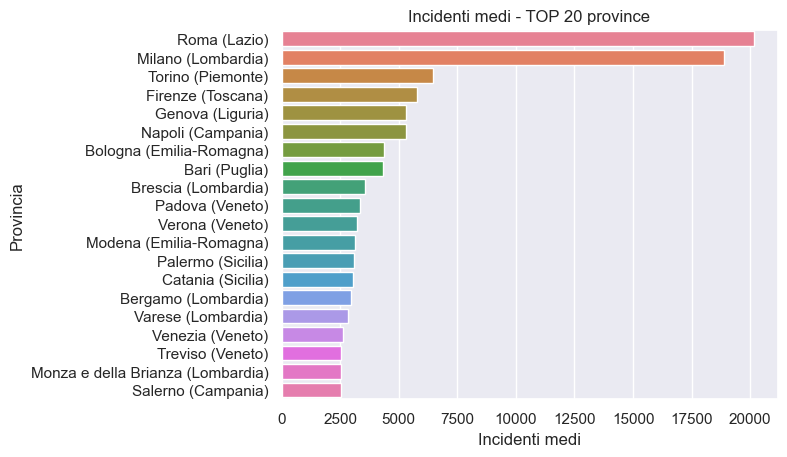

In [195]:
x_grafico_provincia = incidenti_x_provincia.sort_values('Incidenti_medi', ascending= False)
top_20 = x_grafico_provincia.head(20).copy()
top_20['conca'] = top_20['Provincia'] + ' (' + top_20['Regione'] + ')'
sns.barplot(x='Incidenti_medi', y = 'conca',hue ='Provincia' , data=top_20, legend = False).set(title='Incidenti medi - TOP 20 province', xlabel='Incidenti medi', ylabel='Provincia')

[Text(0.5, 1.0, 'Incidenti ogni 100.000 abitanti - TOP 20 province'),
 Text(0.5, 0, 'Incidenti'),
 Text(0, 0.5, 'Provincia')]

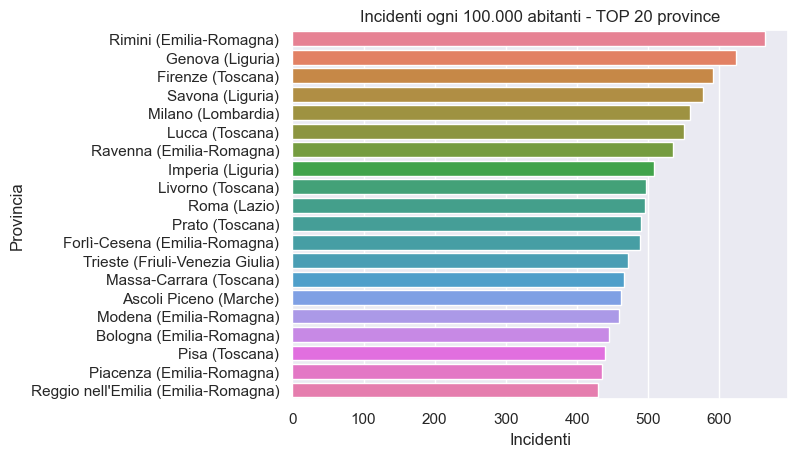

In [196]:
#grafico x incidenti ogni 100000 abitanti per Provincia
x_grafico_provincia2 = incidenti_x_provincia.sort_values('Incidenti_anno_100.000_abitanti', ascending= False)
top_20_2 = x_grafico_provincia2.head(20).copy()
top_20_2['conca'] = top_20_2['Provincia'] + ' (' + top_20_2['Regione'] + ')'
sns.barplot(x='Incidenti_anno_100.000_abitanti', y = 'conca',hue ='Provincia' , data=top_20_2, legend = False).set(title='Incidenti ogni 100.000 abitanti - TOP 20 province', xlabel='Incidenti', ylabel='Provincia')


[Text(0.5, 1.0, 'Incidenti ogni 100 kmq - TOP 20 province'),
 Text(0.5, 0, 'Incidenti'),
 Text(0, 0.5, 'Provincia')]

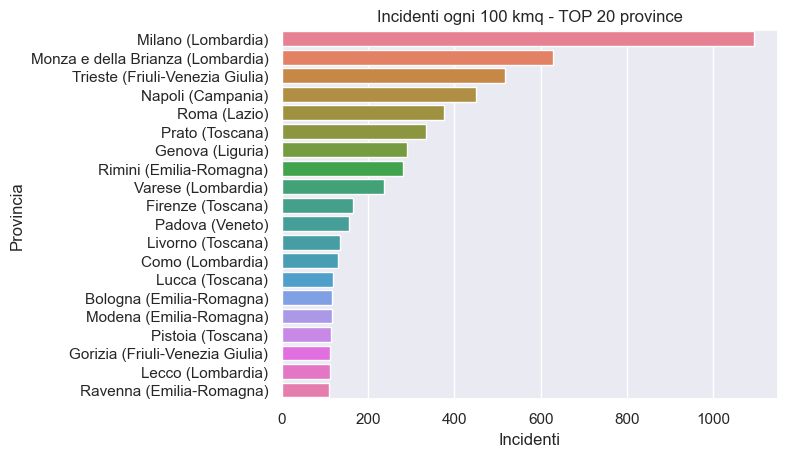

In [197]:
#grafico x incidenti ogni 100km^2 abitanti per Provincia
x_grafico_provincia3 = incidenti_x_provincia.sort_values('Incidenti_per_superficie_anno_100_kmq', ascending= False)
top_20_3 = x_grafico_provincia3.head(20).copy()
top_20_3['conca'] = top_20_3['Provincia'] + ' (' + top_20_3['Regione'] + ')'
sns.barplot(x='Incidenti_per_superficie_anno_100_kmq', y = 'conca',hue ='Provincia' , data=top_20_3, legend = False).set(title='Incidenti ogni 100 kmq - TOP 20 province', xlabel='Incidenti', ylabel='Provincia')


[Text(0.5, 1.0, 'Feriti medi  - TOP 20 province'),
 Text(0.5, 0, 'Feriti medi'),
 Text(0, 0.5, 'Provincia')]

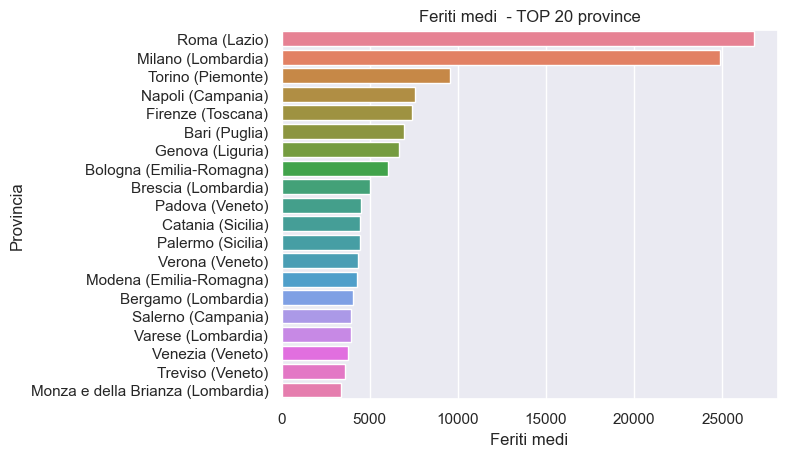

In [198]:
#FERITI
#grafico x feriti medio per Provincia
x_grafico_provincia_f_1 = incidenti_x_provincia.sort_values('Feriti_medi', ascending= False)
top_20_4 = x_grafico_provincia_f_1.head(20).copy()
top_20_4['conca'] = top_20_4['Provincia'] + ' (' + top_20_4['Regione'] + ')'
sns.barplot(x='Feriti_medi', y = 'conca',hue ='Provincia' , legend = False , data=top_20_4).set(title='Feriti medi  - TOP 20 province', xlabel='Feriti medi', ylabel='Provincia')


[Text(0.5, 1.0, 'Feriti ogni 100.000 abitanti  - TOP 20 province'),
 Text(0.5, 0, 'Feriti'),
 Text(0, 0.5, 'Provincia')]

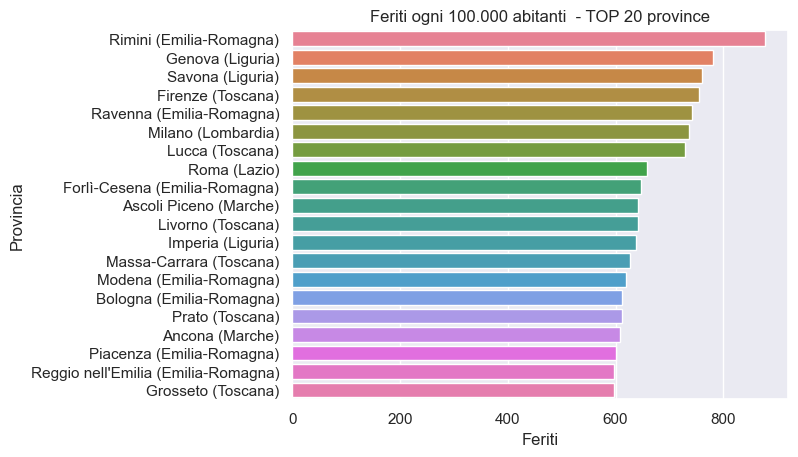

In [199]:
#grafico x feriti ogni 100000 abitanti per Provincia
x_grafico_provincia_f_2 = incidenti_x_provincia.sort_values('Feriti_anno_100.000_abitanti', ascending= False)
top_20_5 = x_grafico_provincia_f_2.head(20).copy()
top_20_5['conca'] = top_20_5['Provincia'] + ' (' + top_20_5['Regione'] + ')'
sns.barplot(x='Feriti_anno_100.000_abitanti', y = 'conca',hue ='Provincia' ,legend = False, data=top_20_5).set(title='Feriti ogni 100.000 abitanti  - TOP 20 province', xlabel='Feriti',  ylabel='Provincia')


[Text(0.5, 1.0, 'Incidenti e feriti medi  - TOP 20 province'),
 Text(0.5, 0, 'Media anno'),
 Text(0, 0.5, 'Provincia')]

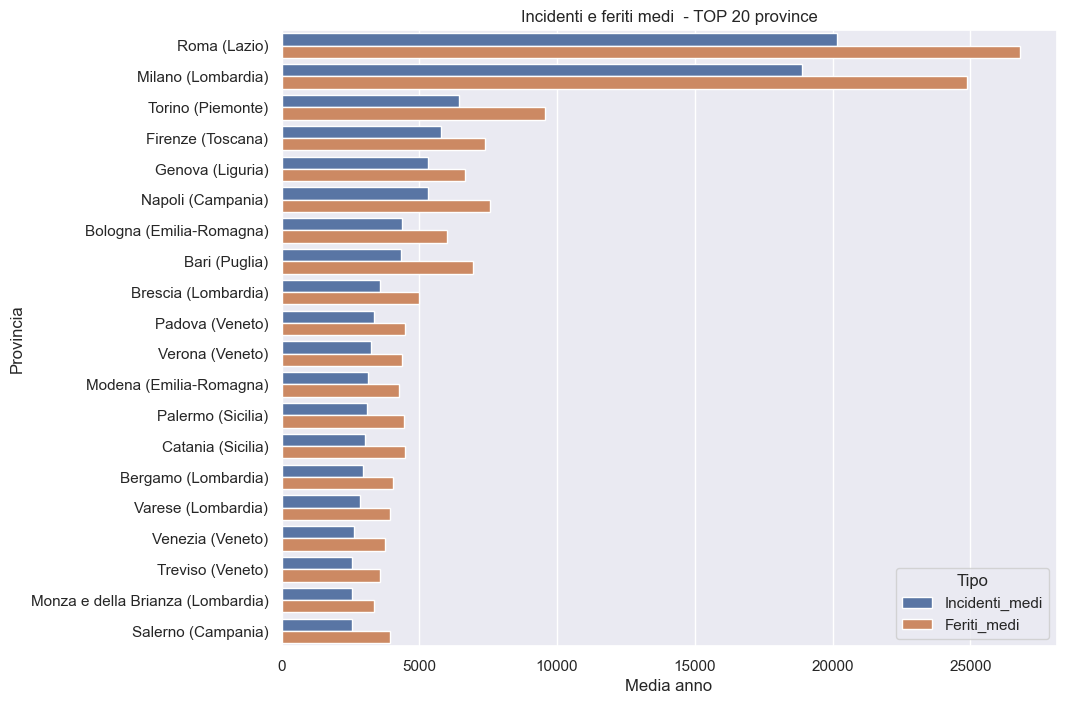

In [200]:
#incidenti medi vs feriti medi
#grafico incidenti e feriti medi per Provincia
x_grafico_provincia4 = incidenti_x_provincia.sort_values('Incidenti_medi', ascending=False)
top_20_6 = x_grafico_provincia4.head(20).copy()
top_20_6['conca'] = top_20_6['Provincia'] + ' (' + top_20_6['Regione'] + ')'

x_grafico_long_prov = top_20_6.melt(id_vars='conca',
                                value_vars=['Incidenti_medi', 'Feriti_medi'],
                                var_name='Tipo', value_name='Valore')

plt.figure(figsize=(10, 8))

sns.barplot(x='Valore', y='conca', hue='Tipo', data=x_grafico_long_prov).set(
    title='Incidenti e feriti medi  - TOP 20 province', xlabel='Media anno', ylabel='Provincia')


[Text(0.5, 1.0, 'Incidenti e feriti ogni 100.000 abitanti - TOP 20 province'),
 Text(0.5, 0, 'Ogni 100.000 abitanti'),
 Text(0, 0.5, 'Provincia')]

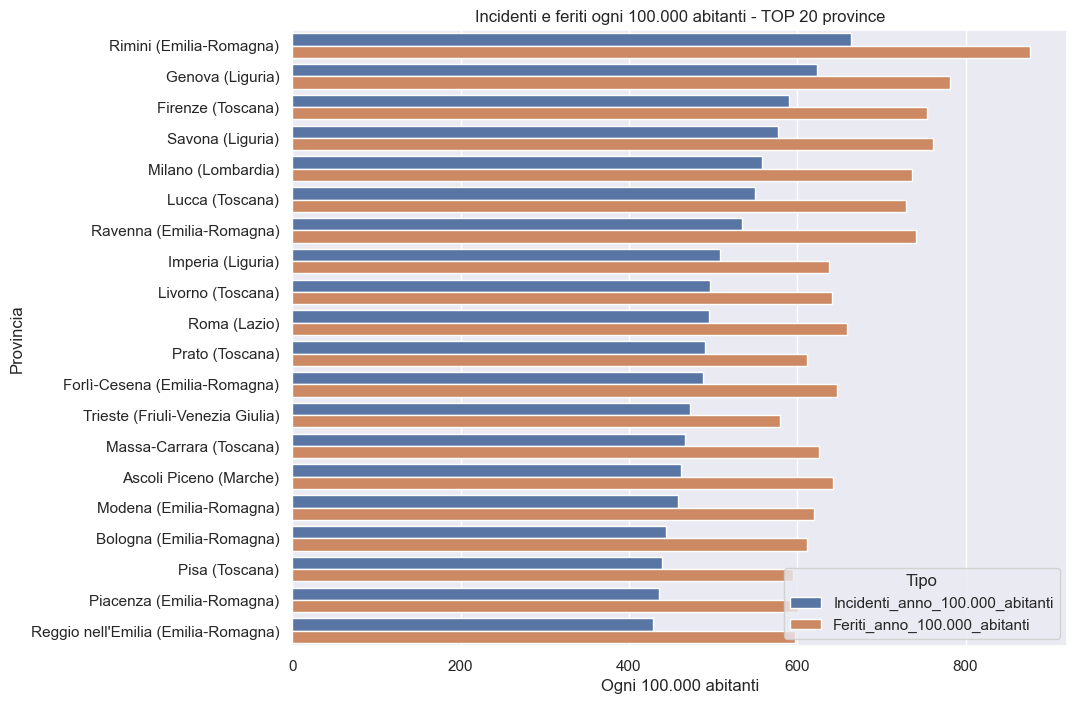

In [201]:
#incidenti vs feriti ogni 100000 abitanti
#grafico incidenti e feriti ogni 100000 abitanti per Provincia
x_grafico_provincia5 = incidenti_x_provincia.sort_values('Incidenti_anno_100.000_abitanti', ascending=False)
top_20_7 = x_grafico_provincia5.head(20).copy()
top_20_7['conca'] = top_20_7['Provincia'] + ' (' + top_20_7['Regione'] + ')'

x_grafico_long2_prov = top_20_7.melt(id_vars='conca',
                                value_vars=['Incidenti_anno_100.000_abitanti', 'Feriti_anno_100.000_abitanti'],
                                var_name='Tipo', value_name='Valore')

plt.figure(figsize=(10, 8))

sns.barplot(x='Valore', y='conca', hue='Tipo', data=x_grafico_long2_prov).set(
    title='Incidenti e feriti ogni 100.000 abitanti - TOP 20 province', xlabel='Ogni 100.000 abitanti', ylabel='Provincia')


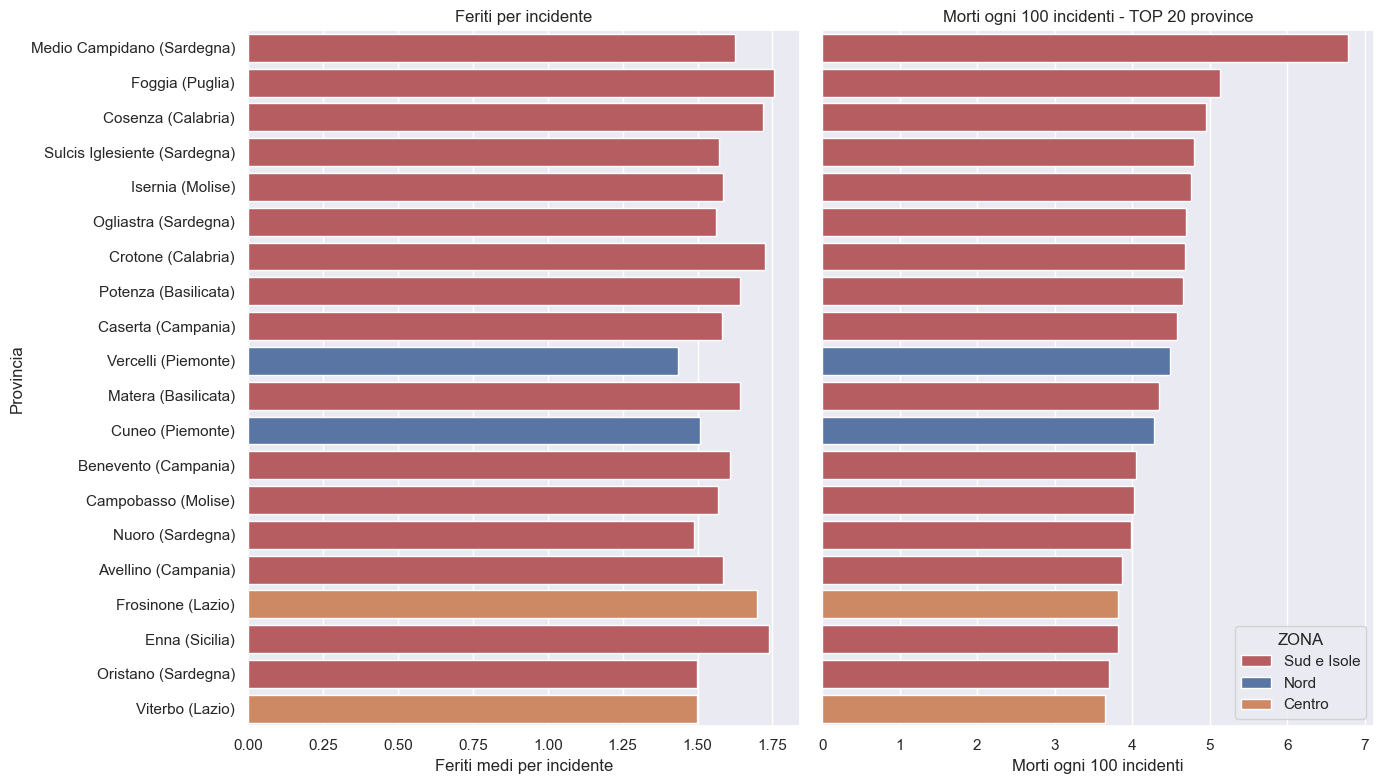

In [202]:
#confronto tra le Provicne con più morti, i feriti
colori = {'Nord': '#4C72B0', 'Centro': '#DD8452', 'Sud e Isole': '#C44E52'}
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
x_graf_morti2 = incidenti_x_provincia.sort_values('Rapp_morti_su_100_incidenti', ascending=False).head(20).copy()
x_graf_morti2['conca'] = x_graf_morti2['Provincia'] + ' (' + x_graf_morti2['Regione'] + ')'
sns.barplot(x='Rapp_feriti_su_incidenti', y='conca', hue='ZONA', palette=colori,
            data=x_graf_morti2, dodge=False, legend=False, ax=axes[0], errorbar=None)
axes[0].set(title='Feriti per incidente', xlabel='Feriti medi per incidente', ylabel='Provincia')

sns.barplot(x='Rapp_morti_su_100_incidenti', y='conca', hue='ZONA', palette=colori,
            data=x_graf_morti2, dodge=False, ax=axes[1], errorbar=None)
axes[1].set(title='Morti ogni 100 incidenti - TOP 20 province', xlabel='Morti ogni 100 incidenti', ylabel='')
axes[1].legend(title='ZONA', loc='lower right')

plt.tight_layout()


In [203]:
#note: alcune province sono state istituite o riorganizzate nel periodo analizzato (Monza da Milano, Barletta-Andria-Trani
#da Bari/Foggia, Fermo da Ascoli Piceno nel 2009-2010; le province sarde più volte). Per queste i valori medi
#mescolano territori diversi: i tassi restano confrontabili, e analizzeremo quelli, i valori assoluti meno.
#per le province, i dati cambiano profondamente in base all'indice che guardiamo: per numero di incidenti medi, sono le città più grandi e popolose.
#rapportato invece ai 100k abitatni, sono città con alto traffico/turistiche/di passaggio
#anche per le province, i tassi di feriti e morti fa riferimento a città del sud italia

In [204]:
#ANALISI PER COMUNE
comune_anno = df_incidenti_tot.groupby(['Comune', 'Nome_Comune', 'Provincia', 'Regione', 'ZONA', 'Anno']).agg(Incidenti=('N_incidenti', 'sum'), Feriti=('Feriti', 'sum'), Morti=('Morti', 'sum'), Superficie=('Superficie_comune', 'first'), Popolazione=('Popolazione residente', 'first')).reset_index()
comune_anno


,Comune,Nome_Comune,Provincia,Regione,ZONA,Anno,Incidenti,Feriti,Morti,Superficie,Popolazione
0,1001,Agliè,Torino,Piemonte,Nord,2001,5,10,0,13.1462,2557.0
1,1001,Agliè,Torino,Piemonte,Nord,2002,5,10,0,13.1462,2538.0
2,1001,Agliè,Torino,Piemonte,Nord,2003,4,7,0,13.1462,2588.0
3,1001,Agliè,Torino,Piemonte,Nord,2004,9,13,0,13.1462,2679.0
4,1001,Agliè,Torino,Piemonte,Nord,2005,2,2,0,13.1462,2674.0
...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2020,2,3,0,27.1937,2549.0
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2021,5,7,0,27.1937,2536.0
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2022,1,1,0,27.1943,2575.0
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2023,4,5,0,27.1943,2616.0


In [205]:
n_anni = df_incidenti_tot['Anno'].nunique()
incidenti_x_comune = comune_anno.groupby(['Comune', 'Nome_Comune', 'Provincia', 'Regione', 'ZONA']).agg(Incidenti_tot=('Incidenti', 'sum'), Feriti_tot=('Feriti', 'sum'), Morti_tot=('Morti', 'sum'), Superficie=('Superficie', 'mean'), Popolazione=('Popolazione', 'mean')).reset_index()
incidenti_x_comune


,Comune,Nome_Comune,Provincia,Regione,ZONA,Incidenti_tot,Feriti_tot,Morti_tot,Superficie,Popolazione
0,1001,Agliè,Torino,Piemonte,Nord,95,161,1,13.146212,2630.541667
1,1002,Airasca,Torino,Piemonte,Nord,262,427,8,15.739300,3699.041667
2,1003,Ala di Stura,Torino,Piemonte,Nord,6,10,0,46.331513,463.875000
3,1004,Albiano d'Ivrea,Torino,Piemonte,Nord,107,165,10,11.732438,1696.000000
4,1005,Alice Superiore,Torino,Piemonte,Nord,21,34,5,7.379600,688.055556
...,...,...,...,...,...,...,...,...,...,...
8573,111103,Villaputzu,Sulcis Iglesiente,Sardegna,Sud e Isole,48,70,5,181.340137,4529.625000
8574,111104,Villasalto,Sulcis Iglesiente,Sardegna,Sud e Isole,18,26,1,130.359600,981.000000
8575,111105,Villasimius,Sulcis Iglesiente,Sardegna,Sud e Isole,54,74,5,58.048537,3707.500000
8576,111106,Villasor,Sulcis Iglesiente,Sardegna,Sud e Isole,104,157,11,86.801075,6692.125000


In [206]:
#media su tutti gli anni (attenzione, a differenze di tutte le altre rilevazioni negli anni,nel 2024 i comuni senza incidenti non compaiono)

incidenti_x_comune['Incidenti_medi'] = incidenti_x_comune['Incidenti_tot'] / n_anni
incidenti_x_comune['Incidenti_100k_abitanti'] = (incidenti_x_comune['Incidenti_medi'] / incidenti_x_comune['Popolazione'] * 100000).round(1)
incidenti_x_comune['Incidenti_kmq'] = (incidenti_x_comune['Incidenti_medi'] / incidenti_x_comune['Superficie']).round(2)
incidenti_x_comune['Feriti_100_incidenti'] = (incidenti_x_comune['Feriti_tot'] / incidenti_x_comune['Incidenti_tot'] * 100).round(2)
incidenti_x_comune['Morti_100_incidenti'] = (incidenti_x_comune['Morti_tot'] / incidenti_x_comune['Incidenti_tot'] * 100).round(2)

incidenti_x_comune

,Comune,Nome_Comune,Provincia,Regione,ZONA,Incidenti_tot,Feriti_tot,Morti_tot,Superficie,Popolazione,Incidenti_medi,Incidenti_100k_abitanti,Incidenti_kmq,Feriti_100_incidenti,Morti_100_incidenti
0,1001,Agliè,Torino,Piemonte,Nord,95,161,1,13.146212,2630.541667,3.958333,150.5,0.30,169.47,1.05
1,1002,Airasca,Torino,Piemonte,Nord,262,427,8,15.739300,3699.041667,10.916667,295.1,0.69,162.98,3.05
2,1003,Ala di Stura,Torino,Piemonte,Nord,6,10,0,46.331513,463.875000,0.250000,53.9,0.01,166.67,0.00
3,1004,Albiano d'Ivrea,Torino,Piemonte,Nord,107,165,10,11.732438,1696.000000,4.458333,262.9,0.38,154.21,9.35
4,1005,Alice Superiore,Torino,Piemonte,Nord,21,34,5,7.379600,688.055556,0.875000,127.2,0.12,161.90,23.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8573,111103,Villaputzu,Sulcis Iglesiente,Sardegna,Sud e Isole,48,70,5,181.340137,4529.625000,2.000000,44.2,0.01,145.83,10.42
8574,111104,Villasalto,Sulcis Iglesiente,Sardegna,Sud e Isole,18,26,1,130.359600,981.000000,0.750000,76.5,0.01,144.44,5.56
8575,111105,Villasimius,Sulcis Iglesiente,Sardegna,Sud e Isole,54,74,5,58.048537,3707.500000,2.250000,60.7,0.04,137.04,9.26
8576,111106,Villasor,Sulcis Iglesiente,Sardegna,Sud e Isole,104,157,11,86.801075,6692.125000,4.333333,64.8,0.05,150.96,10.58


In [207]:
#per i tassi considero solo i comuni sopra 50.000 abitanti: nei piccoli comuni pochi incidenti sporcano troppo l'indice
comuni_grandi = incidenti_x_comune[incidenti_x_comune['Popolazione'] >= 50000].copy()
comuni_grandi['conca'] = comuni_grandi['Nome_Comune'] + ' (' + comuni_grandi['Provincia'] + ')'
len(comuni_grandi)

149

[Text(0.5, 1.0, 'Incidenti ogni 100.000 abitanti - TOP 20 comuni (>50.000 ab.)'),
 Text(0.5, 0, 'Incidenti ogni 100.000 abitanti'),
 Text(0, 0.5, 'Comune')]

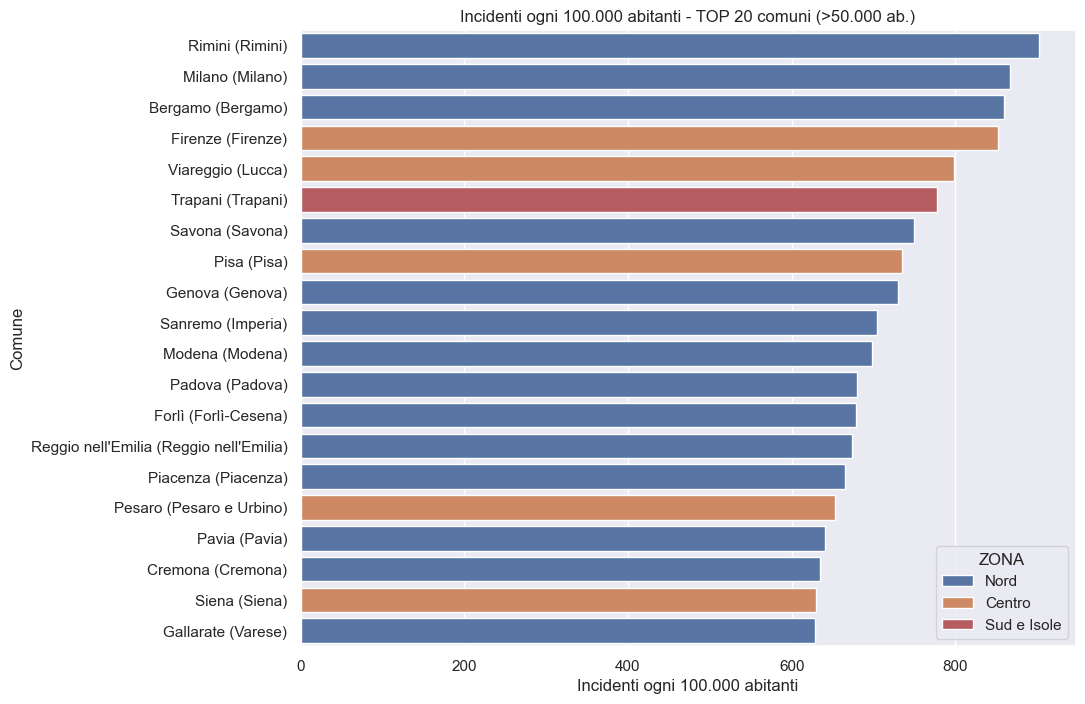

In [208]:
#GRAFICI x COMUNE
#incidenti ogni 100.000 abitanti
top_20_com = comuni_grandi.sort_values('Incidenti_100k_abitanti', ascending=False).head(20)
plt.figure(figsize=(10, 8))
sns.barplot(x='Incidenti_100k_abitanti', y='conca', hue='ZONA', palette=colori, data=top_20_com, dodge=False).set(
    title='Incidenti ogni 100.000 abitanti - TOP 20 comuni (>50.000 ab.)', xlabel='Incidenti ogni 100.000 abitanti', ylabel='Comune')

[Text(0.5, 1.0, 'Incidenti per kmq - TOP 20 comuni (>50.000 ab.)'),
 Text(0.5, 0, 'Incidenti medi annui per kmq'),
 Text(0, 0.5, 'Comune')]

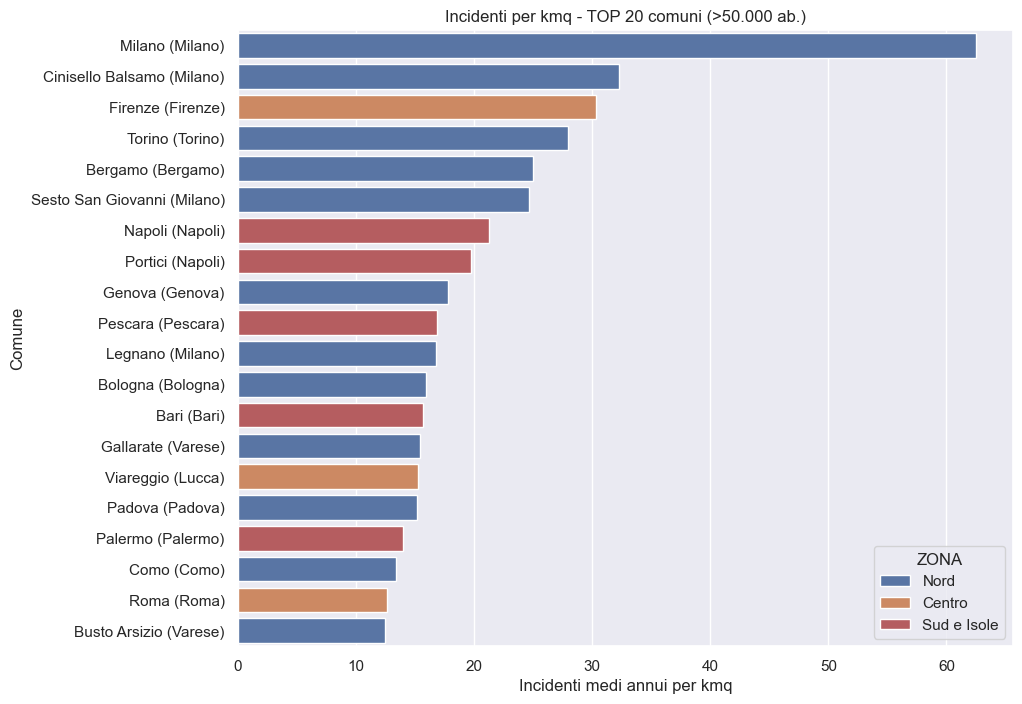

In [209]:
#incidenti x km^2
top_20_com_kmq = comuni_grandi.sort_values('Incidenti_kmq', ascending=False).head(20)
plt.figure(figsize=(10, 8))
sns.barplot(x='Incidenti_kmq', y='conca', hue='ZONA', palette=colori, data=top_20_com_kmq, dodge=False).set(title='Incidenti per kmq - TOP 20 comuni (>50.000 ab.)', xlabel='Incidenti medi annui per kmq', ylabel='Comune')

[Text(0.5, 1.0, 'Incidenti medi annui - TOP 20 comuni (>50.000 ab.)'),
 Text(0.5, 0, 'Incidenti medi annui'),
 Text(0, 0.5, 'Comune')]

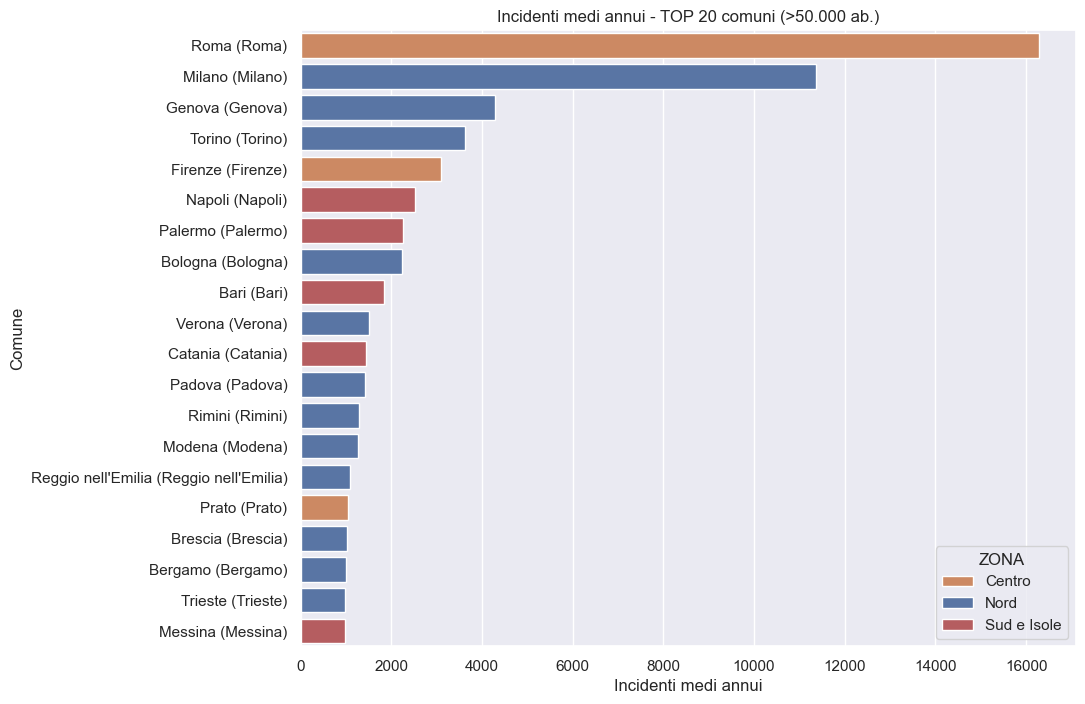

In [210]:
#incidenti medi annui
top_20_com_medi = comuni_grandi.sort_values('Incidenti_medi', ascending=False).head(20)
plt.figure(figsize=(10, 8))
sns.barplot(x='Incidenti_medi', y='conca', hue='ZONA', palette=colori, data=top_20_com_medi, dodge=False).set(title='Incidenti medi annui - TOP 20 comuni (>50.000 ab.)', xlabel='Incidenti medi annui', ylabel='Comune')


[Text(0.5, 1.0, 'Feriti - TOP 20 comuni (>50.000 ab.)'),
 Text(0.5, 0, 'Feriti ogni 100 incidenti'),
 Text(0, 0.5, 'Comune')]

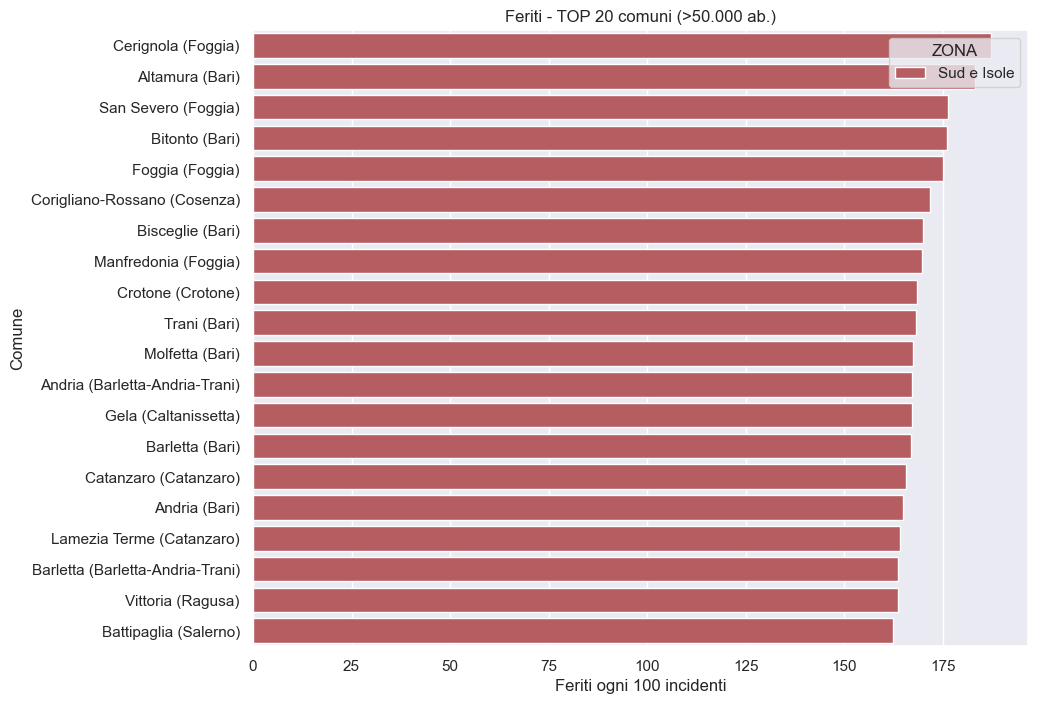

In [211]:
#Feriti
top_20_com_feriti = comuni_grandi.sort_values('Feriti_100_incidenti', ascending=False).head(20)
plt.figure(figsize=(10, 8))
sns.barplot(x='Feriti_100_incidenti', y='conca', hue='ZONA', palette=colori, data=top_20_com_feriti, dodge=False).set(title='Feriti - TOP 20 comuni (>50.000 ab.)', xlabel='Feriti ogni 100 incidenti', ylabel='Comune')


[Text(0.5, 1.0, 'Morti - TOP 20 comuni (>50.000 ab.)'),
 Text(0.5, 0, 'Morti ogni 100 incidenti'),
 Text(0, 0.5, 'Comune')]

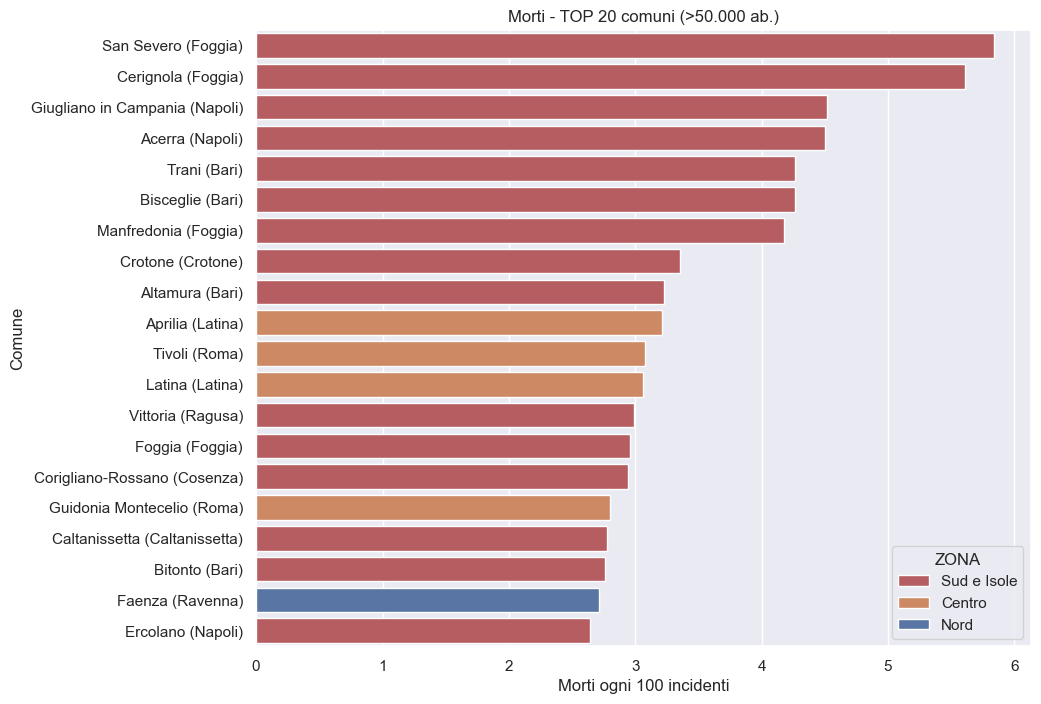

In [212]:
#Morti
top_20_com_morti = comuni_grandi.sort_values('Morti_100_incidenti', ascending=False).head(20)
plt.figure(figsize=(10, 8))
sns.barplot(x='Morti_100_incidenti', y='conca', hue='ZONA', palette=colori, data=top_20_com_morti, dodge=False).set(title='Morti - TOP 20 comuni (>50.000 ab.)', xlabel='Morti ogni 100 incidenti', ylabel='Comune')


[Text(0.5, 1.0, 'Morti - TOP 20 comuni (>50.000 ab.)'),
 Text(0.5, 0, 'Morti ogni 100 incidenti'),
 Text(0, 0.5, 'Comune')]

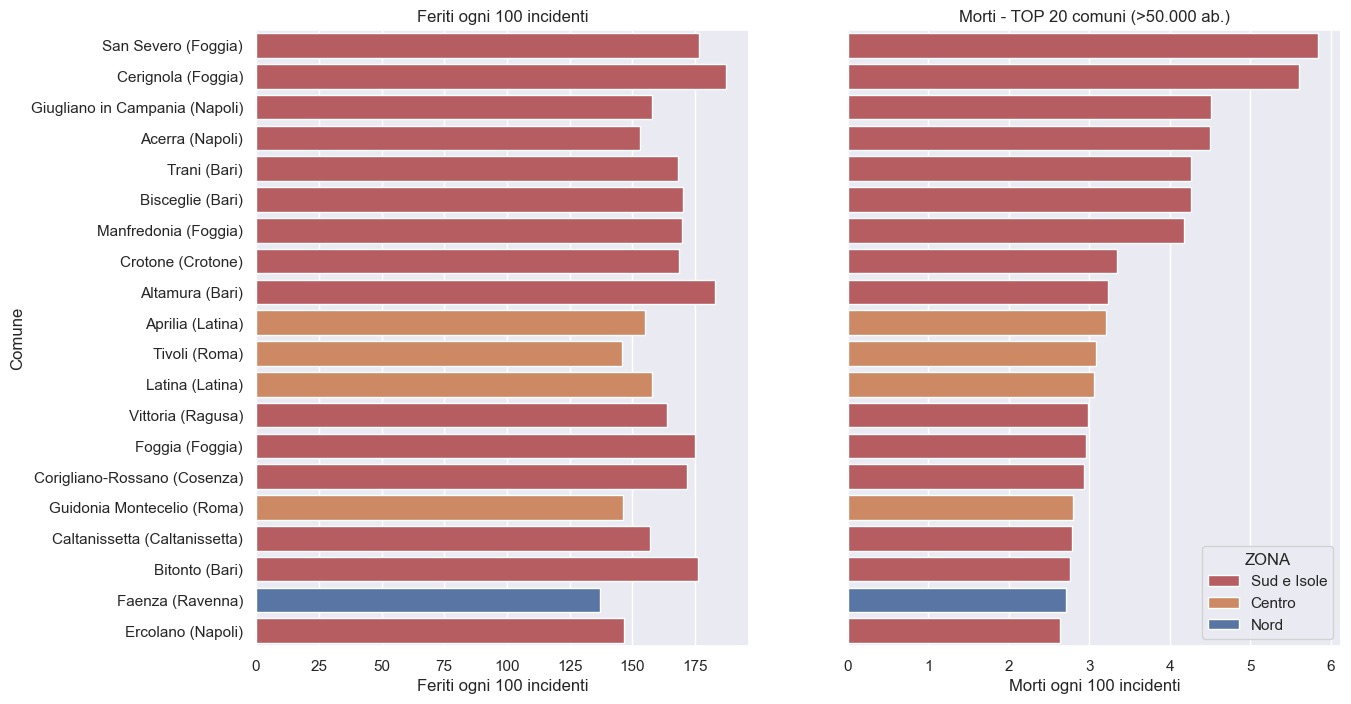

In [213]:
#confronto tra le città con più morti, i feriti
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
x_graf_morti_com = comuni_grandi.sort_values('Morti_100_incidenti', ascending=False).head(20)

sns.barplot(x='Feriti_100_incidenti', y='conca', hue='ZONA', palette=colori, data=x_graf_morti_com, dodge=False, ax = axes[0],legend=False )
axes[0].set(title='Feriti ogni 100 incidenti', xlabel='Feriti ogni 100 incidenti', ylabel='Comune')

sns.barplot(x='Morti_100_incidenti', y='conca', hue='ZONA', palette=colori, data=x_graf_morti_com, dodge=False, ax = axes[1])
axes[1].set(title='Morti - TOP 20 comuni (>50.000 ab.)', xlabel='Morti ogni 100 incidenti', ylabel='Comune')


#si nota come per densità Milano e tutta la zona attorno ha molti più incidenti rispetto gli altri comuni.
#per quanto riguarda invece il volume di incidenti, Roma ne fa da padrona, seguita da milano
# se si confrontassero invece per numero di abitanti Rimini ne fa da padrona (potrebbe essere dovuto al fatto che l'autostrada A14 sempre molto trafficata faccia aumentare gli incidenti in zona rimini), Milano, Bergamo e Firenze (tutte città turistiche o molto attraversate - Bergamo con l'A4 sempre ricca di incidenti - Firenze dovuta magari al passaggio dell'A1 direzione Napoli e i numerosi lavori sulla zona appenninica).
#come con le province e regioni, notimao che gli incidenti con più feriti/morti sono quasi tutti al sud italia (15 su 20)






In [214]:
#provo a clusterizzare le province per numero di incidenti rispetto alla popolazione: ritengo che possa essere un cluster apparentemente interessante
#sicchè mi aspetto che il numero di abitanti e il numero di incidenti abbia una forte correlazione.

In [215]:
incidenti_x_provincia_solo_numeri = incidenti_x_provincia[['Incidenti_medi', 'Popolazione']]


Text(0, 0.5, 'y')

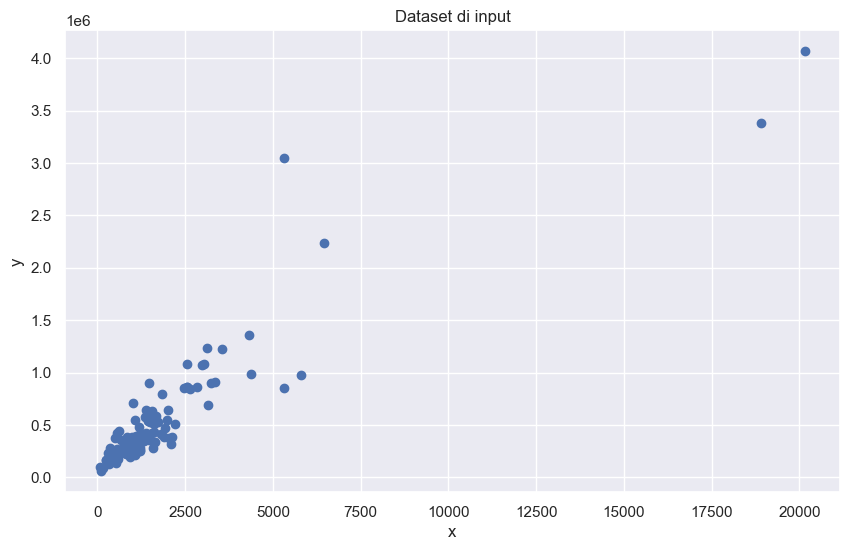

In [216]:
plt.figure(figsize=(10, 6))
plt.scatter(incidenti_x_provincia['Incidenti_medi'], incidenti_x_provincia['Popolazione'], marker="o")
plt.title('Dataset di input')
plt.xlabel('x')
plt.ylabel('y')


In [ ]:
# normalizzo i dati
scale_norm = MinMaxScaler()
incidenti_x_provincia_solo_numeri = pd.DataFrame(scale_norm.fit_transform(incidenti_x_provincia_solo_numeri), columns = incidenti_x_provincia_solo_numeri.columns)


Text(0, 0.5, 'y')

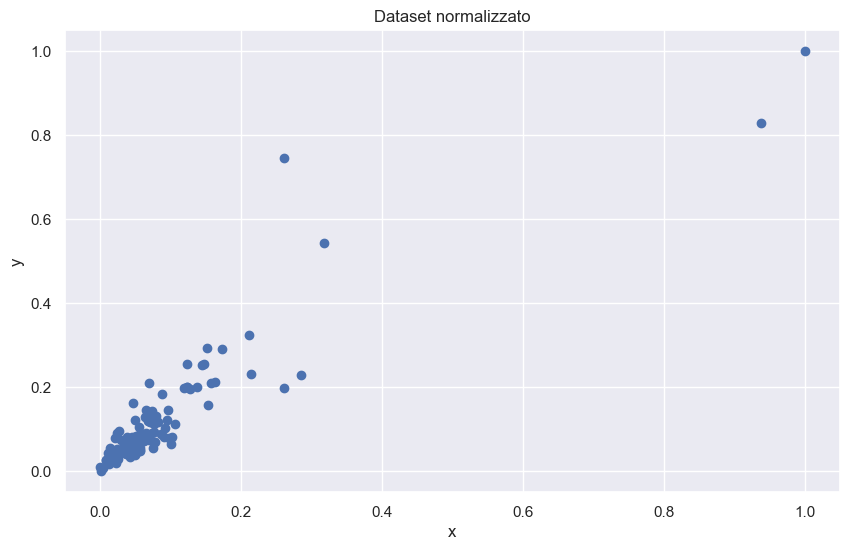

In [ ]:
# Aggiungo titoli ed etichette
plt.figure(figsize=(10, 6))
plt.scatter(incidenti_x_provincia_solo_numeri['Incidenti_medi'], incidenti_x_provincia_solo_numeri['Popolazione'], marker="o")
plt.title('Dataset normalizzato')
plt.xlabel('x')
plt.ylabel('y')



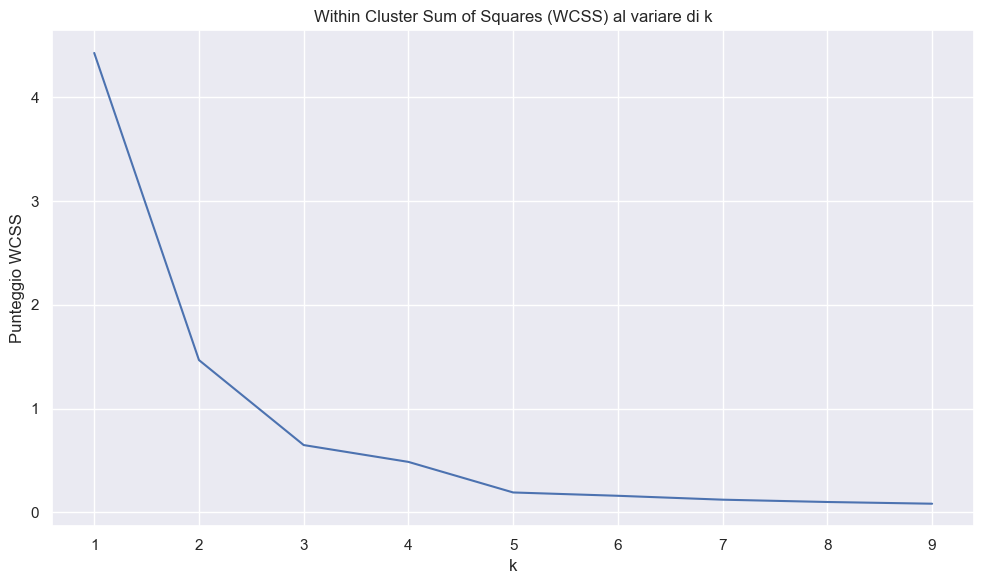

In [ ]:

### Uso il WCSS per trovare un buon valore di k
k_values = list(range(1,10))
wcss_list = []

for k in k_values:
	kmeans_n = KMeans(n_clusters = k, random_state=42)
	kmeans_n.fit(incidenti_x_provincia_solo_numeri)
	wcss_list.append(kmeans_n.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list)
plt.title("Within Cluster Sum of Squares (WCSS) al variare di k")
plt.xlabel("k")
plt.ylabel("Punteggio WCSS")
plt.tight_layout()
plt.show()


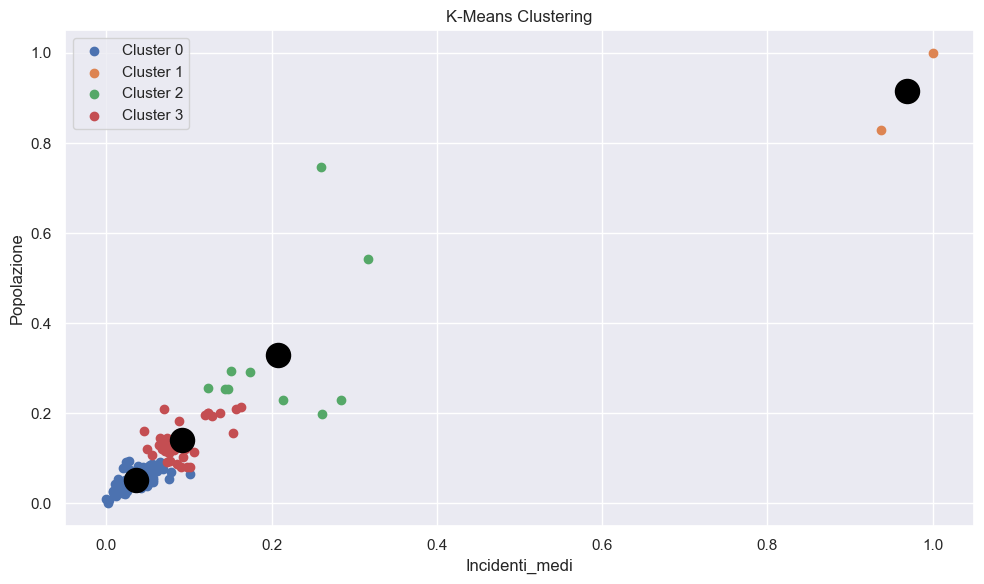

In [220]:
# Istanzio e adatto il modello KMeans
kmeans_4 = KMeans(n_clusters=4, random_state=42)
kmeans_4.fit(incidenti_x_provincia_solo_numeri[['Incidenti_medi', 'Popolazione']])

# Aggiungo le etichette di cluster al DataFrame
incidenti_x_provincia_solo_numeri["cluster"] = kmeans_4.labels_

# Rappresento graficamente i cluster e i centroidi
centroids = kmeans_4.cluster_centers_
clusters = incidenti_x_provincia_solo_numeri.groupby("cluster")

plt.figure(figsize=(10, 6))
for cluster, data in clusters:
    plt.scatter(data['Incidenti_medi'], data['Popolazione'], marker='o', label=f'Cluster {cluster}')
    plt.scatter(centroids[cluster, 0], centroids[cluster, 1], marker='o', color="black", s=300)

plt.xlabel('Incidenti_medi')
plt.ylabel('Popolazione')
plt.title("K-Means Clustering")
plt.legend()
plt.tight_layout()



In [221]:
#come si nota dal grafico, ma come un po mi sinceramente mi aspettavo, le città molto popolose e con molti incidenti vanno ad influenzare il grafico.
#non me la sento di prenderlo come valido

In [222]:
#mi piacerebbe provare a clusterizzare le Province per popolazione-km^2
provincia = provincia_anno.groupby(['Regione','Provincia',]).agg(Superficie=('Superficie','mean'), Popolazione = ('Popolazione', 'mean')).reset_index()
provincia['Superficie'] = np.ceil(provincia['Superficie'])
provincia['Popolazione'] = np.ceil(provincia['Popolazione'])
provincia


,Regione,Provincia,Superficie,Popolazione
0,Abruzzo,Chieti,2600.0,384496.0
1,Abruzzo,L'Aquila,5048.0,299427.0
2,Abruzzo,Pescara,1231.0,313338.0
3,Abruzzo,Teramo,1955.0,302576.0
4,Basilicata,Matera,3479.0,198435.0
...,...,...,...,...
105,Veneto,Rovigo,1820.0,238682.0
106,Veneto,Treviso,2480.0,866654.0
107,Veneto,Venezia,2474.0,839756.0
108,Veneto,Verona,3097.0,899206.0


Text(0, 0.5, 'Popolazione')

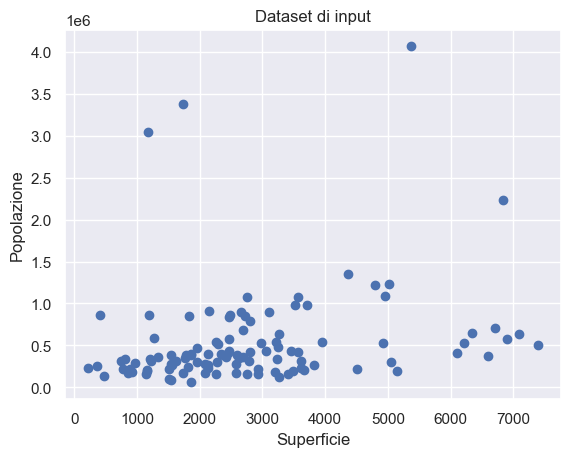

In [224]:
plt.scatter(provincia['Superficie'], provincia['Popolazione'], marker="o")
plt.title('Dataset di input')
plt.xlabel('Superficie')
plt.ylabel('Popolazione')


In [225]:
# normalizzo i dati
scale_norm = MinMaxScaler()
provincia_solo_numeri = provincia[['Superficie','Popolazione']]
provincia_solo_numeri = pd.DataFrame(scale_norm.fit_transform(provincia_solo_numeri), columns = provincia_solo_numeri.columns)


Text(0, 0.5, 'y')

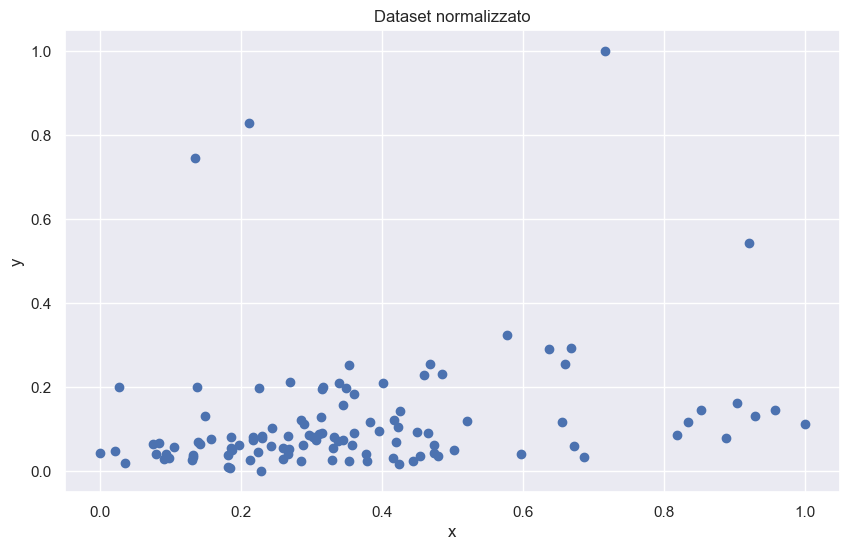

In [226]:
# Aggiungo titoli ed etichette
plt.figure(figsize=(10, 6))
plt.scatter(provincia_solo_numeri['Superficie'], provincia_solo_numeri['Popolazione'], marker="o")
plt.title('Dataset normalizzato')
plt.xlabel('x')
plt.ylabel('y')



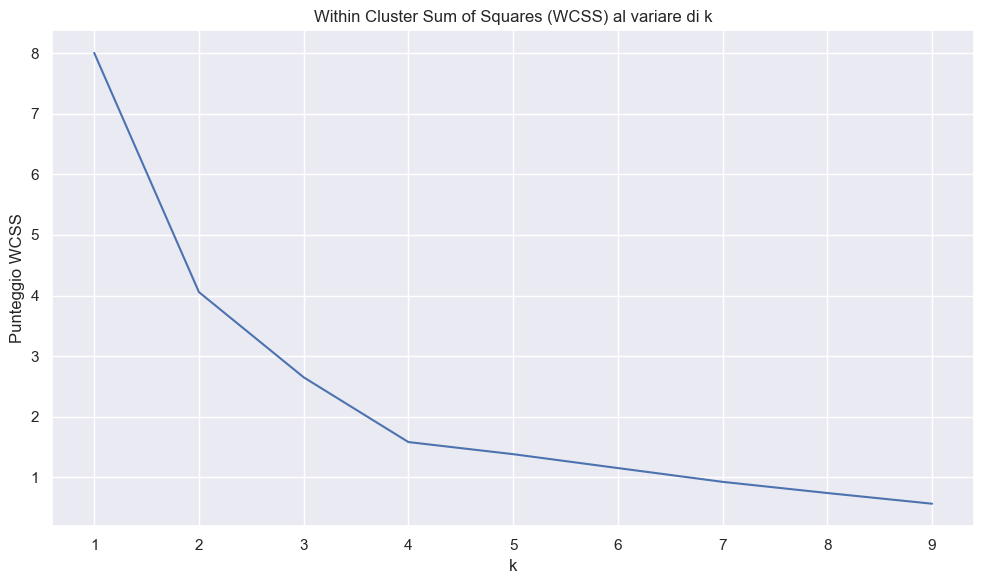

In [227]:
### Uso il WCSS per trovare un buon valore di k
k_values = list(range(1,10))
wcss_list = []

for k in k_values:
	kmeans_n = KMeans(n_clusters = k, random_state=42)
	kmeans_n.fit(provincia_solo_numeri)
	wcss_list.append(kmeans_n.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list)
plt.title("Within Cluster Sum of Squares (WCSS) al variare di k")
plt.xlabel("k")
plt.ylabel("Punteggio WCSS")
plt.tight_layout()


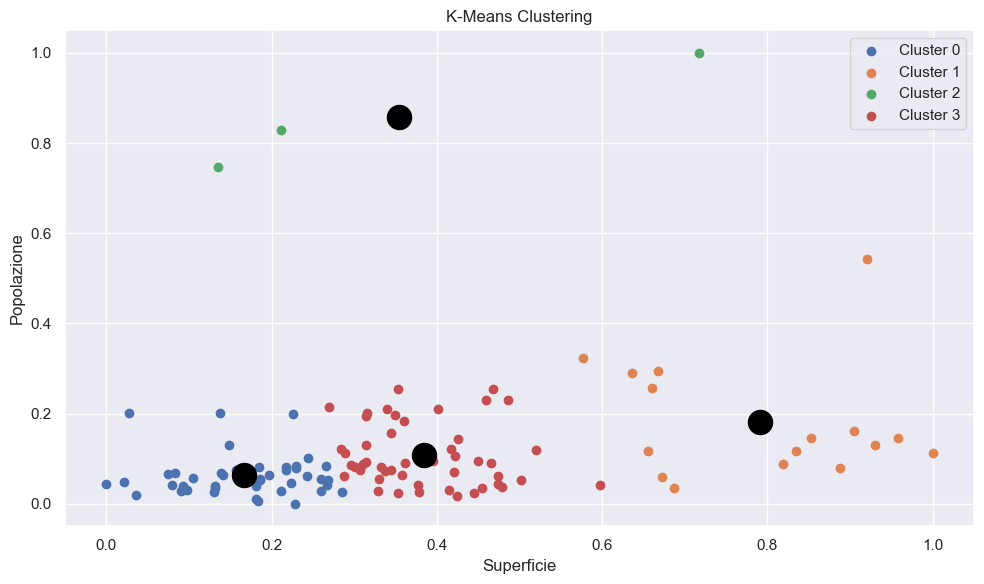

In [228]:
# Istanzio e adatto il modello KMeans
kmeans_4 = KMeans(n_clusters=4, random_state=42)
kmeans_4.fit(provincia_solo_numeri[['Superficie', 'Popolazione']])

# Aggiungo le etichette di cluster al DataFrame
provincia_solo_numeri["cluster"] = kmeans_4.labels_

# Rappresento graficamente i cluster e i centroidi
centroids = kmeans_4.cluster_centers_
clusters = provincia_solo_numeri.groupby("cluster")

plt.figure(figsize=(10, 6))
for cluster, data in clusters:
    plt.scatter(data['Superficie'], data['Popolazione'], marker='o', label=f'Cluster {cluster}')
    plt.scatter(centroids[cluster, 0], centroids[cluster, 1], marker='o', color="black", s=300)

plt.xlabel('Superficie')
plt.ylabel('Popolazione')
plt.title("K-Means Clustering")
plt.legend()
plt.tight_layout()


In [229]:
#personalmente, non ritengo che questa classificazione sia malvagia, ma allo stesso tempo i gruppi non sono ben separati come da teoria.
# inltre notiamo come i cluster 0,1,3 sono divisi solo per questioni di superficie

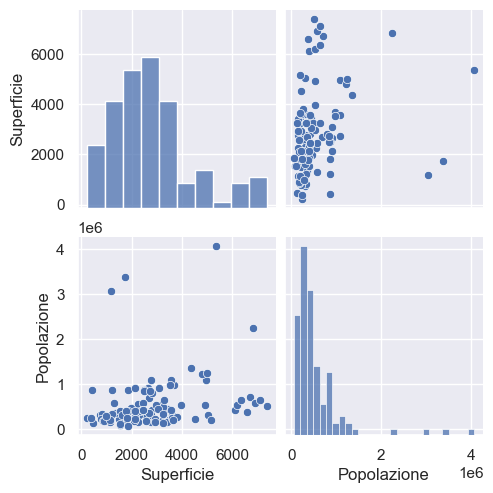

In [230]:
sns.pairplot(provincia,)

In [231]:
#però potrebbe essere interessante la popolazione (densità) con il numero di incidenti ogni 1000 abitanti
provincia = incidenti_x_provincia.copy()
provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenti_anno_100.000_abitanti,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,142.05,20.38,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,369.50,43.89,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,415.46,98.79,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,339.28,35.53,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,461.68,78.63,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,268.25,22.41,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,359.48,104.37,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,145.23,20.32,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,290.60,90.57,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436


In [232]:
provincia['densità_logaritmica'] = np.log10(provincia['Densità'])
provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,densità_logaritmica
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,20.38,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201,2.158362
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,43.89,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697,2.075547
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,98.79,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978,2.376577
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,35.53,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597,2.021189
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,78.63,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663,2.232996
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,22.41,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484,1.924279
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,104.37,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466,2.463893
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,20.32,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581,2.146128
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,90.57,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436,2.494155


Text(0, 0.5, 'densità_logaritmica')

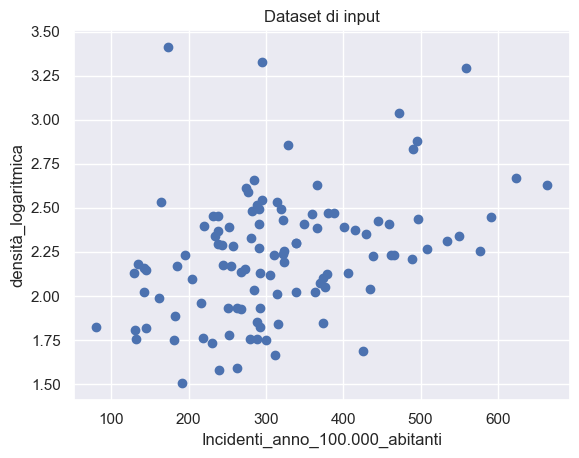

In [233]:
#plt.figure(figsize=(10, 6))
plt.scatter(provincia['Incidenti_anno_100.000_abitanti'], provincia['densità_logaritmica'], marker="o")
plt.title('Dataset di input')
plt.xlabel('Incidenti_anno_100.000_abitanti')
plt.ylabel('densità_logaritmica')


In [234]:
# normalizzo i dati
scale_norm = MinMaxScaler()
provincia_solo_numeri = provincia[['Incidenti_anno_100.000_abitanti','densità_logaritmica']]
provincia_solo_numeri = pd.DataFrame(scale_norm.fit_transform(provincia_solo_numeri), columns = provincia_solo_numeri.columns)


Text(0, 0.5, 'y')

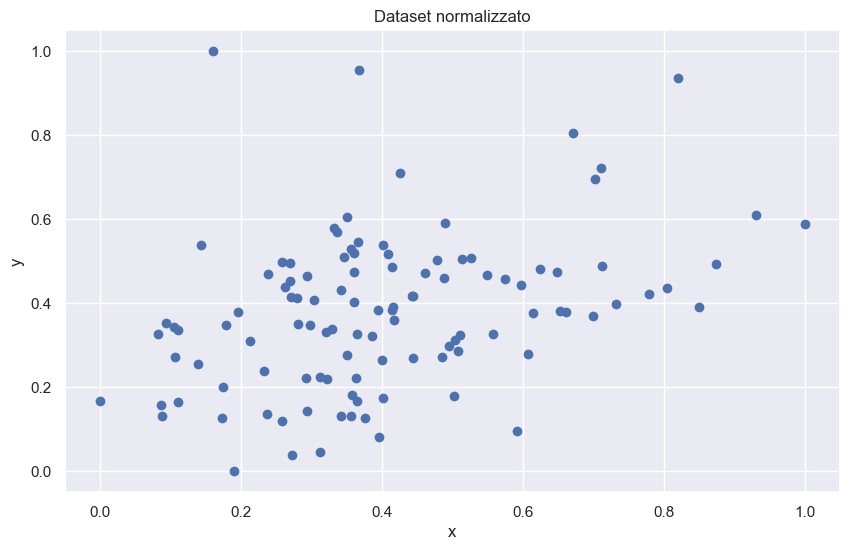

In [235]:
# Aggiungo titoli ed etichette
plt.figure(figsize=(10, 6))
plt.scatter(provincia_solo_numeri['Incidenti_anno_100.000_abitanti'], provincia_solo_numeri['densità_logaritmica'], marker="o")
plt.title('Dataset normalizzato')
plt.xlabel('x')
plt.ylabel('y')



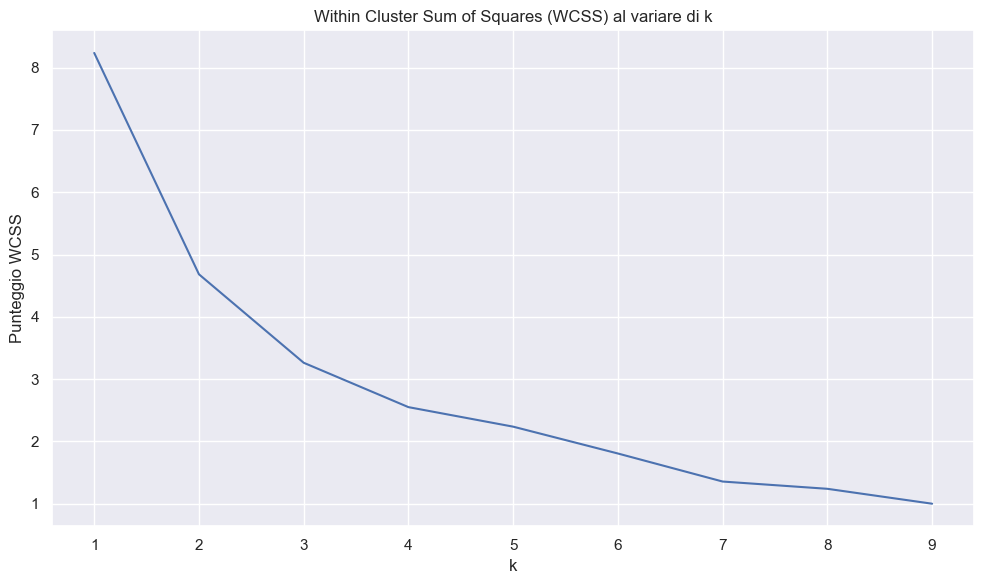

In [236]:
### Uso il WCSS per trovare un buon valore di k
k_values = list(range(1,10))
wcss_list = []

for k in k_values:
	kmeans_n = KMeans(n_clusters = k, random_state=42)
	kmeans_n.fit(provincia_solo_numeri)
	wcss_list.append(kmeans_n.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list)
plt.title("Within Cluster Sum of Squares (WCSS) al variare di k")
plt.xlabel("k")
plt.ylabel("Punteggio WCSS")
plt.tight_layout()


In [237]:
#a differenza dei grafici precedenti, questo non è così facile a colpo d'occhio, ma ritengo che anche qua k=4 sia il migliore (dove inizia ad esserci meno pendenza)
#inoltre, 4 gruppi potrebbero rappresentare bene quello che mi immagino: densità alta <-> incidenti alti, densità alta <->incidenti bassi, densità bassa <->incidenti alti, densità bassa <->incidenti bassi,


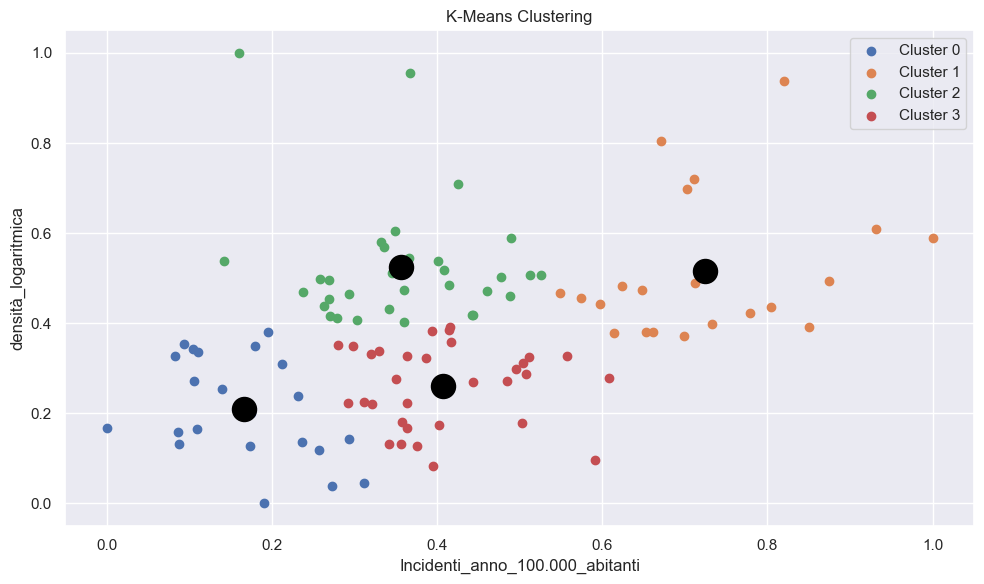

In [238]:
# Istanzio e adatto il modello KMeans
kmeans_4 = KMeans(n_clusters=4, random_state=42)
kmeans_4.fit(provincia_solo_numeri[['Incidenti_anno_100.000_abitanti', 'densità_logaritmica']])

# Aggiungo le etichette di cluster al DataFrame
provincia_solo_numeri["cluster"] = kmeans_4.labels_

# Rappresento graficamente i cluster e i centroidi
centroids = kmeans_4.cluster_centers_
clusters = provincia_solo_numeri.groupby("cluster")

plt.figure(figsize=(10, 6))
for cluster, data in clusters:
    plt.scatter(data['Incidenti_anno_100.000_abitanti'], data['densità_logaritmica'], marker='o', label=f'Cluster {cluster}')
    plt.scatter(centroids[cluster, 0], centroids[cluster, 1], marker='o', color="black", s=300)

plt.xlabel('Incidenti_anno_100.000_abitanti')
plt.ylabel('densità_logaritmica')
plt.title("K-Means Clustering")
plt.legend()
plt.tight_layout()


In [239]:
#cluster 0: incidenti ogni 100.000 abitanti bassi su densità bassa -> province rurali con pochi incidenti
#cluster 3: incidenti ogni 100.000 abitanti medi su densità bassa -> province non tanto dense con incidenti medi
#cluster 2: incidenti ogni 100.000 abitanti medi su densità alta -> province dense con incidenti medi (al netto di alcune citta da cui si vede i puntini verdi in alto con densita +- 0,8/1, che saranno sicuramente una coppia tra Napoli-Roma-Milano)
#cluster 1: incidenti ogni 100.000 abitanti alti su densità media -> province con tanti incidenti, mi aspetto a vedere dai grafici sopra, che siano città o turistiche, o molto di passaggio causa autostrade
#qui il cluster ci da una mano a segmentare i gruppi in modo abbastanza razionale, senza darci evidenza di gruppi 'nascosti'


In [240]:
provincia[['Incidenti_anno_100.000_abitanti', 'densità_logaritmica']].corr()


,Incidenti_anno_100.000_abitanti,densità_logaritmica
Incidenti_anno_100.000_abitanti,1.000000,0.369398
densità_logaritmica,0.369398,1.000000


In [241]:
#riporto il cluster sul df con i nomi delle province e i valori reali
provincia['Cluster'] = kmeans_4.labels_
provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,densità_logaritmica,Cluster
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201,2.158362,0
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697,2.075547,3
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978,2.376577,1
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597,2.021189,3
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663,2.232996,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484,1.924279,3
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466,2.463893,2
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581,2.146128,0
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436,2.494155,2


In [242]:
#rinomino il contenuto dper chiarezza dei cluster
provincia['Cluster'] = provincia['Cluster'].replace({0:'Incidenti bassi e densità bassa', 1:'Incidenti alti e densità media', 2: 'Incidenti medi e densità alta', 3: 'Incidenti medi e densita bassa'})
provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,densità_logaritmica,Cluster
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201,2.158362,Incidenti bassi e densità bassa
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697,2.075547,Incidenti medi e densita bassa
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978,2.376577,Incidenti alti e densità media
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597,2.021189,Incidenti medi e densita bassa
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663,2.232996,Incidenti alti e densità media
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484,1.924279,Incidenti medi e densita bassa
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466,2.463893,Incidenti medi e densità alta
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581,2.146128,Incidenti bassi e densità bassa
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436,2.494155,Incidenti medi e densità alta


In [243]:
#per completezza mi porto il cluster creato sulle due tabelle:
#delle province
incidenti_x_provincia = incidenti_x_provincia.merge(provincia[['Provincia', 'Cluster']], on='Provincia', how='left')
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,Cluster
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,20.38,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201,Incidenti bassi e densità bassa
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,43.89,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697,Incidenti medi e densita bassa
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,98.79,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978,Incidenti alti e densità media
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,35.53,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597,Incidenti medi e densita bassa
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,78.63,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663,Incidenti alti e densità media
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,22.41,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484,Incidenti medi e densita bassa
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,104.37,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466,Incidenti medi e densità alta
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,20.32,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581,Incidenti bassi e densità bassa
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,90.57,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436,Incidenti medi e densità alta


In [244]:
#dei comuni
incidenti_x_comune = incidenti_x_comune.merge(provincia[['Provincia', 'Cluster']], on='Provincia', how='left')
incidenti_x_comune

,Comune,Nome_Comune,Provincia,Regione,ZONA,Incidenti_tot,Feriti_tot,Morti_tot,Superficie,Popolazione,Incidenti_medi,Incidenti_100k_abitanti,Incidenti_kmq,Feriti_100_incidenti,Morti_100_incidenti,Cluster
0,1001,Agliè,Torino,Piemonte,Nord,95,161,1,13.146212,2630.541667,3.958333,150.5,0.30,169.47,1.05,Incidenti medi e densità alta
1,1002,Airasca,Torino,Piemonte,Nord,262,427,8,15.739300,3699.041667,10.916667,295.1,0.69,162.98,3.05,Incidenti medi e densità alta
2,1003,Ala di Stura,Torino,Piemonte,Nord,6,10,0,46.331513,463.875000,0.250000,53.9,0.01,166.67,0.00,Incidenti medi e densità alta
3,1004,Albiano d'Ivrea,Torino,Piemonte,Nord,107,165,10,11.732438,1696.000000,4.458333,262.9,0.38,154.21,9.35,Incidenti medi e densità alta
4,1005,Alice Superiore,Torino,Piemonte,Nord,21,34,5,7.379600,688.055556,0.875000,127.2,0.12,161.90,23.81,Incidenti medi e densità alta
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8573,111103,Villaputzu,Sulcis Iglesiente,Sardegna,Sud e Isole,48,70,5,181.340137,4529.625000,2.000000,44.2,0.01,145.83,10.42,Incidenti bassi e densità bassa
8574,111104,Villasalto,Sulcis Iglesiente,Sardegna,Sud e Isole,18,26,1,130.359600,981.000000,0.750000,76.5,0.01,144.44,5.56,Incidenti bassi e densità bassa
8575,111105,Villasimius,Sulcis Iglesiente,Sardegna,Sud e Isole,54,74,5,58.048537,3707.500000,2.250000,60.7,0.04,137.04,9.26,Incidenti bassi e densità bassa
8576,111106,Villasor,Sulcis Iglesiente,Sardegna,Sud e Isole,104,157,11,86.801075,6692.125000,4.333333,64.8,0.05,150.96,10.58,Incidenti bassi e densità bassa


In [245]:
#apro le tabelle che esporterò su PowerBI

In [246]:
df_incidenti_tot


,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densità_abitativa[n_abit/kmq],ZONA,Incidenti_pro_capite_anno,Incidenti_anno_1000_abitanti,Incidenti_per_superficie_anno,Incidenti_per_superficie_anno_10_kmq
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196,1.955,0.38034,3.803
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197,1.970,0.38034,3.803
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155,1.546,0.30427,3.043
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336,3.359,0.68461,6.846
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075,0.748,0.15214,1.521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078,0.785,0.07355,0.735
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197,1.972,0.18387,1.839
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039,0.388,0.03677,0.368
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153,1.529,0.14709,1.471


In [247]:
regioni_anno


,Regione,Anno,ZONA,Incidenti,Feriti,Morti,Superficie,Popolazione
0,Abruzzo,2001,Sud e Isole,5574,8342,168,10831.5370,1262187.0
1,Abruzzo,2002,Sud e Isole,5495,8496,185,10831.5370,1267633.0
2,Abruzzo,2003,Sud e Isole,5286,8066,154,10831.5370,1278658.0
3,Abruzzo,2004,Sud e Isole,4977,7544,141,10831.5370,1287157.0
4,Abruzzo,2005,Sud e Isole,4814,7225,134,10831.5370,1292999.0
...,...,...,...,...,...,...,...,...
475,Veneto,2020,Nord,9839,12919,229,18345.3694,4869830.0
476,Veneto,2021,Nord,12403,16512,285,18345.3694,4847745.0
477,Veneto,2022,Nord,13220,17286,321,18355.2293,4849553.0
478,Veneto,2023,Nord,12774,16994,309,18355.2293,4852216.0


In [248]:
provincia_anno


,Provincia,Anno,Regione,ZONA,Incidenti,Feriti,Morti,Superficie,Popolazione
0,Agrigento,2001,Sicilia,Sud e Isole,760,1245,20,3052.5443,447719.0
1,Agrigento,2002,Sicilia,Sud e Isole,869,1360,26,3052.5443,447896.0
2,Agrigento,2003,Sicilia,Sud e Isole,749,1200,32,3052.5443,448937.0
3,Agrigento,2004,Sicilia,Sud e Isole,746,1148,31,3052.5443,448738.0
4,Agrigento,2005,Sicilia,Sud e Isole,748,1223,36,3052.5443,448752.0
...,...,...,...,...,...,...,...,...,...
2564,Viterbo,2020,Lazio,Centro,621,899,18,3615.1635,308830.0
2565,Viterbo,2021,Lazio,Centro,713,1018,12,3615.1635,308737.0
2566,Viterbo,2022,Lazio,Centro,787,1171,16,3615.9772,308158.0
2567,Viterbo,2023,Lazio,Centro,802,1143,18,3615.9772,307686.0


In [249]:
comune_anno


,Comune,Nome_Comune,Provincia,Regione,ZONA,Anno,Incidenti,Feriti,Morti,Superficie,Popolazione
0,1001,Agliè,Torino,Piemonte,Nord,2001,5,10,0,13.1462,2557.0
1,1001,Agliè,Torino,Piemonte,Nord,2002,5,10,0,13.1462,2538.0
2,1001,Agliè,Torino,Piemonte,Nord,2003,4,7,0,13.1462,2588.0
3,1001,Agliè,Torino,Piemonte,Nord,2004,9,13,0,13.1462,2679.0
4,1001,Agliè,Torino,Piemonte,Nord,2005,2,2,0,13.1462,2674.0
...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2020,2,3,0,27.1937,2549.0
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2021,5,7,0,27.1937,2536.0
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2022,1,1,0,27.1943,2575.0
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2023,4,5,0,27.1943,2616.0


In [250]:
incidenti_x_regioni


,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,Incidenti_anno_100000_abitanti,Incidenti_per_superficie_anno_1000_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti,Morti_anno_100000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti
0,Abruzzo,Sud e Isole,91382,3808.0,136746,5698.0,2395,100.0,10832.0,1299835.0,293.0,352.0,1.91,2.04,2.35,439.0,7.68,120.0,1.496,2.621
1,Basilicata,Sud e Isole,22187,925.0,36414,1518.0,1001,42.0,10074.0,570637.0,163.0,92.0,0.46,0.54,0.98,266.0,7.31,57.0,1.641,4.512
2,Calabria,Sud e Isole,77766,3241.0,128918,5372.0,2913,122.0,15222.0,1939214.0,168.0,213.0,1.63,1.92,2.86,277.0,6.26,128.0,1.658,3.746
3,Campania,Sud e Isole,246143,10256.0,368176,15341.0,6591,275.0,13672.0,5738136.0,179.0,751.0,5.15,5.49,6.47,268.0,4.79,420.0,1.496,2.678
4,Emilia-Romagna,Nord,477672,19903.0,649931,27081.0,10587,442.0,22335.0,4327563.0,460.0,892.0,9.99,9.69,10.39,626.0,10.19,194.0,1.361,2.216
5,Friuli-Venezia Giulia,Nord,96881,4037.0,128681,5362.0,2551,107.0,7883.0,1207774.0,335.0,513.0,2.03,1.92,2.50,444.0,8.80,154.0,1.328,2.633
6,Lazio,Centro,590275,24595.0,811262,33803.0,10673,445.0,17233.0,5558388.0,443.0,1428.0,12.35,12.09,10.47,609.0,8.00,323.0,1.374,1.808
7,Liguria,Nord,212617,8860.0,271053,11294.0,2178,91.0,5416.0,1558385.0,569.0,1636.0,4.45,4.04,2.14,725.0,5.82,288.0,1.275,1.024
8,Lombardia,Nord,903572,37649.0,1223723,50989.0,14333,598.0,23863.0,9725180.0,388.0,1578.0,18.91,18.24,14.06,525.0,6.14,408.0,1.354,1.586
9,Marche,Centro,147992,6167.0,211375,8808.0,2935,123.0,9518.0,1519493.0,406.0,648.0,3.10,3.15,2.88,580.0,8.05,160.0,1.428,1.983


In [251]:
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenti_per_superficie_anno_100_kmq,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,Cluster
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,20.38,0.31,0.36,0.47,231.67,4.55,144.0,1.631,3.201,Incidenti bassi e densità bassa
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,43.89,0.78,0.78,0.99,516.01,9.96,119.0,1.396,2.697,Incidenti medi e densita bassa
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,98.79,0.97,1.02,0.90,608.31,8.22,238.0,1.464,1.978,Incidenti alti e densità media
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,35.53,0.58,0.58,0.70,476.65,8.81,105.0,1.405,2.597,Incidenti medi e densita bassa
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,78.63,0.61,0.61,0.48,642.58,7.68,171.0,1.392,1.663,Incidenti alti e densità media
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,22.41,0.23,0.24,0.49,385.01,12.03,84.0,1.435,4.484,Incidenti medi e densita bassa
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,104.37,1.62,1.56,1.88,485.25,8.86,291.0,1.350,2.466,Incidenti medi e densità alta
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,20.32,0.12,0.14,0.20,240.52,5.20,140.0,1.656,3.581,Incidenti bassi e densità bassa
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,90.57,1.24,1.19,1.41,392.42,7.08,312.0,1.350,2.436,Incidenti medi e densità alta


In [252]:
incidenti_x_comune




,Comune,Nome_Comune,Provincia,Regione,ZONA,Incidenti_tot,Feriti_tot,Morti_tot,Superficie,Popolazione,Incidenti_medi,Incidenti_100k_abitanti,Incidenti_kmq,Feriti_100_incidenti,Morti_100_incidenti,Cluster
0,1001,Agliè,Torino,Piemonte,Nord,95,161,1,13.146212,2630.541667,3.958333,150.5,0.30,169.47,1.05,Incidenti medi e densità alta
1,1002,Airasca,Torino,Piemonte,Nord,262,427,8,15.739300,3699.041667,10.916667,295.1,0.69,162.98,3.05,Incidenti medi e densità alta
2,1003,Ala di Stura,Torino,Piemonte,Nord,6,10,0,46.331513,463.875000,0.250000,53.9,0.01,166.67,0.00,Incidenti medi e densità alta
3,1004,Albiano d'Ivrea,Torino,Piemonte,Nord,107,165,10,11.732438,1696.000000,4.458333,262.9,0.38,154.21,9.35,Incidenti medi e densità alta
4,1005,Alice Superiore,Torino,Piemonte,Nord,21,34,5,7.379600,688.055556,0.875000,127.2,0.12,161.90,23.81,Incidenti medi e densità alta
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8573,111103,Villaputzu,Sulcis Iglesiente,Sardegna,Sud e Isole,48,70,5,181.340137,4529.625000,2.000000,44.2,0.01,145.83,10.42,Incidenti bassi e densità bassa
8574,111104,Villasalto,Sulcis Iglesiente,Sardegna,Sud e Isole,18,26,1,130.359600,981.000000,0.750000,76.5,0.01,144.44,5.56,Incidenti bassi e densità bassa
8575,111105,Villasimius,Sulcis Iglesiente,Sardegna,Sud e Isole,54,74,5,58.048537,3707.500000,2.250000,60.7,0.04,137.04,9.26,Incidenti bassi e densità bassa
8576,111106,Villasor,Sulcis Iglesiente,Sardegna,Sud e Isole,104,157,11,86.801075,6692.125000,4.333333,64.8,0.05,150.96,10.58,Incidenti bassi e densità bassa


In [253]:
#creo io le classi di grandezza per POPOLAZIONE:
# -COMUNE
bins_pop_com = [0, 5000, 20000, 50000, 250000, np.inf]
labels_pop_com = ['Molto piccolo (<5k)', 'Piccolo (5k-20k)', 'Medio (20k-50k)', 'Grande (50k-250k)', 'Città (>250k)']
incidenti_x_comune['Classe_popolazione'] = pd.cut(incidenti_x_comune['Popolazione'], bins=bins_pop_com, labels=labels_pop_com, right=True)


In [254]:
# -PROVINCIA
bins_pop_prov = [0, 250000, 500000, 1000000, np.inf]
labels_pop_prov = ['Piccola (<250k)', 'Media (250k-500k)', 'Grande (500k-1M)', 'Metropolitana (>1M)']
incidenti_x_provincia['Classe_popolazione'] = pd.cut(incidenti_x_provincia['Popolazione'],bins=bins_pop_prov, labels=labels_pop_prov, right=True)


In [255]:
# -REGIONE
bins_pop_reg = [0, 1500000, 4000000, np.inf]
labels_pop_reg = ['Piccola (<1,5M)', 'Media (1,5-4M)', 'Grande (>4M)']
incidenti_x_regioni['Classe_popolazione'] = pd.cut(incidenti_x_regioni['Popolazione'],bins=bins_pop_reg, labels=labels_pop_reg, right=True)


In [256]:
#creo io le classi di grandezza per superifce:
# -COMUNE
bins_sup_com = [0, 10, 25, 50, 100, np.inf]
labels_sup_com = ['<10 kmq', '10-25 kmq', '25-50 kmq', '50-100 kmq', '>100 kmq']
incidenti_x_comune['Classe_superficie'] = pd.cut(incidenti_x_comune['Superficie'], bins=bins_sup_com, labels=labels_sup_com, right=True)
incidenti_x_comune


,Comune,Nome_Comune,Provincia,Regione,ZONA,Incidenti_tot,Feriti_tot,Morti_tot,Superficie,Popolazione,Incidenti_medi,Incidenti_100k_abitanti,Incidenti_kmq,Feriti_100_incidenti,Morti_100_incidenti,Cluster,Classe_popolazione,Classe_superficie
0,1001,Agliè,Torino,Piemonte,Nord,95,161,1,13.146212,2630.541667,3.958333,150.5,0.30,169.47,1.05,Incidenti medi e densità alta,Molto piccolo (<5k),10-25 kmq
1,1002,Airasca,Torino,Piemonte,Nord,262,427,8,15.739300,3699.041667,10.916667,295.1,0.69,162.98,3.05,Incidenti medi e densità alta,Molto piccolo (<5k),10-25 kmq
2,1003,Ala di Stura,Torino,Piemonte,Nord,6,10,0,46.331513,463.875000,0.250000,53.9,0.01,166.67,0.00,Incidenti medi e densità alta,Molto piccolo (<5k),25-50 kmq
3,1004,Albiano d'Ivrea,Torino,Piemonte,Nord,107,165,10,11.732438,1696.000000,4.458333,262.9,0.38,154.21,9.35,Incidenti medi e densità alta,Molto piccolo (<5k),10-25 kmq
4,1005,Alice Superiore,Torino,Piemonte,Nord,21,34,5,7.379600,688.055556,0.875000,127.2,0.12,161.90,23.81,Incidenti medi e densità alta,Molto piccolo (<5k),<10 kmq
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8573,111103,Villaputzu,Sulcis Iglesiente,Sardegna,Sud e Isole,48,70,5,181.340137,4529.625000,2.000000,44.2,0.01,145.83,10.42,Incidenti bassi e densità bassa,Molto piccolo (<5k),>100 kmq
8574,111104,Villasalto,Sulcis Iglesiente,Sardegna,Sud e Isole,18,26,1,130.359600,981.000000,0.750000,76.5,0.01,144.44,5.56,Incidenti bassi e densità bassa,Molto piccolo (<5k),>100 kmq
8575,111105,Villasimius,Sulcis Iglesiente,Sardegna,Sud e Isole,54,74,5,58.048537,3707.500000,2.250000,60.7,0.04,137.04,9.26,Incidenti bassi e densità bassa,Molto piccolo (<5k),50-100 kmq
8576,111106,Villasor,Sulcis Iglesiente,Sardegna,Sud e Isole,104,157,11,86.801075,6692.125000,4.333333,64.8,0.05,150.96,10.58,Incidenti bassi e densità bassa,Piccolo (5k-20k),50-100 kmq


In [257]:
# -PROVINCIA
bins_sup_prov = [0, 1500, 3000, 5000, np.inf]
labels_sup_prov = ['<1.500 kmq', '1.500-3.000 kmq', '3.000-5.000 kmq', '>5.000 kmq']
incidenti_x_provincia['Classe_superficie'] = pd.cut(incidenti_x_provincia['Superficie'],bins=bins_sup_prov, labels=labels_sup_prov)
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Incidenza feriti,Incidenza morti,Feriti_anno_100.000_abitanti,Morti_anno_100.000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,Cluster,Classe_popolazione,Classe_superficie
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,0.36,0.47,231.67,4.55,144.0,1.631,3.201,Incidenti bassi e densità bassa,Media (250k-500k),3.000-5.000 kmq
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,0.78,0.99,516.01,9.96,119.0,1.396,2.697,Incidenti medi e densita bassa,Media (250k-500k),3.000-5.000 kmq
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,1.02,0.90,608.31,8.22,238.0,1.464,1.978,Incidenti alti e densità media,Media (250k-500k),1.500-3.000 kmq
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,0.58,0.70,476.65,8.81,105.0,1.405,2.597,Incidenti medi e densita bassa,Media (250k-500k),3.000-5.000 kmq
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,0.61,0.48,642.58,7.68,171.0,1.392,1.663,Incidenti alti e densità media,Media (250k-500k),1.500-3.000 kmq
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,0.24,0.49,385.01,12.03,84.0,1.435,4.484,Incidenti medi e densita bassa,Piccola (<250k),1.500-3.000 kmq
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,1.56,1.88,485.25,8.86,291.0,1.350,2.466,Incidenti medi e densità alta,Grande (500k-1M),3.000-5.000 kmq
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,0.14,0.20,240.52,5.20,140.0,1.656,3.581,Incidenti bassi e densità bassa,Piccola (<250k),<1.500 kmq
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,1.19,1.41,392.42,7.08,312.0,1.350,2.436,Incidenti medi e densità alta,Grande (500k-1M),1.500-3.000 kmq


In [258]:
# -REGIONE
bins_sup_reg = [0, 10000, 20000, np.inf]
labels_sup_reg = ['Piccola (<10.000 kmq)', 'Media (10.000-20.000 kmq)', 'Grande (>20.000 kmq)']
incidenti_x_regioni['Classe_superficie'] = pd.cut(incidenti_x_regioni['Superficie'], bins=bins_sup_reg, labels=labels_sup_reg, right=True)
incidenti_x_regioni


,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,...,Incidenza incidenti,Incidenza feriti,Incidenza morti,Feriti_anno_100000_abitanti,Morti_anno_100000_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,Classe_popolazione,Classe_superficie
0,Abruzzo,Sud e Isole,91382,3808.0,136746,5698.0,2395,100.0,10832.0,1299835.0,...,1.91,2.04,2.35,439.0,7.68,120.0,1.496,2.621,"Piccola (<1,5M)",Media (10.000-20.000 kmq)
1,Basilicata,Sud e Isole,22187,925.0,36414,1518.0,1001,42.0,10074.0,570637.0,...,0.46,0.54,0.98,266.0,7.31,57.0,1.641,4.512,"Piccola (<1,5M)",Media (10.000-20.000 kmq)
2,Calabria,Sud e Isole,77766,3241.0,128918,5372.0,2913,122.0,15222.0,1939214.0,...,1.63,1.92,2.86,277.0,6.26,128.0,1.658,3.746,"Media (1,5-4M)",Media (10.000-20.000 kmq)
3,Campania,Sud e Isole,246143,10256.0,368176,15341.0,6591,275.0,13672.0,5738136.0,...,5.15,5.49,6.47,268.0,4.79,420.0,1.496,2.678,Grande (>4M),Media (10.000-20.000 kmq)
4,Emilia-Romagna,Nord,477672,19903.0,649931,27081.0,10587,442.0,22335.0,4327563.0,...,9.99,9.69,10.39,626.0,10.19,194.0,1.361,2.216,Grande (>4M),Grande (>20.000 kmq)
5,Friuli-Venezia Giulia,Nord,96881,4037.0,128681,5362.0,2551,107.0,7883.0,1207774.0,...,2.03,1.92,2.50,444.0,8.80,154.0,1.328,2.633,"Piccola (<1,5M)",Piccola (<10.000 kmq)
6,Lazio,Centro,590275,24595.0,811262,33803.0,10673,445.0,17233.0,5558388.0,...,12.35,12.09,10.47,609.0,8.00,323.0,1.374,1.808,Grande (>4M),Media (10.000-20.000 kmq)
7,Liguria,Nord,212617,8860.0,271053,11294.0,2178,91.0,5416.0,1558385.0,...,4.45,4.04,2.14,725.0,5.82,288.0,1.275,1.024,"Media (1,5-4M)",Piccola (<10.000 kmq)
8,Lombardia,Nord,903572,37649.0,1223723,50989.0,14333,598.0,23863.0,9725180.0,...,18.91,18.24,14.06,525.0,6.14,408.0,1.354,1.586,Grande (>4M),Grande (>20.000 kmq)
9,Marche,Centro,147992,6167.0,211375,8808.0,2935,123.0,9518.0,1519493.0,...,3.10,3.15,2.88,580.0,8.05,160.0,1.428,1.983,"Media (1,5-4M)",Piccola (<10.000 kmq)


In [259]:
#guardo quante province ci sono rispetto la grandezza
incidenti_x_provincia['Classe_popolazione'].value_counts().sort_index()


Classe_popolazione
Piccola (<250k)        31
Media (250k-500k)      41
Grande (500k-1M)       28
Metropolitana (>1M)    10
Name: count, dtype: int64

In [260]:
#guardo quanti comuni ci sono rispetto la grandezza
incidenti_x_comune['Classe_popolazione'].value_counts().sort_index()


Classe_popolazione
Molto piccolo (<5k)    6054
Piccolo (5k-20k)       1993
Medio (20k-50k)         382
Grande (50k-250k)       137
Città (>250k)            12
Name: count, dtype: int64

In [261]:
#guardo quante regioni ci sono rispetto la grandezza
incidenti_x_regioni['Classe_popolazione'].value_counts().sort_index()


Classe_popolazione
Piccola (<1,5M)    7
Media (1,5-4M)     5
Grande (>4M)       8
Name: count, dtype: int64

In [262]:
#i nomi delle colonne fanno abbastanza schifetto, le rinomino qua così poi su poer bi sono già pronte
nomi_nuovi_colonne = {'Incidenti_anno_100.000_abitanti': 'Incidenti_100k_abitanti', 'Feriti_anno_100.000_abitanti': 'Feriti_100k_abitanti', 'Morti_anno_100.000_abitanti': 'Morti_100k_abitanti', 'Incidenti_anno_100000_abitanti': 'Incidenti_100k_abitanti', 'Feriti_anno_100000_abitanti': 'Feriti_100k_abitanti', 'Morti_anno_100000_abitanti': 'Morti_100k_abitanti', 'Densità_abitativa[n_abit/kmq]': 'Densita_abitativa', 'Popolazione residente': 'Popolazione_residente', 'Incidenza incidenti': 'Quota_incidenti_perc', 'Incidenza feriti': 'Quota_feriti_percentuale', 'Incidenza morti': 'Quota_morti_percentuale'}
tabelle = {'df_incidenti_tot':df_incidenti_tot, 'regioni_anno':regioni_anno, 'provincia_anno': provincia_anno, 'incidenti_x_regioni':incidenti_x_regioni, 'incidenti_x_provincia':incidenti_x_provincia}


In [263]:
#creo piccolo ciclo che mi modifica le colone
#uso .items() per scorrere il dizionario
for nomi, dataframe in tabelle.items():
      dataframe.rename(columns=nomi_nuovi_colonne, inplace = True)


In [264]:
df_incidenti_tot


,Comune,Nome_Comune,Provincia,Regione,Anno,N_incidenti,Feriti,Morti,Popolazione_residente,Superficie_comune,Superficie_provincia_anno,Popolazione_residente_PROVINCIA,Popolazione_residente_REGIONE,Superficie_regione_anno,Densita_abitativa,ZONA,Incidenti_pro_capite_anno,Incidenti_anno_1000_abitanti,Incidenti_per_superficie_anno,Incidenti_per_superficie_anno_10_kmq
0,1001,Agliè,Torino,Piemonte,2001,5,10,0,2557.0,13.1462,6826.8887,2165695.0,4212726.0,25386.6691,195.0,Nord,0.00196,1.955,0.38034,3.803
1,1001,Agliè,Torino,Piemonte,2002,5,10,0,2538.0,13.1462,6826.8887,2169876.0,4222134.0,25386.6691,194.0,Nord,0.00197,1.970,0.38034,3.803
2,1001,Agliè,Torino,Piemonte,2003,4,7,0,2588.0,13.1462,6826.8887,2189701.0,4260654.0,25386.6691,197.0,Nord,0.00155,1.546,0.30427,3.043
3,1001,Agliè,Torino,Piemonte,2004,9,13,0,2679.0,13.1462,6826.8887,2202292.0,4284486.0,25386.6691,204.0,Nord,0.00336,3.359,0.68461,6.846
4,1001,Agliè,Torino,Piemonte,2005,2,2,0,2674.0,13.1462,6826.8887,2208364.0,4296203.0,25386.6691,204.0,Nord,0.00075,0.748,0.15214,1.521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2020,2,3,0,2549.0,27.1937,6530.6730,338264.0,1590044.0,24099.4530,94.0,Sud e Isole,0.00078,0.785,0.07355,0.735
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2021,5,7,0,2536.0,27.1937,6530.6730,337178.0,1587413.0,24099.4530,94.0,Sud e Isole,0.00197,1.972,0.18387,1.839
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2022,1,1,0,2575.0,27.1943,6532.9875,334198.0,1578146.0,24108.5367,95.0,Sud e Isole,0.00039,0.388,0.03677,0.368
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,2023,4,5,0,2616.0,27.1943,6532.9875,331817.0,1570453.0,24108.5367,97.0,Sud e Isole,0.00153,1.529,0.14709,1.471


In [265]:
regioni_anno


,Regione,Anno,ZONA,Incidenti,Feriti,Morti,Superficie,Popolazione
0,Abruzzo,2001,Sud e Isole,5574,8342,168,10831.5370,1262187.0
1,Abruzzo,2002,Sud e Isole,5495,8496,185,10831.5370,1267633.0
2,Abruzzo,2003,Sud e Isole,5286,8066,154,10831.5370,1278658.0
3,Abruzzo,2004,Sud e Isole,4977,7544,141,10831.5370,1287157.0
4,Abruzzo,2005,Sud e Isole,4814,7225,134,10831.5370,1292999.0
...,...,...,...,...,...,...,...,...
475,Veneto,2020,Nord,9839,12919,229,18345.3694,4869830.0
476,Veneto,2021,Nord,12403,16512,285,18345.3694,4847745.0
477,Veneto,2022,Nord,13220,17286,321,18355.2293,4849553.0
478,Veneto,2023,Nord,12774,16994,309,18355.2293,4852216.0


In [266]:
provincia_anno


,Provincia,Anno,Regione,ZONA,Incidenti,Feriti,Morti,Superficie,Popolazione
0,Agrigento,2001,Sicilia,Sud e Isole,760,1245,20,3052.5443,447719.0
1,Agrigento,2002,Sicilia,Sud e Isole,869,1360,26,3052.5443,447896.0
2,Agrigento,2003,Sicilia,Sud e Isole,749,1200,32,3052.5443,448937.0
3,Agrigento,2004,Sicilia,Sud e Isole,746,1148,31,3052.5443,448738.0
4,Agrigento,2005,Sicilia,Sud e Isole,748,1223,36,3052.5443,448752.0
...,...,...,...,...,...,...,...,...,...
2564,Viterbo,2020,Lazio,Centro,621,899,18,3615.1635,308830.0
2565,Viterbo,2021,Lazio,Centro,713,1018,12,3615.1635,308737.0
2566,Viterbo,2022,Lazio,Centro,787,1171,16,3615.9772,308158.0
2567,Viterbo,2023,Lazio,Centro,802,1143,18,3615.9772,307686.0


In [267]:
comune_anno


,Comune,Nome_Comune,Provincia,Regione,ZONA,Anno,Incidenti,Feriti,Morti,Superficie,Popolazione
0,1001,Agliè,Torino,Piemonte,Nord,2001,5,10,0,13.1462,2557.0
1,1001,Agliè,Torino,Piemonte,Nord,2002,5,10,0,13.1462,2538.0
2,1001,Agliè,Torino,Piemonte,Nord,2003,4,7,0,13.1462,2588.0
3,1001,Agliè,Torino,Piemonte,Nord,2004,9,13,0,13.1462,2679.0
4,1001,Agliè,Torino,Piemonte,Nord,2005,2,2,0,13.1462,2674.0
...,...,...,...,...,...,...,...,...,...,...,...
191179,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2020,2,3,0,27.1937,2549.0
191180,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2021,5,7,0,27.1937,2536.0
191181,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2022,1,1,0,27.1943,2575.0
191182,111107,Villaspeciosa,Sulcis Iglesiente,Sardegna,Sud e Isole,2023,4,5,0,27.1943,2616.0


In [268]:
incidenti_x_regioni


,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,Popolazione,...,Quota_incidenti_perc,Quota_feriti_percentuale,Quota_morti_percentuale,Feriti_100k_abitanti,Morti_100k_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,Classe_popolazione,Classe_superficie
0,Abruzzo,Sud e Isole,91382,3808.0,136746,5698.0,2395,100.0,10832.0,1299835.0,...,1.91,2.04,2.35,439.0,7.68,120.0,1.496,2.621,"Piccola (<1,5M)",Media (10.000-20.000 kmq)
1,Basilicata,Sud e Isole,22187,925.0,36414,1518.0,1001,42.0,10074.0,570637.0,...,0.46,0.54,0.98,266.0,7.31,57.0,1.641,4.512,"Piccola (<1,5M)",Media (10.000-20.000 kmq)
2,Calabria,Sud e Isole,77766,3241.0,128918,5372.0,2913,122.0,15222.0,1939214.0,...,1.63,1.92,2.86,277.0,6.26,128.0,1.658,3.746,"Media (1,5-4M)",Media (10.000-20.000 kmq)
3,Campania,Sud e Isole,246143,10256.0,368176,15341.0,6591,275.0,13672.0,5738136.0,...,5.15,5.49,6.47,268.0,4.79,420.0,1.496,2.678,Grande (>4M),Media (10.000-20.000 kmq)
4,Emilia-Romagna,Nord,477672,19903.0,649931,27081.0,10587,442.0,22335.0,4327563.0,...,9.99,9.69,10.39,626.0,10.19,194.0,1.361,2.216,Grande (>4M),Grande (>20.000 kmq)
5,Friuli-Venezia Giulia,Nord,96881,4037.0,128681,5362.0,2551,107.0,7883.0,1207774.0,...,2.03,1.92,2.50,444.0,8.80,154.0,1.328,2.633,"Piccola (<1,5M)",Piccola (<10.000 kmq)
6,Lazio,Centro,590275,24595.0,811262,33803.0,10673,445.0,17233.0,5558388.0,...,12.35,12.09,10.47,609.0,8.00,323.0,1.374,1.808,Grande (>4M),Media (10.000-20.000 kmq)
7,Liguria,Nord,212617,8860.0,271053,11294.0,2178,91.0,5416.0,1558385.0,...,4.45,4.04,2.14,725.0,5.82,288.0,1.275,1.024,"Media (1,5-4M)",Piccola (<10.000 kmq)
8,Lombardia,Nord,903572,37649.0,1223723,50989.0,14333,598.0,23863.0,9725180.0,...,18.91,18.24,14.06,525.0,6.14,408.0,1.354,1.586,Grande (>4M),Grande (>20.000 kmq)
9,Marche,Centro,147992,6167.0,211375,8808.0,2935,123.0,9518.0,1519493.0,...,3.10,3.15,2.88,580.0,8.05,160.0,1.428,1.983,"Media (1,5-4M)",Piccola (<10.000 kmq)


In [269]:
incidenti_x_provincia


,Provincia,Regione,ZONA,Incidenti_tot,Incidenti_medi,Feriti_tot,Feriti_medi,Morti_tot,Morti_medi,Superficie,...,Quota_feriti_percentuale,Quota_morti_percentuale,Feriti_100k_abitanti,Morti_100k_abitanti,Densità,Rapp_feriti_su_incidenti,Rapp_morti_su_100_incidenti,Cluster,Classe_popolazione,Classe_superficie
0,Agrigento,Sicilia,Sud e Isole,14935,623.0,24357,1015.0,478,20.0,3053.0,...,0.36,0.47,231.67,4.55,144.0,1.631,3.201,Incidenti bassi e densità bassa,Media (250k-500k),3.000-5.000 kmq
1,Alessandria,Piemonte,Nord,37489,1563.0,52353,2182.0,1011,43.0,3559.0,...,0.78,0.99,516.01,9.96,119.0,1.396,2.697,Incidenti medi e densita bassa,Media (250k-500k),3.000-5.000 kmq
2,Ancona,Marche,Centro,46567,1941.0,68183,2841.0,921,39.0,1964.0,...,1.02,0.90,608.31,8.22,238.0,1.464,1.978,Incidenti alti e densità media,Media (250k-500k),1.500-3.000 kmq
3,Arezzo,Toscana,Centro,27570,1149.0,38732,1614.0,716,30.0,3233.0,...,0.58,0.70,476.65,8.81,105.0,1.405,2.597,Incidenti medi e densita bassa,Media (250k-500k),3.000-5.000 kmq
4,Ascoli Piceno,Marche,Centro,29287,1221.0,40762,1699.0,487,21.0,1552.0,...,0.61,0.48,642.58,7.68,171.0,1.392,1.663,Incidenti alti e densità media,Media (250k-500k),1.500-3.000 kmq
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,Vercelli,Piemonte,Nord,11196,467.0,16069,670.0,502,21.0,2082.0,...,0.24,0.49,385.01,12.03,84.0,1.435,4.484,Incidenti medi e densita bassa,Piccola (<250k),1.500-3.000 kmq
106,Verona,Veneto,Nord,77579,3233.0,104722,4364.0,1913,80.0,3097.0,...,1.56,1.88,485.25,8.86,291.0,1.350,2.466,Incidenti medi e densità alta,Grande (500k-1M),3.000-5.000 kmq
107,Vibo Valentia,Calabria,Sud e Isole,5613,234.0,9296,388.0,201,9.0,1151.0,...,0.14,0.20,240.52,5.20,140.0,1.656,3.581,Incidenti bassi e densità bassa,Piccola (<250k),<1.500 kmq
108,Vicenza,Veneto,Nord,59192,2467.0,79931,3331.0,1442,61.0,2723.0,...,1.19,1.41,392.42,7.08,312.0,1.350,2.436,Incidenti medi e densità alta,Grande (500k-1M),1.500-3.000 kmq


In [270]:
incidenti_x_comune



,Comune,Nome_Comune,Provincia,Regione,ZONA,Incidenti_tot,Feriti_tot,Morti_tot,Superficie,Popolazione,Incidenti_medi,Incidenti_100k_abitanti,Incidenti_kmq,Feriti_100_incidenti,Morti_100_incidenti,Cluster,Classe_popolazione,Classe_superficie
0,1001,Agliè,Torino,Piemonte,Nord,95,161,1,13.146212,2630.541667,3.958333,150.5,0.30,169.47,1.05,Incidenti medi e densità alta,Molto piccolo (<5k),10-25 kmq
1,1002,Airasca,Torino,Piemonte,Nord,262,427,8,15.739300,3699.041667,10.916667,295.1,0.69,162.98,3.05,Incidenti medi e densità alta,Molto piccolo (<5k),10-25 kmq
2,1003,Ala di Stura,Torino,Piemonte,Nord,6,10,0,46.331513,463.875000,0.250000,53.9,0.01,166.67,0.00,Incidenti medi e densità alta,Molto piccolo (<5k),25-50 kmq
3,1004,Albiano d'Ivrea,Torino,Piemonte,Nord,107,165,10,11.732438,1696.000000,4.458333,262.9,0.38,154.21,9.35,Incidenti medi e densità alta,Molto piccolo (<5k),10-25 kmq
4,1005,Alice Superiore,Torino,Piemonte,Nord,21,34,5,7.379600,688.055556,0.875000,127.2,0.12,161.90,23.81,Incidenti medi e densità alta,Molto piccolo (<5k),<10 kmq
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8573,111103,Villaputzu,Sulcis Iglesiente,Sardegna,Sud e Isole,48,70,5,181.340137,4529.625000,2.000000,44.2,0.01,145.83,10.42,Incidenti bassi e densità bassa,Molto piccolo (<5k),>100 kmq
8574,111104,Villasalto,Sulcis Iglesiente,Sardegna,Sud e Isole,18,26,1,130.359600,981.000000,0.750000,76.5,0.01,144.44,5.56,Incidenti bassi e densità bassa,Molto piccolo (<5k),>100 kmq
8575,111105,Villasimius,Sulcis Iglesiente,Sardegna,Sud e Isole,54,74,5,58.048537,3707.500000,2.250000,60.7,0.04,137.04,9.26,Incidenti bassi e densità bassa,Molto piccolo (<5k),50-100 kmq
8576,111106,Villasor,Sulcis Iglesiente,Sardegna,Sud e Isole,104,157,11,86.801075,6692.125000,4.333333,64.8,0.05,150.96,10.58,Incidenti bassi e densità bassa,Piccolo (5k-20k),50-100 kmq


In [271]:
with pd.ExcelWriter('Analisi_unita_prog_finale.xlsx') as writer:
    df_incidenti_tot.to_excel(writer, sheet_name='Incidenti_tot', index=False)
    regioni_anno.to_excel(writer, sheet_name='Regioni_anno', index=False)
    provincia_anno.to_excel(writer, sheet_name='Province_anno', index=False)
    comune_anno.to_excel(writer, sheet_name='Comuni_anno', index=False)
    incidenti_x_regioni.to_excel(writer, sheet_name='Inc_x_regioni', index=False)
    incidenti_x_provincia.to_excel(writer, sheet_name='Inc_x_provincia', index=False)
    incidenti_x_comune.to_excel(writer, sheet_name='Inc_x_comune', index=False)


In [ ]:
#la scelta è vertitia su analizzare gli incidenti solo sul periodo fornito e di non di implementare il forecasting come strumento di proiezione dati